# VLBI Hands-On with `eht-imaging` (ehtim)
### EVN + AVN + SKA-Mid: simulation, calibration, and imaging in Very Long Baseline Interferometry

**ERIS 2026 — VLBI Training Session**

---

### About this notebook

This notebook is a hands-on introduction to [`eht-imaging`](https://github.com/achael/eht-imaging) (`ehtim`), the Python package originally developed by the Event Horizon Telescope Collaboration to simulate, calibrate, and *image* Very Long Baseline Interferometry (VLBI) data ([Chael et al. 2020](https://ui.adsabs.harvard.edu/abs/2020AAS...23541103C/abstract)).

We will work through a **single, end-to-end case study**: a realistic relativistic jet, observed with the **EVN alone (no SKA)** and with the **EVN + AVN + SKA-Mid** array (the EVN joined by the African VLBI Network *and* the SKA-Mid telescope in South Africa). Along the way we will:

| Section | Topic | Goal |
|---|---|---|
| **1** | Arrays | Build the EVN (no SKA) and EVN + AVN + SKA-Mid antenna arrays |
| **2** | Sky model & ideal observation | Load the jet model, simulate an error-free observation with both the EVN (no SKA) and the EVN + AVN + SKA-Mid, inspect uv-coverage |
| **3** | Realistic errors | Inject thermal noise, gain errors, and phase drifts — generic (Scenario B) and physically structured (Scenario C) — and self-calibrate; see how the visibilities degrade |
| **4** | RML imaging | Reconstruct the jet using *closure quantities* vs. raw visibilities; compare regularizers; self-calibrate the raw data to the final images to test the closures; add a third pipeline (closures + visibilities self-calibrated to the round-2 image) and test how much weight the visibilities should get; thermal noise only (Scenario A) vs. thermal + gain + generic phase errors (Scenario B) vs. thermal + gain + structured atmospheric corruptions (ionospheric + tropospheric) (Scenario C) |
| **5** | Analysis of results | Quantitative metrics (NRMSE, NXCORR, flux, dynamic range, data fit), closure-phase diagnostics and an interpretation of the A/B/C results |
| **6** | From simulation to proposal | Connect this pipeline to a real observing proposal |
| **7** | Export | Download the UVFITS visibilities of every scenario, the FITS images, all the figures and the metric tables in a single zip file |
| **Extra** | Your own source | Bring your own FITS image and repeat the whole pipeline on it |

> **Companion notebook.** This is the *class* (hands-on) version. The project *delivery* version of the same case (`VLBI_ehtim_EVN_AVN_SKAMid_5GHz_jet_ABC.ipynb`) uses the same EVN + AVN + SKA-Mid array, the report format of the LBA notebook, a more physical Scenario C (in-band and in-scan decorrelation) and a self-calibration pipeline that never uses the true model.

By the end, you'll have simulated, corrupted, self-calibrated, and reconstructed a realistic VLBI dataset end-to-end, and you'll understand why some imaging strategies survive antenna-based errors better than others.

> **Version note:** This notebook has been verified to work with **`ehtim==1.2.10`**. Every function signature used here (`observe()`, `Imager`, `add_gauss()`, etc.) has been checked against the actual source code of that version using `inspect.signature()`. If you use a different version, some parameter names may have changed; check the [ehtim repository](https://github.com/achael/eht-imaging).

> **The array always includes SKA-Mid.** Every simulation, calibration and image in this notebook uses the 20-station **EVN + AVN + SKA-Mid** array: 11 EVN stations, **4 SKA-Mid elements** (`S5`, the phased-up SKA-Mid core, and the individual dishes `S004`, `S008`, `S133`) and 5 AVN stations. The **EVN alone (no SKA)** is used only once, as a comparison, in the uv-coverage plot of Section 2.3.

> **RADIOBLOCKS scenarios.** Throughout this notebook, the simulated datasets are mapped onto three error scenarios inspired by the **RADIOBLOCKS** project structure: **Scenario A** = thermal noise only, **Scenario B** = thermal noise + gain errors + *generic* (random, per-timestamp) phase errors, **Scenario C** = thermal noise + gain errors + a *physically structured* (random-walk ionospheric dTEC + tropospheric delay) phase drift. B and C share the same thermal-noise and gain-error budget and differ only in how the phase error is modeled. The mapping is summarised in the table of Section 3.1, and flagged again wherever a dataset of each type appears.

## 0. Environment setup

Before simulating anything, we install/load `ehtim` and the standard libraries.

**Important note on the Fourier engine (`ttype`):** `ehtim` can compute visibilities in three different ways, controlled by the `ttype` argument of `.observe()`:

- **`'direct'`**: exact discrete Fourier transform. The slowest option, but it never fails. Useful for small images or whenever you need maximum precision.
- **`'fast'`**: standard NumPy FFT on a grid, with interpolation. Fast and accurate enough for teaching purposes. This is what we will use by default in this notebook.
- **`'nfft'`** (the **default** for `.observe()` if `ttype` is not specified): non-uniform FFT, the fastest and most precise option for large images, but it requires the C library `NFFT`/`pynfft` to be compiled on your system. **This often fails** on Google Colab or on environments without a properly configured C compiler, usually with unhelpful error messages.

In this notebook the **simulated datasets** (every call to `.observe()`) use `'direct'`: the source model is small, so the exact transform takes only a few seconds, and with the very high SNR of the EVN + AVN + SKA-Mid baselines (the SKA-Mid core `S5` has an SEFD of only 3.1 Jy) (a median of ~180) the small interpolation error of `'fast'` would otherwise be a systematic error in the data larger than the thermal noise. **Self-calibration and imaging** use `'fast'`.

That's why **throughout this notebook we explicitly set `ttype`** (`'fast'` or `'direct'`) in every call to `.observe()` and to the `Imager`, avoiding any dependency on NFFT. If your machine *does* have NFFT installed and compiled correctly, feel free to switch to `ttype='nfft'` for observations with many pixels, where you'll notice a speed improvement.

**Getting NFFT to actually work (optional, via conda).** The most reliable way to get `ttype='nfft'` working is through a dedicated `conda` environment, since `pyNFFT` (the Python wrapper `ehtim` uses) ships as a pre-built conda-forge package rather than something pip can install cleanly. A working recipe is:

```bash
conda create -n ehtim_nfft python=3.11
conda activate ehtim_nfft
conda install -c conda-forge pynfft
pip install ehtim==1.2.10
```

A few things worth knowing before you try this:
- `pyNFFT` only supports **Python ≤ 3.11 and NumPy ≤ 1.26.4**, which is exactly why we pin `python=3.11` when creating the environment above; on newer Python versions `conda install -c conda-forge pynfft` simply won't find a compatible build.
- Install `pynfft` via `conda` *before* installing `ehtim` via `pip`, so that `pip` doesn't pull in a newer NumPy that breaks the `pynfft` build.
- Once this environment is active and `ehtim` is imported, the `"Warning: No NFFT installed!"` message should disappear, and you can safely use `ttype='nfft'` anywhere in this notebook in place of `'fast'`/`'direct'`, which is both faster and more numerically accurate for large images, which matters most once you move beyond toy examples to higher-resolution science-grade reconstructions.
- If you're running this notebook on Google Colab or a similar managed environment without conda, getting NFFT working reliably is generally not worth the effort; stick with `ttype='fast'`/`'direct'` as we do throughout.

In [1]:
# Install ehtim 1.2.10 and its dependencies.
#
# We use subprocess.check_call([sys.executable, "-m", "pip", ...]) rather than a bare
# `!pip install`. In environments with multiple Python installations (VS Code, conda, etc.),
# a bare !pip install can silently install into a DIFFERENT Python than the one running
# the notebook kernel, producing a ModuleNotFoundError for a package you just "installed".
# Routing pip through sys.executable guarantees the install always targets the active kernel,
# and importlib.invalidate_caches() ensures Python notices the newly installed packages
# without needing a kernel restart.
import sys
import subprocess
import importlib

# 1. Install using the current Python executable
# ehtim 1.2.10 uses the old NumPy C API, which was removed in NumPy 2.0.
# If your environment has NumPy >= 2.0 (e.g. 2.4.x), ehtim will fail to import
# with an obscure error about numpy dtypes. Pinning numpy<2.0 here prevents that.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "ehtim==1.2.10",
    "numpy>=1.19,<2.0"
])

# 2. Force Python to scan for newly installed packages
importlib.invalidate_caches()

# 3. Standard notebook imports
import os
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal

import ehtim as eh
from ehtim.calibrating import self_cal as sc

print(f"ehtim version: {eh.__version__ if hasattr(eh, '__version__') else 'not exposed by the package'}")
# ---- Output folder: every figure, visibility file, image and table is collected here (Section 7) ----
OUT_DIR = 'results_jet_5GHz_class'
for _sub in ('figures', 'visibilities', 'images', 'tables'):
    os.makedirs(f'{OUT_DIR}/{_sub}', exist_ok=True)

def save_fig(fig, name):
    """Save a figure as PNG in the results folder (called right before plt.show())."""
    fig.savefig(f'{OUT_DIR}/figures/{name}.png', dpi=150, bbox_inches='tight')

print("All required libraries are loaded. Let's get started!")

Welcome to eht-imaging! v 1.2.10 

ehtim version: not exposed by the package
All required libraries are loaded. Let's get started!


**If you still get a `ModuleNotFoundError`** (most often for `matplotlib`, `scipy`, or `astropy`), it almost always means those packages simply aren't installed in the Python environment your kernel is using, since the cell above only installs `ehtim` itself. To fix it:

- **In VS Code:** check the kernel picker in the top-right corner of the notebook, make sure it points to the environment you intend to use, then either install the missing package the same way (`subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])`) or re-run the line above with the missing package's name added.
- **In Jupyter/JupyterLab:** check **Kernel → Change Kernel** and make sure the selected kernel matches your intended environment.
- **If you're using conda:** activate your environment in a terminal (`conda activate your_env_name`) *before* launching Jupyter/VS Code from that terminal, and make sure that environment has `ipykernel` installed (`conda install ipykernel`) and registered as a kernel.
- As a last resort, you can always run `import sys; print(sys.executable)` in a cell and compare that path to `which python` (or `where python` on Windows) in your terminal; if they differ, that's the mismatch.

**Quick environment check.** `ehtim` prints a warning if it doesn't detect the NFFT library at import time (you'll see `"Warning: No NFFT installed!"` above if that's your case). This is completely normal and expected on most standard installations, and **it does not affect anything we do in this notebook**, since we've already decided not to rely on `ttype='nfft'`.

## 1. Array configuration: EVN (no SKA) vs. EVN + AVN + SKA-Mid

We will define two antenna arrays:

- **EVN alone (no SKA)** (European VLBI Network): 11 real European/Asian stations (Hartebeesthoek is listed under the AVN), with their geocentric coordinates (X, Y, Z in meters, ITRF system) and their SEFD (*System Equivalent Flux Density*, in Jy, an inverse measure of sensitivity: the **lower** it is, the **more sensitive** the antenna). It is used **only** for the uv-coverage comparison of Section 2.3.
- **EVN + AVN + SKA-Mid** (20 stations, **used in every simulation of this notebook**): the EVN combined with
  - **4 SKA-Mid elements** in the Karoo, South Africa: `S5`, the **phased-up SKA-Mid core** (SEFD 3.1 Jy, by far the most sensitive station of the array), and three individual SKA-Mid dishes (`S004`, `S008`, `S133`, SEFD 330 Jy each);
  - **5 stations of the African VLBI Network (AVN)**, the network of radio telescopes being built/converted across Africa: Hartebeesthoek (`HH`, South Africa), Kuntunse (`KU`, Ghana), Namibia (`NA`), Botswana (`BW`) and Malindi (`ML`, Kenya).

  Adding the African baselines, and in particular the very sensitive SKA-Mid core, substantially improves the uv-coverage in the north-south direction, where the EVN alone has comparatively poor coverage, and the sensitivity of every baseline to South Africa.

> **Array file format:** each line is `Name X Y Z SEFD`. `eh.array.load_txt()` expects exactly this format, with a header line `# Site X Y Z SEFD`.

We save these to a `data/` folder to keep the working directory tidy, and print out how many and which stations were loaded into each array (and to which network each belongs), a quick way to catch coordinate typos.

In [2]:
os.makedirs('data', exist_ok=True)

# Define the arrays as plain text strings (format: Site X Y Z SEFD)
evn_str = """# Site X Y Z SEFD
EF 4033947.3 486990.8 4900431.0 25.0
IR 3183649.3 1276903.0 5359264.7 480.0
JB 3822846.8 -153802.3 5086285.9 300.0
MC 4461369.7 919597.1 4449559.4 840.0
NT 4934562.8 1321201.5 3806484.7 1100.0
ON 3370965.9 711466.2 5349664.2 850.0
SR 4865183.5 791922.3 4035136.0 50.0
T6 -2826708.6 4679237.1 3274667.6 26.0
TR 3638558.5 1221969.7 5077036.8 650.0
WB 3828767.3 442446.2 5064921.6 1600.0
YS 4848761.8 -261484.2 4123085.1 160.0
"""

# SKA-Mid: S5 = phased-up SKA-Mid core; S004, S008, S133 = individual SKA-Mid dishes
ska_str = """S5 5109303.0031 2065863.3087 -3230973.0000 3.1
S004 5109040.8523 2063853.5134 -3238686.0441 330.0
S008 5108654.5126 2064500.4184 -3239044.2096 330.0
S133 5104477.1687 2073238.2514 -3242137.6044 330.0
"""

# African VLBI Network (AVN)
avn_str = """HH 5084335.207 2667653.767 -2768082.046 650.0
KU 6346222.481 -35250.52094 634244.2061 330.0
NA 5632444.680 1730320.594 -2433598.729 330.0
BW 5216975.743 2534223.208 -2644711.076 330.0
ML 5127067.758 3792660.53700 -97962.92579 330.0
"""

# Save to disk (eh.array.load_txt needs a file path)
evn_path = 'data/evn_array.txt'
comb_path = 'data/EVN_AVN_SKAMid_array.txt'

with open(evn_path, 'w') as f:
    f.write(evn_str)
with open(comb_path, 'w') as f:
    f.write(evn_str + ska_str + avn_str)

array_evn = eh.array.load_txt(evn_path)
array_comb = eh.array.load_txt(comb_path)

ska_sites = [l.split()[0] for l in ska_str.strip().splitlines()]
avn_sites = [l.split()[0] for l in avn_str.strip().splitlines()]
print(f"EVN alone (no SKA) loaded:  {len(array_evn.tarr)} stations -> {list(array_evn.tarr['site'])}")
print(f"EVN + AVN + SKA-Mid loaded: {len(array_comb.tarr)} stations")
print(f"   EVN     ({len(array_evn.tarr)}): {list(array_evn.tarr['site'])}")
print(f"   SKA-Mid ({len(ska_sites)}): {ska_sites}   <- SKA-Mid is part of the array used in every simulation")
print(f"   AVN     ({len(avn_sites)}): {avn_sites}")

EVN alone (no SKA) loaded:  11 stations -> ['EF', 'IR', 'JB', 'MC', 'NT', 'ON', 'SR', 'T6', 'TR', 'WB', 'YS']
EVN + AVN + SKA-Mid loaded: 20 stations
   EVN     (11): ['EF', 'IR', 'JB', 'MC', 'NT', 'ON', 'SR', 'T6', 'TR', 'WB', 'YS']
   SKA-Mid (4): ['S5', 'S004', 'S008', 'S133']   <- SKA-Mid is part of the array used in every simulation
   AVN     (5): ['HH', 'KU', 'NA', 'BW', 'ML']


## 2. Sky model: loading the jet, and the ideal observation

### 2.1 Loading the jet model

Our science case for this whole notebook is a relativistic jet. We load it from a text-format parametric model (`jet_model.txt`, compatible with `eh.image.load_txt()`).

> **Data requirement:** this notebook needs a `jet_model.txt` file in the working directory to make scientific sense. **Without it, everything below still runs** (it falls back to a small Gaussian point source, see the `except` branch below), but you'll be working with a point, not a jet, and the conclusions about "extended structure" won't apply. If that's your case, get a real `jet_model.txt` before continuing (it could be an exported GRMHD simulation, or any FITS image converted with the utility in the "Extra" section at the end of this notebook).

Loading text image:  jet_model.txt
'jet_model.txt' loaded successfully. Total flux: 1.000 Jy


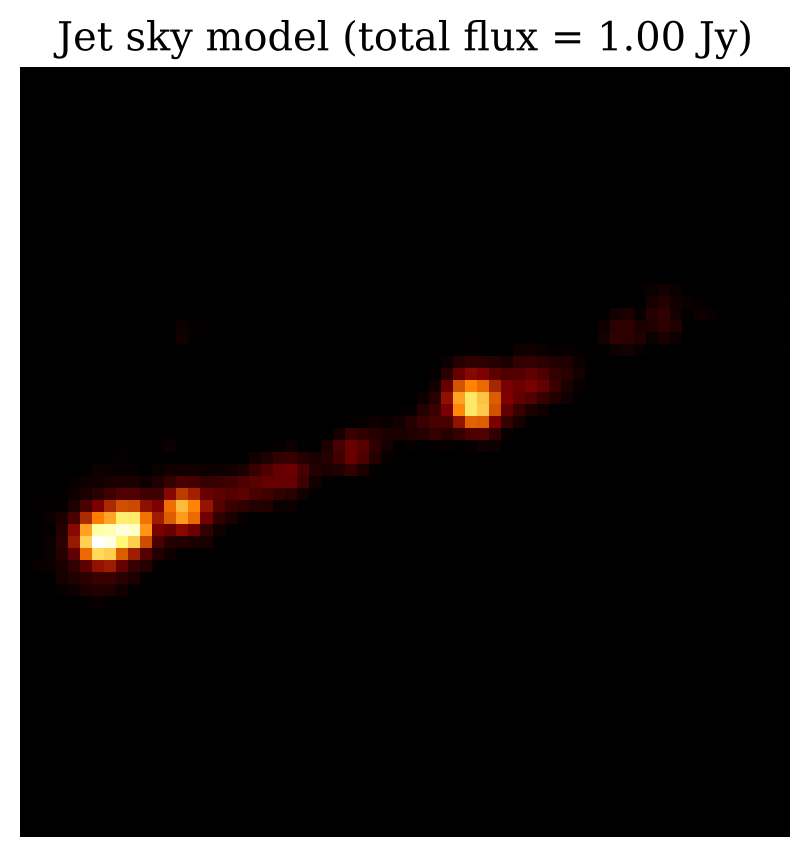

In [3]:
# the model is looked for next to the notebook, then in the case's toy-model/ folder
import os
JET_MODEL_PATH = next((p for p in ('jet_model.txt', '../toy-model/jet_model.txt') if os.path.exists(p)), 'jet_model.txt')
try:
    im_jet = eh.image.load_txt(JET_MODEL_PATH)
    print(f"'{JET_MODEL_PATH}' loaded successfully. Total flux: {im_jet.total_flux():.3f} Jy")
except FileNotFoundError:
    print("WARNING: 'jet_model.txt' not found. Using a point source as an emergency fallback.")
    print("         The conclusions of this notebook about 'extended structure' will NOT be valid")
    print("         until you provide a real jet model.")
    npix_fallback, fov_fallback = 64, 1000 * eh.RADPERUAS
    empty_fallback = eh.image.make_empty(npix_fallback, fov_fallback, 12.0, 4.0, rf=5e9, source='FallbackPoint', mjd=58849)
    im_jet = empty_fallback.add_gauss(1.0, [50 * eh.RADPERUAS, 50 * eh.RADPERUAS, 0, 0, 0])

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(im_jet.imvec.reshape(im_jet.ydim, im_jet.xdim), cmap='afmhot')
ax.set_title(f"Jet sky model (total flux = {im_jet.total_flux():.2f} Jy)")
ax.axis('off')
save_fig(fig, '01_jet_model')
plt.show()

### 2.2 Observing parameters (C-band, 5 GHz) and the ideal observation

We choose 5 GHz because it's a standard, realistic band for the EVN (C-band), and because extragalactic compact sources tend to be bright and easy to detect at this frequency even with moderate SNR.

- `nu`: observing frequency (Hz).
- `bw`: bandwidth (Hz).
- `tint`: scan length (seconds). The correlator records one visibility per baseline every `avg_time` seconds, so each scan yields `tint / avg_time` visibility points per baseline (before elevation cuts).
- `tadv`: time between the start of consecutive scans (seconds), which must include antenna slewing and settling time.
- `tstart`, `tstop`: observing window in **UTC hours** on the observing date (the MJD of the model image), because `observe()` uses `timetype='UTC'` by default (pass `timetype='GMST'` to give the window in sidereal time instead).
- `avg_time`: correlator integration time (seconds). The correlator records one visibility per baseline every `avg_time` seconds. With `tint=120` s and `avg_time=30` s, each scan produces `120/30 = 4` visibility samples per baseline, before elevation cuts.

In VLBI, confusing seconds with hours or Hz with GHz is, by a wide margin, the #1 beginner mistake, as it produces results that *look* reasonable but are completely wrong. Always double-check the units of every parameter before you trust a simulation.

We simulate the jet first under **ideal** conditions (`add_th_noise=False`, `ampcal=True`, `phasecal=True`), our error-free reference for everything that follows.


> **How many visibilities will I get?** With the EVN + AVN + SKA-Mid array (20 stations: 11 EVN, 4 SKA-Mid, 5 AVN) the theoretical maximum is $N(N-1)/2 = 190$ baselines. In a 6-hour window with `tadv=600` s there are 36 nominal scans. With `tint=120` s, `ehtim` produces **one visibility per baseline and scan** (the scan is the integration), so the maximum is $36 \times 190 = 6{,}840$ rows in `obs.data`; the number printed below is smaller because some baselines are below the elevation limit in some scans (African/SKA-Mid, European and Asian stations have very different visibility windows for a given source). > **Why there is no `obs.add_all()` call.** `add_all()` pre-computes every closure table (bispectra, closure phases, closure amplitudes and their diagonalised versions). With 20 stations (1140 triangles per scan) this takes more than 1 GB per dataset, and every copy of the dataset (e.g. inside self-calibration) duplicates it, which quickly exhausts the memory of a Colab session. The imager computes the closure quantities it needs by itself, so we simply skip it. (Since each 120 s scan gives one visibility per baseline, coherent averaging with `avg_time` = 30 s would not change these data anyway.)

> **RADIOBLOCKS scenarios — where does this fit?** This ideal observation (`add_th_noise=False`, `ampcal=True`, `phasecal=True`) contains *no* errors at all, so it is **not** one of the RADIOBLOCKS scenarios: it is the error-free **reference** against which Scenario A (thermal noise only), Scenario B (thermal noise + gain + generic phase errors, Section 3.1) and Scenario C (thermal noise + gain + structured atmospheric corruptions (ionospheric + tropospheric), Section 3.5) are compared.

In [4]:
# --- Observing parameters: EVN C-band (5 GHz) ---
nu  = 5e9      # observing frequency [Hz]      (5 GHz)
bw  = 256e6      # bandwidth [Hz]                (256 MHz)
tint  = 120    # integration time per scan [s]
tadv  = 600    # time advance between scans [s]
tstart, tstop = 6, 12   # observing window [UTC hours on the model's MJD; ehtim default timetype='UTC']
avg_time = 30  # coherent-averaging time [s] (no effect here: one visibility per 120 s scan, see the note above)

print(f"Observing frequency: {nu/1e9:.1f} GHz   (lambda ~ {3e8/nu*100:.2f} cm)")
print(f"Bandwidth:            {bw/1e9:.1f} GHz")
print(f"Observing window:     {tstart}h - {tstop}h UTC, scan every {tadv}s ({tint}s integration)")

print("\nSimulating IDEAL observation (no errors)...")
obs_jet_ideal = im_jet.observe(
    array_comb, tint, tadv, tstart, tstop, bw,
    sgrscat=False, ampcal=True, phasecal=True, ttype='direct', add_th_noise=False
)
obs_jet_ideal.rf = nu

print(f"Visibility points (ideal, EVN + AVN + SKA-Mid): {len(obs_jet_ideal.data)}")

Observing frequency: 5.0 GHz   (lambda ~ 6.00 cm)
Bandwidth:            0.3 GHz
Observing window:     6h - 12h UTC, scan every 600s (120s integration)

Simulating IDEAL observation (no errors)...
Generating empty observation file . . . 


Producing clean visibilities from image with direct FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 


Visibility points (ideal, EVN + AVN + SKA-Mid): 6376


### 2.3 Visualizing the uv-coverage

The uv-coverage is, literally, the set of points in the Fourier plane that your array is able to sample over the course of the observation (as the Earth rotates, each antenna pair traces out an elliptical arc). **The more points, and the more uniformly distributed they are, the better you'll be able to reconstruct the image**, the VLBI equivalent of having more pixels of information in your "camera."

To see what the African stations (AVN **and SKA-Mid**) actually contribute, we also simulate the **same ideal jet observation on the EVN alone (no SKA)**, purely for this comparison plot (we won't reuse `obs_evn_ideal_compare` later, as the rest of the notebook works with the EVN + AVN + SKA-Mid array, `obs_jet_ideal`).

Remember that the visibility at $(-u, -v)$ is the complex conjugate of the visibility at $(u, v)$ (because the sky image is a real-valued function), which is why we always plot the points together with their mirror reflections.

Generating empty observation file . . . 
Producing clean visibilities from image with direct FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 


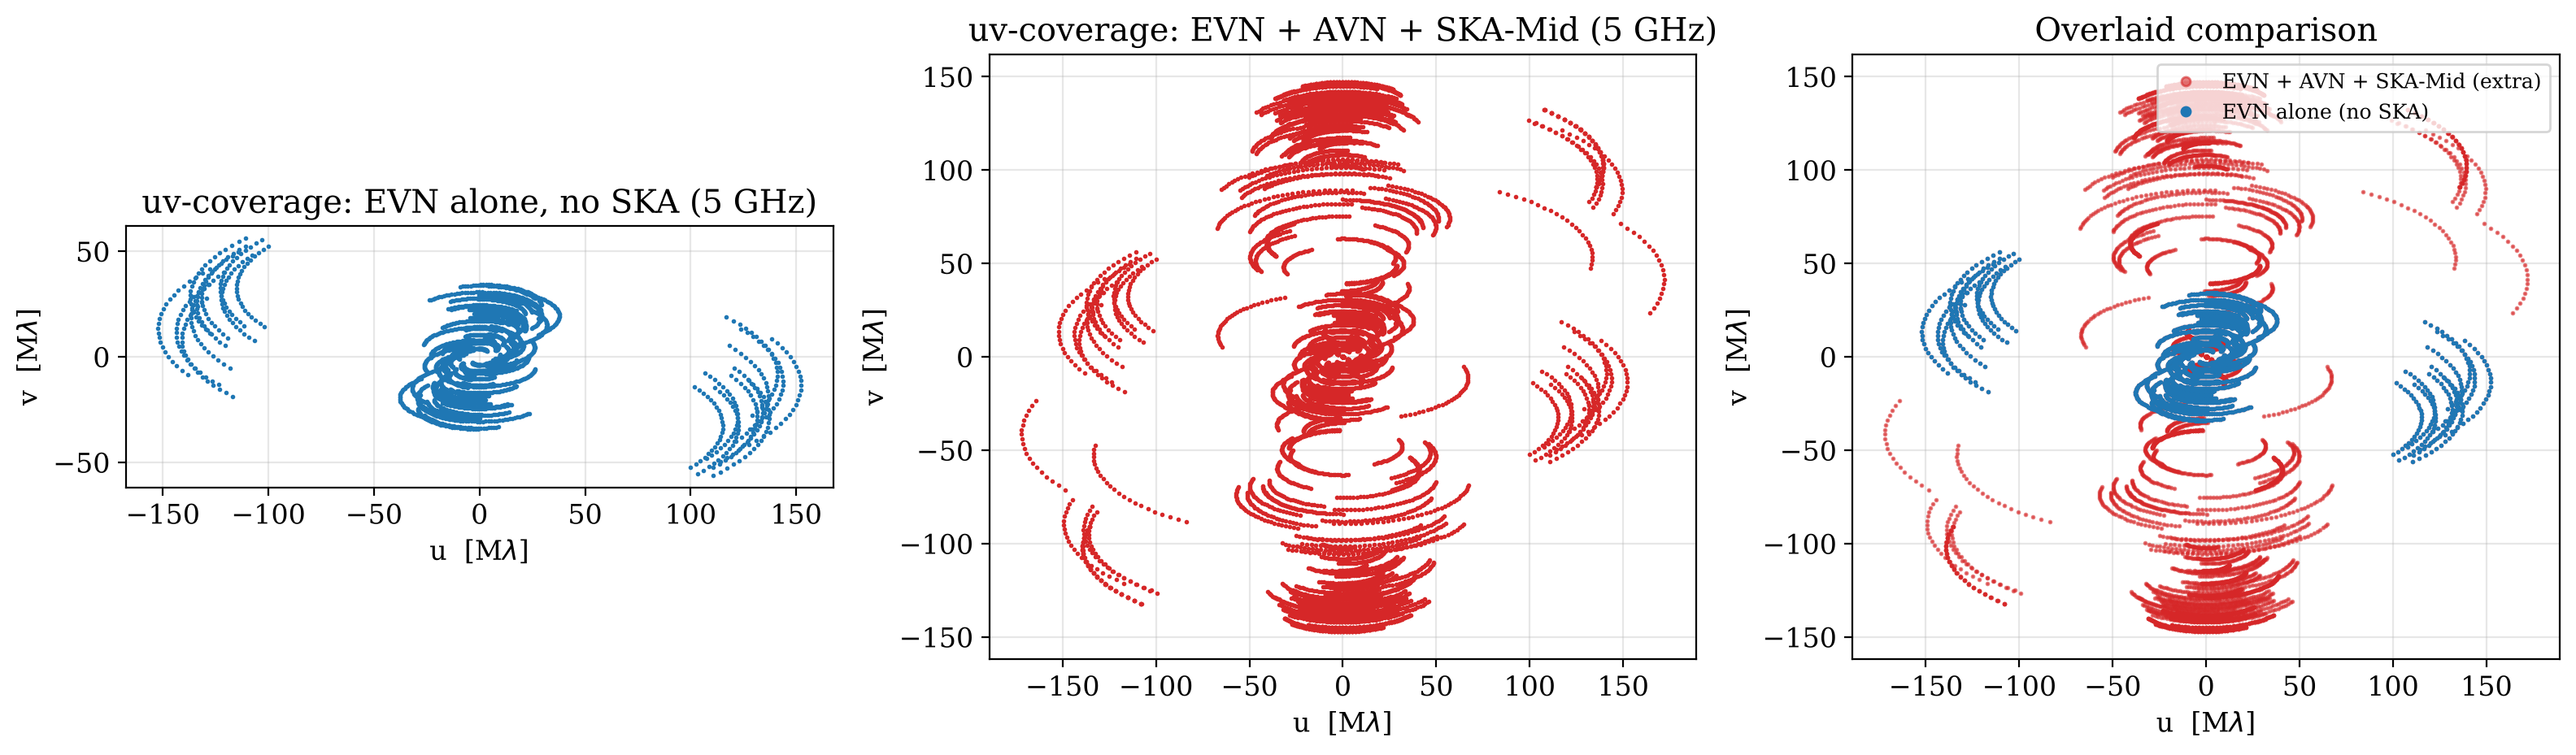

EVN alone (no SKA) points: 1860  |  EVN + AVN + SKA-Mid points: 6376  (x3.4)
Notice how many NEW points (in red) the AVN + SKA-Mid stations contribute, especially in the
north-south direction of the uv-plane, where the EVN alone has poorer coverage.


In [5]:
obs_evn_ideal_compare = im_jet.observe(
    array_evn, tint, tadv, tstart, tstop, bw,
    sgrscat=False, ampcal=True, phasecal=True, ttype='direct', add_th_noise=False
)
obs_evn_ideal_compare.rf = nu

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

u_evn, v_evn = obs_evn_ideal_compare.data['u'], obs_evn_ideal_compare.data['v']
axes[0].plot(u_evn / 1e6, v_evn / 1e6, '.', color='tab:blue', markersize=2)
axes[0].plot(-u_evn / 1e6, -v_evn / 1e6, '.', color='tab:blue', markersize=2)  # conjugate baselines
axes[0].set_title("uv-coverage: EVN alone, no SKA (5 GHz)")
axes[0].set_xlabel(r'u  [M$\lambda$]')
axes[0].set_ylabel(r'v  [M$\lambda$]')
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect('equal')

u_comb, v_comb = obs_jet_ideal.data['u'], obs_jet_ideal.data['v']
axes[1].plot(u_comb / 1e6, v_comb / 1e6, '.', color='tab:red', markersize=2)
axes[1].plot(-u_comb / 1e6, -v_comb / 1e6, '.', color='tab:red', markersize=2)
axes[1].set_title("uv-coverage: EVN + AVN + SKA-Mid (5 GHz)")
axes[1].set_xlabel(r'u  [M$\lambda$]')
axes[1].set_ylabel(r'v  [M$\lambda$]')
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')

axes[2].plot(u_comb / 1e6, v_comb / 1e6, '.', color='tab:red', markersize=2, label='EVN + AVN + SKA-Mid (extra)', alpha=0.6)
axes[2].plot(-u_comb / 1e6, -v_comb / 1e6, '.', color='tab:red', markersize=2, alpha=0.6)
axes[2].plot(u_evn / 1e6, v_evn / 1e6, '.', color='tab:blue', markersize=2, label='EVN alone (no SKA)')
axes[2].plot(-u_evn / 1e6, -v_evn / 1e6, '.', color='tab:blue', markersize=2)
axes[2].set_title("Overlaid comparison")
axes[2].set_xlabel(r'u  [M$\lambda$]')
axes[2].set_ylabel(r'v  [M$\lambda$]')
axes[2].grid(True, alpha=0.3)
axes[2].set_aspect('equal')
axes[2].legend(markerscale=4, loc='upper right', fontsize=9)

plt.tight_layout()
save_fig(fig, '02_uv_coverage_EVN_noSKA_vs_EVN_AVN_SKAMid')
plt.show()

print(f"EVN alone (no SKA) points: {len(obs_evn_ideal_compare.data)}  |  EVN + AVN + SKA-Mid points: {len(obs_jet_ideal.data)}  "
      f"(x{len(obs_jet_ideal.data)/len(obs_evn_ideal_compare.data):.1f})")
print("Notice how many NEW points (in red) the AVN + SKA-Mid stations contribute, especially in the")
print("north-south direction of the uv-plane, where the EVN alone has poorer coverage.")

> **Question to think about:** the angular resolution of your array is set by the **longest** (projected) baseline: $\theta \sim \lambda / B_{max}$. But the quality or fidelity of the *image* (not just the theoretical resolution) depends on how well-filled the uv-plane is overall. Why do you think both of these matter separately?

<details>
<summary><b> Answer (click to expand)</b></summary>
<br>

The longest baseline sets a hard limit on the *finest* detail you could ever resolve, in the same way that the diameter of a telescope mirror sets its diffraction limit, telling you the smallest angular scale your array is sensitive to, in principle. But $\theta \sim \lambda/B_{max}$ says nothing about how faithfully you can reconstruct everything *above* that scale. If most of your baselines cluster around just a few lengths and orientations, you'll have deep, well-sampled holes in the uv-plane; the corresponding spatial frequencies are essentially unconstrained, and the imaging algorithm has to interpolate or guess across them using priors and regularization, often introducing artifacts (extra sidelobes, spurious extended emission, or oversmoothed sharp features). An array with a shorter $B_{max}$ but more uniform, isotropic uv-coverage can sometimes produce a more trustworthy image than one with a longer $B_{max}$ but large gaps. This is exactly why adding the AVN and SKA-Mid, even without changing the longest EVN baseline by much, measurably improves how cleanly we can fill in the source structure between bright spots.

</details>

## 3. Realistic errors and visibility corruption

Real observations are affected by thermal noise, gain errors, phase drifts, etc. Here we inject these errors into our jet simulation and quantify the resulting degradation.

### 3.1 The three types of error we will inject

| Parameter | What it simulates | Physical effect |
|---|---|---|
| `add_th_noise=True` | Receiver thermal noise | Depends on each antenna's SEFD: less sensitive antennas (higher SEFD) add more noise |
| `gain_offset`, `gainp` | Per-antenna amplitude errors | `gain_offset` is a systematic offset (e.g. 0.15 = 15%) and `gainp` is an additional random per-antenna error |
| `phasecal=False` | Atmospheric phase errors | Left uncorrected, simulates the effect of tropospheric/ionospheric turbulence on each antenna |

> **Syntax note for 1.2.10:** all of these parameters (`gain_offset`, `gainp`, `phasecal`, `elevmin`, `add_th_noise`) are direct arguments of `Image.observe()`, confirmed against the function's actual signature. No extra post-processing step is needed to inject them.

The three controls below are deliberately exposed as variables, with a reasonable range to explore noted next to each one. We apply the same `elevmin` to both the ideal and the corrupted observation, so that any comparison between them isolates the effect of the injected errors rather than a difference in elevation cutoff.

### RADIOBLOCKS scenarios: A vs. B vs. C

The error combinations used in this notebook follow the structure of the **RADIOBLOCKS** project:

| RADIOBLOCKS scenario | Errors included | `observe()` settings in `ehtim` | In this notebook |
|---|---|---|---|
| *(Reference, not a scenario)* | None | `add_th_noise=False`, `ampcal=True`, `phasecal=True` | `obs_jet_ideal` (Section 2.2) |
| **Scenario A** | **Thermal noise only** | `add_th_noise=True`, `ampcal=True`, `phasecal=True` | `obs_jet_thA` (Section 3.1) and its reconstruction in Section 4.3 |
| **Scenario B** | **Thermal noise + gain errors + generic phase errors** | `add_th_noise=True`, `ampcal=False` + `gain_offset`, `gainp`, `phasecal=False` (ehtim's own random, per-timestamp phase) | `obs_jet_err` (Section 3.1) and everything derived from it (self-cal, Section 4 reconstructions) |
| **Scenario C** | **Thermal noise + gain errors + structured atmospheric corruptions (ionospheric + tropospheric phase drift)** | Same `add_th_noise=True`, `ampcal=False`, `gain_offset`, `gainp` as Scenario B, but `phasecal=True` (ehtim injects no phase noise of its own) + ported atmospheric corruptions (ionospheric dTEC + tropospheric delay random walks) applied afterwards | `obs_jet_errC` (Section 3.5) and everything derived from it (self-cal, Section 4 reconstructions) |

> **Rule of thumb:** if the only corruption in a dataset is receiver thermal noise, it belongs to **Scenario A**. As soon as station gains (amplitude) *and* phases are also corrupted on top of the thermal noise, it belongs to **Scenario B** (using `ehtim`'s own generic, per-timestamp random phase) or **Scenario C** (same gain-error budget as B, but physically structured atmospheric corruptions (ionospheric dTEC + tropospheric delay drifts) instead, Section 3.5). B and C are deliberately directly comparable: same thermal noise, same gain errors, different phase-error physics — any difference between their reconstructions in Section 4 isolates the effect of *how* the phase error is structured in time.
>
> Note that in `ehtim` the thermal-noise-only case (Scenario A) is obtained by keeping `ampcal=True` and `phasecal=True` while switching `add_th_noise=True` on. Scenario B needs `gain_offset`, `gainp` and `phasecal=False`. Scenario C needs the same `gain_offset`/`gainp` but `phasecal=True`, plus the custom atmospheric corruptions (ionospheric dTEC + tropospheric delay) applied after `observe()` (Section 3.5).

In [6]:
# =====================================================================
# CONTROLS TO EXPERIMENT WITH: change these variables and re-run
# the cells below to see how the data degradation changes.
# =====================================================================
gain_offset_val = 0.15   # Systematic amplitude gain error (e.g. 0.15 = 15%).      Reasonable range: 0.0 - 0.3
gainp_val       = 0.10   # Random amplitude gain error (per antenna).              Reasonable range: 0.0 - 0.2
elevation_min   = 10.0   # Minimum observing elevation [degrees].                  Reasonable range: 5 - 20
# =====================================================================

# ---------------------------------------------------------------------
# RADIOBLOCKS SCENARIO B: thermal noise + gain errors + phase errors.
# (The thermal-noise-only SCENARIO A dataset is simulated just below.)
# ---------------------------------------------------------------------
print("Simulating CORRUPTED observation of the jet (RADIOBLOCKS Scenario B)...")
obs_jet_err = im_jet.observe(
    array_comb, tint, tadv, tstart, tstop, bw,
    sgrscat=False, ttype='direct', elevmin=elevation_min,
    add_th_noise=True,                                            # thermal noise
    ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val,   # amplitude errors
    phasecal=False                                                # leaves atmospheric phase errors uncorrected
)
obs_jet_err.rf = nu

print(f"Visibility points (ideal):     {len(obs_jet_ideal.data)}")
print(f"Visibility points (corrupted, Scenario B): {len(obs_jet_err.data)}")

# ---------------------------------------------------------------------
# RADIOBLOCKS SCENARIO A: thermal noise ONLY.
# Same array, scans, elevation cut and bandwidth as Scenario B, but the stations are
# perfectly calibrated (ampcal=True, phasecal=True): the only corruption is the
# receiver thermal noise, so there are no gain or phase errors to remove.
# ---------------------------------------------------------------------
print("\nSimulating THERMAL-NOISE-ONLY observation of the jet (RADIOBLOCKS Scenario A)...")
obs_jet_thA = im_jet.observe(
    array_comb, tint, tadv, tstart, tstop, bw,
    sgrscat=False, ttype='direct', elevmin=elevation_min,
    add_th_noise=True,                 # thermal noise (the only error)
    ampcal=True, phasecal=True         # no gain or phase errors
)
obs_jet_thA.rf = nu

print(f"Visibility points (thermal only, Scenario A): {len(obs_jet_thA.data)}")
print(f"Median visibility SNR (Scenario A): {np.median(np.abs(obs_jet_thA.data['vis']) / obs_jet_thA.data['sigma']):.1f}")


Simulating CORRUPTED observation of the jet (RADIOBLOCKS Scenario B)...
Generating empty observation file . . . 


Producing clean visibilities from image with direct FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 
   Applying gain corruption: ampcal-->False
   Applying atmospheric phase corruption: phasecal-->False
Adding thermal noise to data . . . 


Visibility points (ideal):     6376
Visibility points (corrupted, Scenario B): 6376

Simulating THERMAL-NOISE-ONLY observation of the jet (RADIOBLOCKS Scenario A)...
Generating empty observation file . . . 


Producing clean visibilities from image with direct FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 
Adding thermal noise to data . . . 


Visibility points (thermal only, Scenario A): 6376
Median visibility SNR (Scenario A): 182.3


### 3.2 Example illustrating how self-calibration mitigates corruptions in realistic data

Self-calibration uses a model of the source to solve for the per-antenna gains that best explain the observed data, and applies them to correct the visibilities.
In this example, the true jet model has been used to self-calibrate in phase and amplitude (default values) to illustrate the concept — in a real observation you would use the model from a previous imaging iteration, not the true sky.

> **Does self-calibration using the true model remove the jet signal?** No. Self-calibration solves for per-antenna *gain* corrections (amplitude and phase scalings), not for the source structure itself. Even when the true model is used, the optimized gains absorb only the antenna-based corruptions, not the source signal. Verification: in this simulation the mean visibility amplitude changes from the corrupted value to within 0.05% of the ideal value after self-cal — the source structure is fully preserved.

> **Performance warning.** `sc.self_cal()` defaults to `ttype='direct'` (exact Fourier transform) and, by default, solves an **independent BFGS optimization for every unique timestamp** in the observation. With a large combined array and many timestamps, this can take several minutes or more, depending on your CPU, if called with no extra arguments.
>
> **Recommended setup, in 3 steps:**
> 1. `obs.add_scans()`: groups timestamps into *scans* (this needs to be called explicitly; without it, `obs.scans` stays `None` and `scan_solutions` has no real grouping to operate on).
> 2. `scan_solutions=True`: solves for **one gain per antenna per scan**, instead of one per individual timestamp. This is reasonable since within a short scan antenna gain shouldn't vary much.
> 3. `ttype='fast'`: consistent with the rest of the notebook, avoids the (much more expensive) exact DFT at every evaluation of the optimizer.
>
> With this combination, a self-cal run on a comparable array and number of scans took ~46 s on a modest machine; without these three changes, the same kind of call did not finish in over 100 s. If your machine is slow, you can temporarily shorten `tstop` (fewer scans) just to verify the pipeline runs, then restore it for the real run.

In [7]:
obs_jet_err.add_scans()   # essential for scan_solutions to group correctly

t0 = time.time()
cal_jet = sc.self_cal(obs_jet_err, im_jet, ttype='fast', scan_solutions=True, processes=1)
print(f"Self-calibration completed in {time.time() - t0:.1f} s")

No stations specified in self cal: defaulting to calibrating all stations!
Computing the Model Visibilities with fast Fourier Transform...
Producing clean visibilities from image with fast FT . . . 


Using Multiprocessing with 1 Processes


Scan 01/36 : [                              ]2%

Scan 02/36 : [-                             ]5%

Scan 03/36 : [--                            ]8%

Scan 04/36 : [---                           ]11%

... (29 outputs left out)

Scan 34/36 : [----------------------------  ]94%

Scan 35/36 : [----------------------------- ]97%

Scan 36/36 : [------------------------------]100%


self_cal time: 43.805680 s
Self-calibration completed in 44.2 s


### 3.3 Visualizing the degradation: visibility amplitude vs. uv-distance

This is probably the single most-used diagnostic plot in the entire VLBI workflow: visibility amplitude as a function of uv-distance (`sqrt(u² + v²)`). For a source with no structure (a point), the amplitude would be flat. For a source with extended structure (like our jet), the amplitude falls off and oscillates in a pattern set by the source's morphology: what you see here is literally the interference pattern produced by the jet's spatial structure.

Each comparison (ideal vs. Scenario A, ideal vs. Scenario B, ideal vs. self-calibrated Scenario B) gets its own panel, to avoid the overplotting and colour confusion of putting all the series on the same axes.

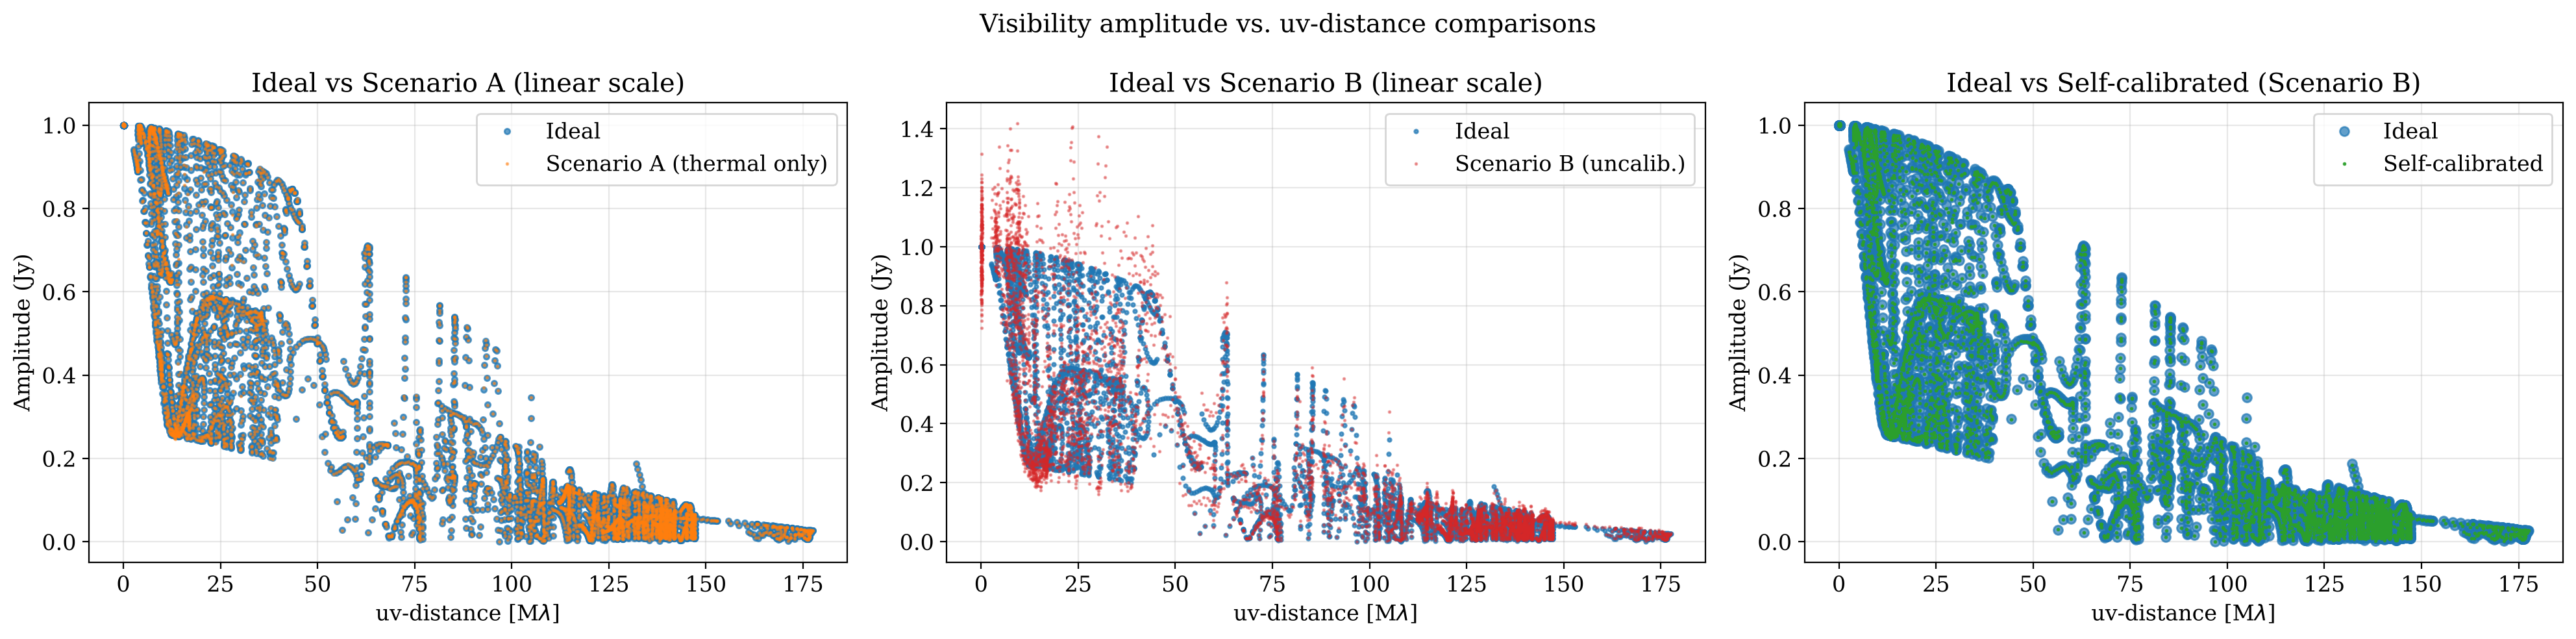

The left panel shows Scenario A (thermal noise only): the data follow the ideal pattern and only
show a random scatter set by the SNR. The middle panel shows Scenario B (thermal noise + gain + phase
errors), where the additional scatter introduced by the systematic errors is clearly larger. The right
panel compares the ideal pattern to the self-calibrated Scenario B data, showing how much of the ideal
pattern is recovered.


In [8]:
uv_ideal = np.sqrt(obs_jet_ideal.data['u']**2 + obs_jet_ideal.data['v']**2)
uv_err   = np.sqrt(obs_jet_err.data['u']**2   + obs_jet_err.data['v']**2)
uv_cal   = np.sqrt(cal_jet.data['u']**2       + cal_jet.data['v']**2)

amp_ideal = np.abs(obs_jet_ideal.data['vis'])
amp_err = np.abs(obs_jet_err.data['vis'])
amp_cal = np.abs(cal_jet.data['vis'])

# Scenario A (thermal noise only)
uv_thA  = np.sqrt(obs_jet_thA.data['u']**2 + obs_jet_thA.data['v']**2)
amp_thA = np.abs(obs_jet_thA.data['vis'])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Panel 1: Ideal vs Scenario A (thermal noise only)
axes[0].plot(uv_ideal / 1e6, amp_ideal, '.', color='tab:blue', alpha=0.7, markersize=6, label='Ideal')
axes[0].plot(uv_thA / 1e6, amp_thA, '.', color='tab:orange', alpha=0.5, markersize=2, label='Scenario A (thermal only)')
axes[0].set_ylabel('Amplitude (Jy)')
axes[0].set_xlabel(r'uv-distance [M$\lambda$]')
axes[0].set_title('Ideal vs Scenario A (linear scale)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: Ideal vs Scenario B (thermal + gain + phase, uncalibrated)
axes[1].plot(uv_ideal / 1e6, amp_ideal, '.', color='tab:blue', alpha=0.7, markersize=4, label='Ideal')
axes[1].plot(uv_err / 1e6, amp_err, '.', color='tab:red', alpha=0.4, markersize=2, label='Scenario B (uncalib.)')
axes[1].set_ylabel('Amplitude (Jy)')
axes[1].set_xlabel(r'uv-distance [M$\lambda$]')
axes[1].set_title('Ideal vs Scenario B (linear scale)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Ideal vs Self-calibrated (Scenario B after self-cal)
# Ideal is drawn larger (markersize=10) and self-calibrated smaller (markersize=2) so both colours remain visible.
axes[2].plot(uv_ideal / 1e6, amp_ideal, '.', color='tab:blue', alpha=0.7, markersize=10, label='Ideal')
axes[2].plot(uv_cal / 1e6, amp_cal, '.', color='tab:green', alpha=0.9, markersize=2, label='Self-calibrated')
axes[2].set_ylabel('Amplitude (Jy)')
axes[2].set_xlabel(r'uv-distance [M$\lambda$]')
axes[2].set_title('Ideal vs Self-calibrated (Scenario B)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Visibility amplitude vs. uv-distance comparisons', fontsize=14)
plt.tight_layout()
save_fig(fig, '03_amplitude_vs_uvdistance_A_B_selfcal')
plt.show()

print("The left panel shows Scenario A (thermal noise only): the data follow the ideal pattern and only")
print("show a random scatter set by the SNR. The middle panel shows Scenario B (thermal noise + gain + phase")
print("errors), where the additional scatter introduced by the systematic errors is clearly larger. The right")
print("panel compares the ideal pattern to the self-calibrated Scenario B data, showing how much of the ideal")
print("pattern is recovered.")


### 3.4 Why amplitude falls off with uv-distance: resolved-out flux

The amplitude-vs-uv-distance plot above isn't just a diagnostic curve; it tells you directly how much of your source's flux a given baseline can actually "see." A visibility is the Fourier transform of the sky brightness distribution, so each point $(u,v)$ measures the source's structure at the angular scale $\theta \sim 1/\sqrt{u^2+v^2}$. **Short baselines** (small uv-distance) are sensitive to *large-scale* structure and recover close to the source's *total* flux density. **Long baselines** (large uv-distance) are only sensitive to *small-scale* structure, and if the source has no compact, sharp-edged components at that angular scale, the corresponding visibility amplitude drops toward zero, even though the source is still there and still bright. This is what radio astronomers mean by emission being **"resolved out"**: it is not lost or undetected, it is just spread over a region too large for that particular baseline to be sensitive to.

This has very concrete consequences when planning real observations: if your science target is an extended, diffuse structure (like a wide jet or a lobe), adding very long baselines mostly helps you study its compact, bright knots, while the diffuse envelope will simply disappear from those baselines' amplitudes. Conversely, if you only have short baselines, you'll recover the total flux well but won't be able to resolve any fine, compact structure at all. A well-designed array (and well-designed observing proposal) needs *both* short and long baselines, precisely so it can recover flux at all scales the source actually has.

Let's check this quantitatively for our jet: how much of the total model flux is actually contained, on average, in the shortest vs. longest baselines of our ideal observation?

In [9]:
amp_ideal = np.abs(obs_jet_ideal.data['vis'])
short_mask = uv_ideal < np.percentile(uv_ideal, 10)   # shortest 10% of baselines
long_mask  = uv_ideal > np.percentile(uv_ideal, 90)    # longest 10% of baselines

print(f"True total flux of the jet model:         {im_jet.total_flux():.3f} Jy")
print(f"Mean |V| on the shortest 10% of baselines: {amp_ideal[short_mask].mean():.3f} Jy  "
      f"({100*amp_ideal[short_mask].mean()/im_jet.total_flux():.0f}% of total flux)")
print(f"Mean |V| on the longest 10% of baselines:  {amp_ideal[long_mask].mean():.3f} Jy  "
      f"({100*amp_ideal[long_mask].mean()/im_jet.total_flux():.0f}% of total flux)")
print("\nThe drop between these two numbers IS the resolved-out flux: extended jet emission that")
print("the longest baselines simply cannot see, because it has no structure at that fine an angular scale.")

True total flux of the jet model:         1.000 Jy
Mean |V| on the shortest 10% of baselines: 0.903 Jy  (90% of total flux)
Mean |V| on the longest 10% of baselines:  0.036 Jy  (4% of total flux)

The drop between these two numbers IS the resolved-out flux: extended jet emission that
the longest baselines simply cannot see, because it has no structure at that fine an angular scale.


> **A closer look at closure quantities themselves.** Everything in Sections 3.3-3.4 plots raw visibility amplitude, which is exactly the quantity antenna-based gain errors corrupt. If you want to see the robustness argument from Section 4.0 directly in the data (rather than just in the final reconstructed image), `ehtim` lets you plot individual closure phases and closure amplitudes for a chosen triangle/quadrangle of stations with `obs.plot_cphase(site1, site2, site3)` and `obs.plot_camp(site1, site2, site3, site4)`. Try `obs_jet_ideal.plot_cphase('EF','HH','WB')` vs. `obs_jet_err.plot_cphase('EF','HH','WB')` (swap in three real station codes from `array_comb.tarr['site']`): just add a new cell below and paste those lines in. The closure-phase traces of the two datasets should track each other closely (the jet's closure phases are not zero, because the source is not symmetric, but they are the *same* in both datasets up to thermal noise), while the raw visibility phases on the same baselines would not. Section 5 does this comparison for every triangle at once.

### 3.5 RADIOBLOCKS Scenario C: structured atmospheric corruptions: ionospheric (dTEC) + tropospheric (delay) phase screens

Scenario B's phase errors come from `phasecal=False`, i.e. `ehtim`'s built-in random, independent-per-timestamp per-station phase. **Scenario C** keeps exactly the same thermal-noise and gain-error budget as Scenario B (`add_th_noise=True`, `ampcal=False`, the same `gain_offset_val`/`gainp_val`), but replaces that generic phase with **physically structured, time-correlated atmospheric corruptions** (an ionospheric and a tropospheric phase screen), ported from the corruption script `preparations_new.py` (originally written for CASA and an SKA-Low VLBI measurement set).

**What the original script does.** For every station it builds two Brownian-motion (random-walk) time series, one for the differential ionospheric content **dTEC** and one for a residual non-dispersive **delay** (troposphere, clocks), sampled every few time steps and linearly interpolated in between. The visibility on baseline $i$–$j$ is then multiplied by $e^{\,i(\phi_i-\phi_j)}$ with

$$\phi_i(t,\nu) \;=\; \underbrace{\frac{K\,\mathrm{dTEC}_i(t)}{\nu}}_{\text{dispersive (ionosphere), } \propto 1/\nu} \;+\; \underbrace{2\pi\,\nu\,\tau_i(t)}_{\text{non-dispersive delay (troposphere)}}$$

**What changes when moving it into this notebook:**

| Original script (CASA / MS) | This notebook (`ehtim`) |
|---|---|
| Edits the `DATA` column of a Measurement Set, shape `(pol, chan, row)` | Edits `obs.data['vis']` (and `qvis`, `uvis`, `vvis`): **one channel** at `obs.rf` |
| dTEC in arbitrary units, constant `8.3769/500` tuned for ~150 MHz | dTEC in **TECU**, $\phi = 8.448\times10^{9}\,\mathrm{dTEC}/\nu$: 1 TECU = **1.7 rad at 5 GHz** (vs. ~56 rad at 150 MHz) |
| Delay term $2\pi\tau(\nu-\nu_0)$: a slope *across the band*, which is exactly zero in a single-channel dataset | Absolute residual delay $2\pi\nu\tau$ evaluated at the observing frequency |
| Hard-coded `randn(6)` (6 antennas) and `nTime` must be divisible by 10 | Any number of stations; a new random-walk knot every `knot_s` seconds |


> **Two flavours of Scenario C in this project.** The atmospheric corruptions below (ionospheric + tropospheric) multiply each visibility by a single phase factor per station, so they are purely antenna-based: closure quantities and self-calibration remove it exactly (the check below verifies this). The *delivery* notebooks of the project (and the LBA 250 MHz one) use an extended version that also averages the phase over the frequency channels of the band and over the duration of the scan. That average is **not** antenna-based (it decorrelates the amplitude), so it survives self-calibration and closure quantities, and it is the harder test.

> **Scenario C, concretely.** The cell below observes the jet with `add_th_noise=True`, `ampcal=False`, `gain_offset=gain_offset_val`, `gainp=gainp_val` — identical to Scenario B — but with `phasecal=True`, so `ehtim` injects no phase noise of its own. The dTEC + delay random walk is then applied on top as the only source of phase error. Because B and C share the same thermal-noise and gain-error budget, any difference between their Section 4 reconstructions isolates the effect of *how* the phase corruption is structured in time (uncorrelated per-timestamp noise vs. correlated atmospheric corruptions (ionospheric + tropospheric drifts)), not a difference in how much error was injected.




In [10]:
# =====================================================================
# CONTROLS TO EXPERIMENT WITH
# =====================================================================
dtec_step_tecu = 0.3     # std of each random-walk step of dTEC [TECU]       (0.3 TECU ~ 0.5 rad at 5 GHz)
delay_step_ns  = 0.02    # std of each random-walk step of the delay [ns]    (0.02 ns ~ 0.6 rad at 5 GHz)
knot_s         = 600.0   # time between random-walk knots [s] (linear interpolation in between)
use_dtec       = True    # include the dispersive (1/nu) ionospheric term
use_delay      = True    # include the residual-delay term
SCREEN_SEED    = 42      # set to None for a different realisation each run
# =====================================================================

IONO_RAD_HZ_PER_TECU = 8.4479745e9   # phi[rad] = 8.448e9 * dTEC[TECU] / nu[Hz]


def simulate_station_screens(sites, t_hours, dtec_step=0.3, delay_step_ns=0.02,
                             knot_s=600.0, seed=None):
    """Per-station Brownian-motion dTEC [TECU] and delay [ns], linearly interpolated in time.

    Same idea as the CASA script: a random walk sampled on a coarse grid of knots
    (every `knot_s` seconds), linearly interpolated onto the observation timestamps.
    Returns arrays of shape (n_sites, n_times).
    """
    rng = np.random.default_rng(seed)
    t_s = (np.asarray(t_hours, dtype=float) - np.min(t_hours)) * 3600.0
    n_knots = int(np.ceil(t_s.max() / knot_s)) + 2
    knots_t = np.arange(n_knots) * knot_s
    n_sites = len(sites)
    dtec_knots  = np.cumsum(rng.normal(0.0, dtec_step,     (n_sites, n_knots)), axis=1)
    delay_knots = np.cumsum(rng.normal(0.0, delay_step_ns, (n_sites, n_knots)), axis=1)
    dtec  = np.array([np.interp(t_s, knots_t, dtec_knots[i])  for i in range(n_sites)])
    delay = np.array([np.interp(t_s, knots_t, delay_knots[i]) for i in range(n_sites)])
    return dtec, delay


def apply_dtec_delay(obs, nu=None, dtec_step=0.3, delay_step_ns=0.02, knot_s=600.0,
                     use_dtec=True, use_delay=True, seed=None, return_screens=False):
    """Multiply every visibility by exp(i*(phi_1 - phi_2)) with a per-station dTEC + delay phase.

    Works on a COPY of `obs` (the input is not modified). The same phase is applied to all
    Stokes products, since it is an antenna-based (direction-independent) error.
    """
    obs_out = obs.copy()
    data = obs_out.data
    nu = obs.rf if nu is None else nu
    sites = list(obs.tarr['site'])
    site_idx = {s: i for i, s in enumerate(sites)}
    times = np.unique(data['time'])

    dtec, delay = simulate_station_screens(sites, times, dtec_step, delay_step_ns, knot_s, seed)
    phi = np.zeros_like(dtec)
    if use_dtec:
        phi += IONO_RAD_HZ_PER_TECU * dtec / nu          # dispersive term, ~ 1/nu
    if use_delay:
        phi += 2.0 * np.pi * nu * delay * 1e-9            # delay term: 2*pi*nu*tau

    tidx = np.searchsorted(times, data['time'])
    i1 = np.array([site_idx[s] for s in data['t1']])
    i2 = np.array([site_idx[s] for s in data['t2']])
    rot = np.exp(1j * (phi[i1, tidx] - phi[i2, tidx]))

    for col in data.dtype.names:
        if col.endswith('vis'):                           # vis, qvis, uvis, vvis
            data[col] = data[col] * rot

    if return_screens:
        return obs_out, {'sites': sites, 'times': times, 'dtec': dtec,
                         'delay_ns': delay, 'phase': phi}
    return obs_out


# ---------------------------------------------------------------------
# RADIOBLOCKS SCENARIO C: thermal noise + gain errors (SAME budget as Scenario B)
# + structured atmospheric corruptions (ionospheric dTEC + tropospheric delay drifts) INSTEAD of ehtim's generic phasecal=False.
# ---------------------------------------------------------------------
print("Simulating base observation for Scenario C (thermal noise + gain errors, no ehtim phase noise)...")
obs_jet_baseC = im_jet.observe(
    array_comb, tint, tadv, tstart, tstop, bw,
    sgrscat=False, ttype='direct', elevmin=elevation_min,
    add_th_noise=True, ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val,
    phasecal=True                                     # phases are corrupted by OUR atmospheric corruptions instead
)
obs_jet_baseC.rf = nu

# --- Apply the atmospheric corruptions (ionospheric + tropospheric) on top ---
obs_jet_errC, screens = apply_dtec_delay(
    obs_jet_baseC, nu=nu, dtec_step=dtec_step_tecu, delay_step_ns=delay_step_ns, knot_s=knot_s,
    use_dtec=use_dtec, use_delay=use_delay, seed=SCREEN_SEED, return_screens=True
)
obs_jet_errC.add_scans()

print(f"Visibility points (Scenario C): {len(obs_jet_errC.data)}")
print(f"Std of the simulated per-station atmospheric phase (ionospheric + tropospheric, rad): "
      f"min {screens['phase'].std(axis=1).min():.2f}, max {screens['phase'].std(axis=1).max():.2f}")
print(f"Peak |amplitude change| caused by the atmospheric corruptions: "
      f"{np.max(np.abs(np.abs(obs_jet_errC.data['vis']) - np.abs(obs_jet_baseC.data['vis']))):.2e} Jy  (phase-only, as expected)")


Simulating base observation for Scenario C (thermal noise + gain errors, no ehtim phase noise)...
Generating empty observation file . . . 


Producing clean visibilities from image with direct FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 
   Applying gain corruption: ampcal-->False
Adding thermal noise to data . . . 


Visibility points (Scenario C): 6376
Std of the simulated per-station atmospheric phase (ionospheric + tropospheric, rad): min 1.07, max 3.28
Peak |amplitude change| caused by the atmospheric corruptions: 4.44e-16 Jy  (phase-only, as expected)


#### Inspecting the atmospheric corruptions (ionospheric + tropospheric), and checking that closure phases ignore them

Left and centre: the random-walk dTEC and delay of each station. Right: the resulting visibility phase on the best-sampled baseline, for the ideal reference, Scenario C before self-cal, and Scenario C after self-cal. Below, we verify numerically that **closure phases are unchanged** by this antenna-based error, and self-calibrate the Scenario C dataset (amplitude + phase, since it carries the same gain errors as Scenario B).


No stations specified in self cal: defaulting to calibrating all stations!
Computing the Model Visibilities with fast Fourier Transform...
Producing clean visibilities from image with fast FT . . . 


Using Multiprocessing with 1 Processes


Scan 01/36 : [                              ]2%

Scan 02/36 : [-                             ]5%

Scan 03/36 : [--                            ]8%

Scan 04/36 : [---                           ]11%

... (30 outputs left out)

Scan 35/36 : [----------------------------- ]97%

Scan 36/36 : [------------------------------]100%


self_cal time: 44.040053 s


Closure phases: 5718 triangles, max |change| caused by the atmospheric corruptions = 1.4e-13 deg


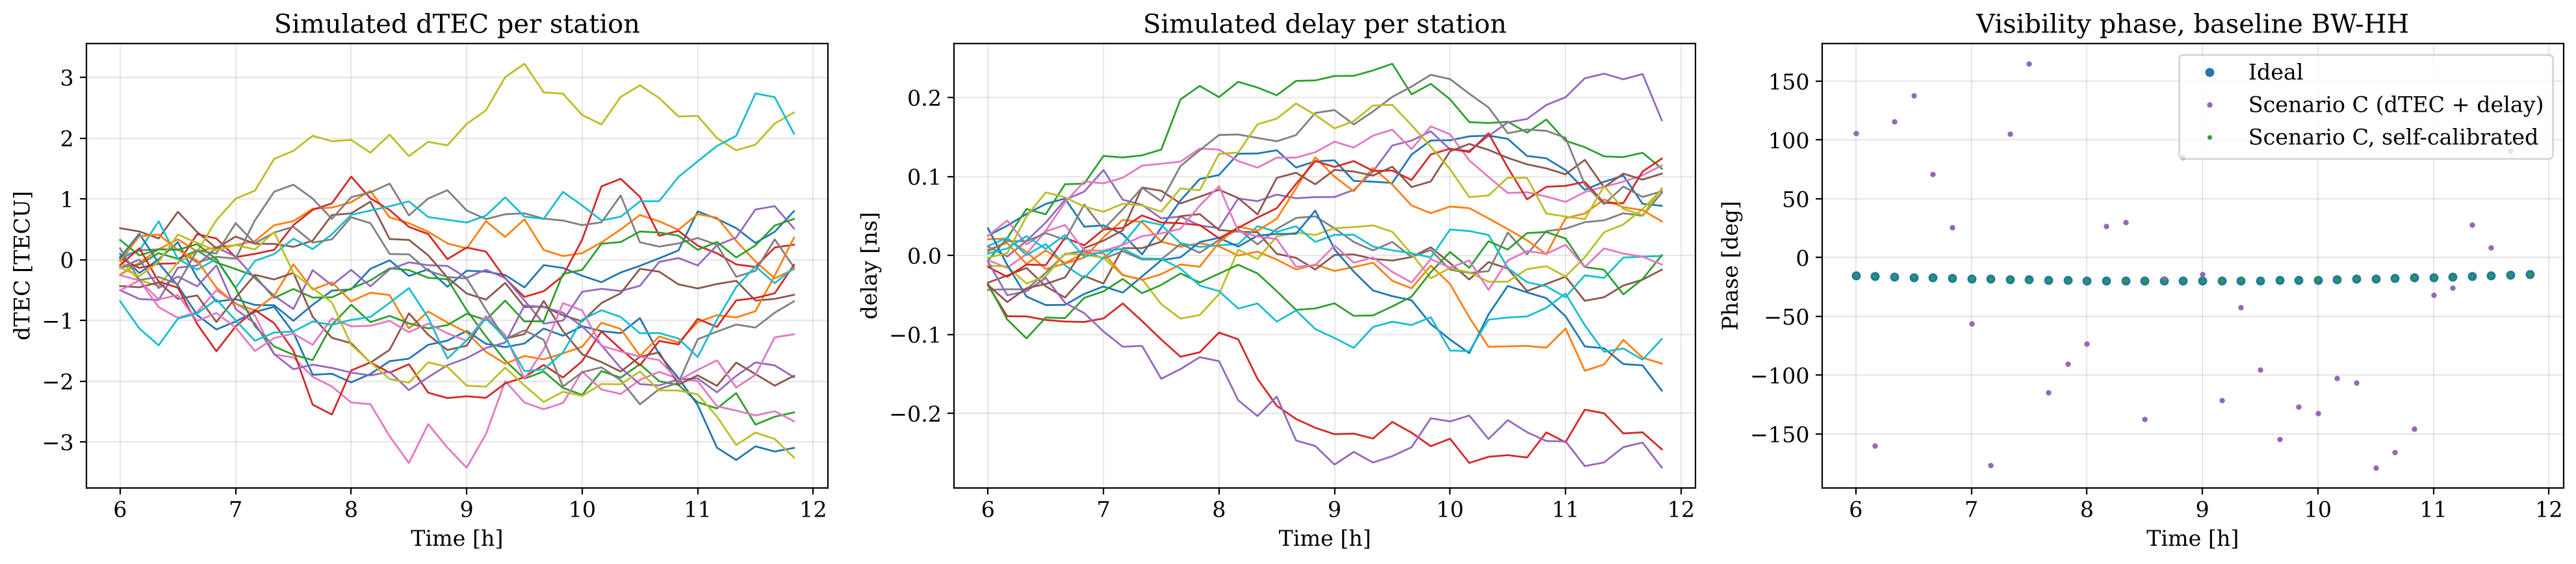

In [11]:
from collections import Counter

# --- Self-calibration (amplitude + phase: Scenario C carries the same gain errors as Scenario B) ---
cal_jet_errC = sc.self_cal(obs_jet_errC, im_jet, ttype='fast', scan_solutions=True, processes=1)

# --- Closure-phase invariance check: same triangles, before vs. after the atmospheric corruptions ---
cp_before = obs_jet_baseC.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
cp_after  = obs_jet_errC.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
dcp = (cp_after['cphase'] - cp_before['cphase'] + 180) % 360 - 180
print(f"Closure phases: {len(cp_before)} triangles, max |change| caused by the atmospheric corruptions = {np.abs(dcp).max():.1e} deg")

# --- Pick the best-sampled baseline and extract its phase vs. time ---
bl = Counter(zip(obs_jet_errC.data['t1'], obs_jet_errC.data['t2'])).most_common(1)[0][0]

def baseline_phase(o):
    m = (o.data['t1'] == bl[0]) & (o.data['t2'] == bl[1])
    return o.data['time'][m], np.angle(o.data['vis'][m], deg=True)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

for i_s, s in enumerate(screens['sites']):
    axes[0].plot(screens['times'], screens['dtec'][i_s], lw=1)
    axes[1].plot(screens['times'], screens['delay_ns'][i_s], lw=1)
axes[0].set_title('Simulated dTEC per station'); axes[0].set_ylabel('dTEC [TECU]')
axes[1].set_title('Simulated delay per station'); axes[1].set_ylabel('delay [ns]')
for a in axes[:2]:
    a.set_xlabel('Time [h]'); a.grid(True, alpha=0.3)

t_i, p_i = baseline_phase(obs_jet_ideal)
t_c, p_c = baseline_phase(obs_jet_errC)
t_s, p_s = baseline_phase(cal_jet_errC)
axes[2].plot(t_i, p_i, '.', color='tab:blue',   ms=8, label='Ideal')
axes[2].plot(t_c, p_c, '.', color='tab:purple', ms=4, label='Scenario C (dTEC + delay)')
axes[2].plot(t_s, p_s, '.', color='tab:green',  ms=3, label='Scenario C, self-calibrated')
axes[2].set_title(f'Visibility phase, baseline {bl[0]}-{bl[1]}')
axes[2].set_xlabel('Time [h]'); axes[2].set_ylabel('Phase [deg]')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
save_fig(fig, '04_scenarioC_screen_and_phases')
plt.show()


## 4. RML imaging: closures vs. raw visibilities

We will now use Regularized Maximum Likelihood (RML) imaging to reconstruct the jet, comparing two strategies on the same corrupted dataset:

1. **Closure-quantity imaging** (bispectrum `bs`, closure phase `cphase`, log closure amplitude `logcamp`): immune to antenna-based errors, because these cancel out algebraically when combining triplets/quadruplets of stations.
2. **Raw-visibility imaging** (`vis`): uses the observed complex data directly, so it **absorbs** any uncorrected antenna amplitude or phase error.

This is the central experiment of the notebook: comparing both approaches on the same corrupted dataset, to see with your own eyes which one survives the errors and which one doesn't.

### 4.0 What is a "closure quantity", exactly?

In real VLBI, every antenna has its own clock, its own atmosphere overhead, and its own electronics. This introduces **phase** errors (atmospheric turbulence, clock offsets) and **amplitude** errors (imperfect gain calibration at each antenna) that are hard to calibrate to absolute precision. Formally, the visibility you actually measure on baseline $i$–$j$, $r_{ij}$, is the *true* sky visibility $V_{ij}$ multiplied by the (unknown) complex gains of the two stations involved:

$$ r_{ij} = \gamma_i \gamma_j^{*} V_{ij} $$

where $\gamma_i$ is the complex station gain of antenna $i$ (amplitude error times a phase error). **Closure quantities** are special combinations of visibilities, taken over closed loops of three or four antennas, in which every $\gamma_i$ term cancels out exactly, leaving an observable that depends only on the true sky structure (plus thermal noise), not on the antenna gains. That is the entire reason they are useful: they let us image a source even when we don't trust our amplitude or phase calibration.

**Bispectrum and closure phase.** For any three stations $i,j,k$, the *bispectrum* is the triple product of the three visibilities around that triangle:

$$ V_{ijk} \;=\; V_{ij}\,V_{jk}\,V_{ki} $$

Substituting $r_{ij}=\gamma_i\gamma_j^{*}V_{ij}$ into this product, every gain term appears once as $\gamma_i$ and once as $\gamma_i^{*}$, so they all cancel:

$$ r_{ij}\,r_{jk}\,r_{ki} \;=\; \big(\gamma_i\gamma_j^{*}\big)\big(\gamma_j\gamma_k^{*}\big)\big(\gamma_k\gamma_i^{*}\big)\,V_{ij}V_{jk}V_{ki} \;=\; V_{ij}V_{jk}V_{ki} $$

The **closure phase** is simply the phase (argument) of this bispectrum:

$$ \psi_{ijk} \;=\; \arg(V_{ijk}) \;=\; \phi_{ij} + \phi_{jk} + \phi_{ki} $$

i.e. the sum of the three baseline phases around the triangle. Because the gain phases cancelled in the product, $\psi_{ijk}$ is completely insensitive to per-antenna phase errors (atmosphere, clocks), and only thermal noise affects it. This is exactly what `data_term={'bs': ...}` and `data_term={'cphase': ...}` use in the code below: `bs` fits the full complex bispectrum, while `cphase` fits just its phase.

**Log closure amplitude.** For any four stations $i,j,k,l$, we can form a ratio of visibility amplitudes across the two diagonals of the quadrangle:

$$ A_{ijkl} \;=\; \frac{|V_{ij}|\,|V_{kl}|}{|V_{ik}|\,|V_{jl}|} $$

Every antenna's gain amplitude $|\gamma_i|$ appears once in the numerator and once in the denominator, so they cancel exactly, regardless of how large or wrong the gain errors are. In practice we work with the **logarithm** of this ratio,

$$ \ln A_{ijkl} \;=\; \ln|V_{ij}| + \ln|V_{kl}| - \ln|V_{ik}| - \ln|V_{jl}| $$

because at low signal-to-noise the raw ratio $A_{ijkl}$ has a long, non-Gaussian tail (it can blow up whenever a denominator visibility happens to be small), while $\ln A_{ijkl}$ behaves much closer to a Gaussian, which makes it far better behaved for the optimizer. This is what `data_term={'logcamp': ...}` fits.

**The trade-off:** Closure quantities buy you complete immunity to antenna-based gain errors, but they throw away some real information in the process: closure phases are insensitive to an overall shift of the image (there is no way to recover the absolute position of the source from them alone), and closure amplitudes are insensitive to the total flux density. That is precisely why `run_rml_imager()` below also includes `flux` and `cm` (centroid) regularizer terms, which put back in, via the prior, exactly the two things closure quantities cannot constrain on their own.

### 4.1 Shared utilities

We define one generic multi-round imaging function (`run_rml_imager`), an alignment helper (`align_to_model`), and a quantitative fidelity metric (`nrmse`), so the same code can run any sequence of imaging rounds without duplicating logic for each case.

> **Syntax note for 1.2.10:** `eh.imager.Imager(obs_in, init_im, prior_im, flux, data_term=..., reg_term=..., maxit=..., ttype=...)` and the "successive rounds" pattern (`imgr.init_next`, `imgr.prior_next`, `imgr.dat_term_next`, `imgr.maxit_next`, followed by another call to `imgr.make_image_I()`) are both consistent with the real `Imager` and `make_image_I()` signatures in 1.2.10 (confirmed with `inspect.signature`). There's no need to create a new `Imager` object for each round: just overwrite those `_next` attributes and call `make_image_I()` again. Note that `show_updates` must be passed directly to `make_image_I(show_updates=...)`, not assigned as an attribute on `imgr`; see the docstring of `run_rml_imager()` below.

> **RADIOBLOCKS scenarios.** This section reconstructs the three datasets of Section 3: `obs_jet_thA` (**Scenario A**, thermal noise only), `obs_jet_err` (**Scenario B**, thermal noise + gain + generic phase errors) and `obs_jet_errC` (**Scenario C**, thermal noise + gain + structured atmospheric corruptions, ionospheric dTEC + tropospheric delay). Scenario A has no antenna-based errors to remove, so it shows the best result achievable at the given SNR; the closures-vs-raw-visibilities comparison is run for B and C, where the gain and phase errors that closure quantities cancel are present.

In [12]:
def align_to_model(im_to_align, ref_im):
    """Aligns a reconstructed image to a reference model via 2D cross-correlation.

    This is necessary because RML imaging via closures does not fix the absolute
    position of the source in the image plane (closure phases are insensitive to a
    global shift of the source), so before any visual comparison or metric
    computation, we align the reconstruction with the reference by maximising their cross-correlation.
    Pixels shifted out of the field are dropped (no wrap-around).
    """
    img_arr = im_to_align.imvec.reshape(im_to_align.ydim, im_to_align.xdim)
    ref_arr = ref_im.imvec.reshape(ref_im.ydim, ref_im.xdim)

    corr = scipy.signal.correlate2d(ref_arr, img_arr, mode='same', boundary='wrap')
    y_peak, x_peak = np.unravel_index(np.argmax(corr), corr.shape)

    dy = y_peak - (im_to_align.ydim // 2)
    dx = x_peak - (im_to_align.xdim // 2)

    aligned_arr = np.roll(img_arr, shift=(dy, dx), axis=(0, 1))
    # np.roll wraps around: blank the pixels that came in from the opposite edge
    if dy > 0: aligned_arr[:dy, :] = 0
    if dy < 0: aligned_arr[dy:, :] = 0
    if dx > 0: aligned_arr[:, :dx] = 0
    if dx < 0: aligned_arr[:, dx:] = 0

    aligned_im = im_to_align.copy()
    aligned_im.imvec = aligned_arr.flatten()
    return aligned_im


def nrmse(im_rec, im_true):
    """Normalized root-mean-square error between two ehtim images (same pixel size).

    This is a QUANTITATIVE fidelity metric for the reconstruction, complementing
    (and more objective than) simple visual inspection of the images. The closer
    to 0, the better the reconstruction.
    """
    if im_rec.imvec.shape != im_true.imvec.shape:
        raise ValueError(
            f"nrmse: image shapes do not match ({im_rec.imvec.shape} vs {im_true.imvec.shape}). "
            f"Regrid one of them first with im.regrid_image(target_fov, target_npix)."
        )
    a = im_rec.imvec / im_rec.imvec.sum()
    b = im_true.imvec / im_true.imvec.sum()
    return float(np.sqrt(np.mean((a - b) ** 2)) / np.sqrt(np.mean(b ** 2)))


class LoggedImager(eh.imager.Imager):
    """Imager that records the reduced chi^2 of every active data term at each iteration.

    ehtim calls plotcur() once before the optimizer starts (iteration 0) and then after every
    L-BFGS-B iteration, whether or not show_updates is True, so overriding it is the cleanest
    way to follow the convergence of the data fit.
    """
    def plotcur(self, imvec, **kwargs):
        if getattr(self, 'history', None) is not None:
            chi2 = self.make_chisq_dict(np.exp(imvec))      # the optimizer works on the log-image
            self.history.append({'round': self.round_id, 'iter': self._nit, **{k: float(v) for k, v in chi2.items()}})
        super().plotcur(imvec, **kwargs)


def run_rml_imager(obs, prior, flux, rounds, ttype='fast', verbose=False, obs_alt=None, history=None,
                   snapshots=None, cal_store=None):
    """Runs a generic multi-round RML imaging pipeline.

    Args:
        obs: Obsdata to reconstruct (used for all rounds unless overridden)
        prior: initial prior image (Image)
        flux: total flux to enforce in the reconstruction (float, Jy)
        rounds: list of dicts, one per round, each with keys:
            'data_term', 'reg_term', 'maxit' (and optionally:
            'blur_frac', blur applied to the prior relative to the array
            resolution before this round, defaults to no blur;
            'switch_obs', a key into obs_alt to swap the dataset for this
            round; 'selfcal': True, to self-calibrate the dataset (amplitude
            and phase, one gain per station and scan) to the image of the
            previous round before this round starts, as in hybrid mapping)
        ttype: Fourier engine ('fast' or 'direct')
        verbose: if True, prints the data term used for each round
        obs_alt: dict mapping 'switch_obs' key names to Obsdata objects
        history: optional list; if given, the reduced chi^2 of each data term is appended to it
                 at every iteration of every round (see LoggedImager)
        snapshots: optional list; if given, the (unblurred) image at the end of every round is appended
        cal_store: optional list; if given, every dataset produced by a 'selfcal' round is appended

    Returns:
        Image: the result of the last round (WITHOUT the final resolution blur
               applied, that is an explicit step outside this function).

    Notes:
        show_updates=False is passed to make_image_I to suppress the
        per-iteration plot callback inside the optimizer. We also wrap each
        call in plt.ioff()/plt.close('all') because ehtim can internally
        activate interactive mode or open figures via its plot_i() helper,
        which in Jupyter causes a figure to appear at the end of each round
        even when show_updates is False. Temporarily disabling interactive
        mode and closing residual figures keeps the notebook output clean.
        We redirect stdout to a StringIO sink to suppress ehtim's text output
        (chi2 tables, timing lines, etc.); set verbose=True for a one-line
        summary per round instead.
    """
    import io, contextlib

    imgr = None
    out = prior
    current_obs = obs
    for i, rnd in enumerate(rounds):
        switch_key = rnd.get('switch_obs')
        if switch_key is not None and obs_alt and switch_key in obs_alt:
            current_obs = obs_alt[switch_key]
            if verbose:
                print(f"  -> Round {i+1}/{len(rounds)}: switching obs to '{switch_key}', "
                      f"data_term={list(rnd['data_term'].keys())}")
        else:
            if verbose:
                print(f"  -> Round {i+1}/{len(rounds)}: data_term={list(rnd['data_term'].keys())}")

        if rnd.get('selfcal') and i > 0:
            # Hybrid mapping: calibrate the data to the image reconstructed so far (never to the true source)
            current_obs.add_scans()                         # needed by scan_solutions=True
            with contextlib.redirect_stdout(io.StringIO()):
                current_obs = sc.self_cal(current_obs, out, method='both', ttype=ttype,
                                          scan_solutions=True, processes=1)
            if cal_store is not None:
                cal_store.append(current_obs)
            if verbose:
                print(f"     (data self-calibrated to the image of round {i}, amplitude + phase, one gain per station and scan)")

        blur_frac = rnd.get('blur_frac', 0.0)
        init_im = out.blur_circ(blur_frac * current_obs.res()) if blur_frac > 0 else out

        if imgr is None:
            Imgr = LoggedImager if history is not None else eh.imager.Imager
            imgr = Imgr(
                current_obs, init_im, init_im, flux,
                data_term=rnd['data_term'],
                reg_term=rnd['reg_term'],
                maxit=rnd['maxit'], ttype=ttype
            )
            imgr.history = history
        else:
            imgr.obslist_next = [current_obs]
            imgr.init_next = init_im
            imgr.prior_next = init_im
            imgr.dat_term_next = rnd['data_term']
            imgr.reg_term_next = rnd['reg_term']
            imgr.maxit_next = rnd['maxit']
        imgr.round_id = i

        plt.ioff()                                          # disable interactive mode
        with contextlib.redirect_stdout(io.StringIO()):     # suppress ehtim text output
            out = imgr.make_image_I(show_updates=False)
        plt.close('all')                                    # close any figure ehtim opened
        plt.ion()                                           # restore interactive mode
        if snapshots is not None:
            snapshots.append(out)

    return out


CHI2_COLORS = {'cphase': 'tab:blue', 'logcamp': 'tab:orange', 'bs': 'tab:green', 'amp': 'tab:red', 'vis': 'tab:purple'}

def plot_chi2_histories(hists, titles, fname, suptitle, ncols=3):
    """One panel per reconstruction: reduced chi^2 of every active data term at every iteration,
    cumulative over the rounds (dashed lines = start of a new round, dotted line = chi^2 of 1)."""
    keys = [k for k in hists if hists[k]]
    nrows = int(np.ceil(len(keys) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.8 * nrows), squeeze=False)
    for ax, k in zip(axes.ravel(), keys):
        h = hists[k]; off = 0; edges = []; seen = set()
        for r in sorted({x['round'] for x in h}):
            rec = [x for x in h if x['round'] == r]
            xs = off + np.array([x['iter'] for x in rec])
            for t, c in CHI2_COLORS.items():
                if t in rec[0]:
                    ax.semilogy(xs, [x[t] for x in rec], color=c, lw=1.4, label=None if t in seen else t); seen.add(t)
            off = xs.max() + 1; edges.append(off)
        for e in edges[:-1]:
            ax.axvline(e, color='gray', ls='--', lw=0.8)
        ax.axhline(1, color='k', ls=':', lw=0.8)
        ax.set_title(titles.get(k, k), fontsize=10)
        ax.set_xlabel('iteration (cumulative over rounds)', fontsize=9)
        ax.legend(fontsize=8, loc='upper right')
    for ax in axes.ravel()[len(keys):]:
        ax.axis('off')
    for ax in axes[:, 0]:
        ax.set_ylabel(r'reduced $\chi^2$')
    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    save_fig(fig, fname)
    plt.show()


print("Utility functions defined: align_to_model(), nrmse(), run_rml_imager(), LoggedImager, plot_chi2_histories()")

Utility functions defined: align_to_model(), nrmse(), run_rml_imager(), LoggedImager, plot_chi2_histories()


### 4.2 Imaging pipeline for the jet (bispectrum → closures → hybrid self-cal refinement)

For a source with extended structure like a jet, a single-round pipeline isn't enough: we need to progressively refine, and we can make the final refinement round more powerful by switching to the **self-calibrated visibilities** produced in Section 3.

1. **Round 1: bispectrum (`bs`)** kicks off the reconstruction with a data product that is robust against any antenna-based error (it combines closure phase and amplitude into a single term).
2. **Round 2: visibility amplitudes + closure phases (`amp` + `cphase`)** refines using amplitudes and closure phases separately, allowing more spatial detail.
3. **Round 3: hybrid self-cal refinement (`amp` + `cphase` + `logcamp`)** switches to the self-calibrated visibilities (`cal_jet` for Scenario B, `cal_jet_errC` for Scenario C) from Section 3, but **keeps the closure quantities active**. Closure quantities are, by construction, identical before and after self-calibration (the gains cancel), so what the switch adds is the **calibrated amplitudes** (`amp`): after self-cal the antenna-based gain errors are largely corrected, so the amplitudes are now trustworthy and constrain the total flux and the large-scale structure, while the closures keep the structural robustness.

The raw-visibility pipeline uses `vis` throughout all rounds, with no self-cal step, which is exactly the worst-case scenario we want to compare against.

> **Reconstruction grid.** The jet model covers 18 mas, and its flux centroid is ~3 mas away from the image centre. Closure-based imaging does not fix the absolute position (the `cm` regularizer puts the centroid at the image centre), so the reconstruction grid is **1.5 times larger** than the model (27 mas, 96 pixels of the same size as the model's) to give a shifted reconstruction room to fit. The reference image for every metric is the true model **regridded to this grid and blurred to the same resolution** as the reconstructions, so the comparison is pixel-to-pixel at the same scale.

> **Iterations.** Each round runs 150–200 iterations of the optimizer. Growing a 15 mas jet with a core, knots and a second bright component from a smooth Gaussian prior takes many iterations; with fewer (e.g. 60–100) the optimizer stops before the faint knots between the core and the second component appear.

> **Flux regularizer weight.** The `'flux'` regularizer weight is set to 1000 in every round. Closure quantities (closure phases and closure amplitudes) do not constrain the total flux density, and regularizers such as TV depend on the image brightness, so with a weak `'flux'` term (e.g. 1) the closure-based reconstructions can end up with only a fraction of the true flux, even if their shape is right. A high weight keeps the total flux at `zbl`.

> **Self-calibration model.** In this hands-on the self-calibrated datasets of Section 3 were obtained with the *true* jet model, which is a best case. The delivery version of the project replaces it by an iterative self-calibration to the image reconstructed so far.

In [13]:
# NOTE on 'flux': 1000. Closure quantities do not constrain the total flux, and regularizers such as TV
# can pull it down, so the 'flux' regularizer gets a high weight to keep the total flux at zbl.
jet_closure_rounds = [
    {'data_term': {'bs': 100},          'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 150},
    {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 1,  'flux': 1000, 'cm': 50}, 'maxit': 200,  'blur_frac': 1.0},
    # Round 3: switch obs to the self-calibrated dataset: the calibrated amplitudes ('amp') are now trustworthy,
    # and the closure quantities are kept for their robustness (they are unchanged by self-calibration).
    {'data_term': {'amp': 50, 'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 200, 'blur_frac': 0.5, 'switch_obs': 'cal'},
]
jet_vis_rounds = [
    {'data_term': {'vis': 100}, 'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
    {'data_term': {'vis': 100}, 'reg_term': {'tv': 1,      'flux': 1000, 'cm': 50}, 'maxit': 180, 'blur_frac': 1.0},
]

# Reconstruction grid: 1.5 x the model field of view, same pixel size as the model (see the note above)
npix_jet, zbl = 96, im_jet.total_flux()
fov_jet    = 1.5 * im_jet.fovx()
prior_fwhm = 0.6 * im_jet.fovx()        # broad Gaussian prior, of the order of the jet extent

emptyprior = eh.image.make_empty(npix_jet, fov_jet, obs_jet_ideal.ra, obs_jet_ideal.dec, rf=nu)
gaussprior = emptyprior.add_gauss(zbl, [prior_fwhm, prior_fwhm, 0, 0, 0])
print(f"Reconstruction grid: {npix_jet} px over {fov_jet/eh.RADPERUAS/1000:.1f} mas "
      f"({fov_jet/npix_jet/eh.RADPERUAS:.0f} uas pixels); prior FWHM {prior_fwhm/eh.RADPERUAS/1000:.1f} mas")

# obs_alt maps the 'switch_obs' key in each round to an actual Obsdata object.
# Ideal and Scenario A have no gain/phase errors to self-calibrate, so round 3 just reuses
# the same dataset for both; Scenario B switches to cal_jet, Scenario C to cal_jet_errC.
runs = {   # name: (dataset for rounds 1-2, rounds, dataset for round 3)
    'ideal':        (obs_jet_ideal, jet_closure_rounds, obs_jet_ideal),
    'thA':          (obs_jet_thA,   jet_closure_rounds, obs_jet_thA),
    'err_closure':  (obs_jet_err,   jet_closure_rounds, cal_jet),
    'err_vis':      (obs_jet_err,   jet_vis_rounds,     None),
    'errC_closure': (obs_jet_errC,  jet_closure_rounds, cal_jet_errC),
    'errC_vis':     (obs_jet_errC,  jet_vis_rounds,     None),
}
labels = {'ideal': 'Ideal (closures + hybrid)', 'thA': 'Scenario A (thermal only, closures + hybrid)',
          'err_closure': 'Scenario B (closures + hybrid self-cal)', 'err_vis': 'Scenario B (raw visibilities)',
          'errC_closure': 'Scenario C (closures + hybrid self-cal)', 'errC_vis': 'Scenario C (raw visibilities)'}
rec_raw = {}       # UNBLURRED reconstructions (needed for the chi^2 of Section 4.6)
hist_class = {key: [] for key in runs}   # chi^2 of every data term at every iteration (Section 4.7)
for key, (o_, rounds_, cal_) in runs.items():
    print(f"\n--- Running {labels[key]} ---")
    rec_raw[key] = run_rml_imager(o_, gaussprior, zbl, rounds_, ttype='fast', verbose=True,
                                  obs_alt={'cal': cal_} if cal_ is not None else None,
                                  history=hist_class[key])

# Final resolution blur, consistent with the array's actual resolving power
res_jet = obs_jet_err.res()
im_rec_ideal        = rec_raw['ideal'].blur_circ(res_jet)
im_rec_thA          = rec_raw['thA'].blur_circ(res_jet)
im_rec_err_closure  = rec_raw['err_closure'].blur_circ(res_jet)
im_rec_err_vis      = rec_raw['err_vis'].blur_circ(res_jet)
im_rec_errC_closure = rec_raw['errC_closure'].blur_circ(res_jet)
im_rec_errC_vis     = rec_raw['errC_vis'].blur_circ(res_jet)

# REFERENCE image for all the metrics: the true jet on the reconstruction grid, blurred with the SAME resolution
im_ref = im_jet.regrid_image(fov_jet, npix_jet).blur_circ(res_jet)
im_ref.imvec *= zbl / im_ref.total_flux()

print("\nAll reconstructions complete (Ideal, Scenario A, Scenario B x2, Scenario C x2)! Run the next cell to view the results.")

Reconstruction grid: 96 px over 27.0 mas (281 uas pixels); prior FWHM 10.8 mas

--- Running Ideal (closures + hybrid) ---
  -> Round 1/3: data_term=['bs']
Initializing imager data products . . .


  -> Round 2/3: data_term=['amp', 'cphase']


  -> Round 3/3: switching obs to 'cal', data_term=['amp', 'cphase', 'logcamp']



--- Running Scenario A (thermal only, closures + hybrid) ---
  -> Round 1/3: data_term=['bs']
Initializing imager data products . . .


  -> Round 2/3: data_term=['amp', 'cphase']


  -> Round 3/3: switching obs to 'cal', data_term=['amp', 'cphase', 'logcamp']


... (7 outputs left out)

  -> Round 3/3: switching obs to 'cal', data_term=['amp', 'cphase', 'logcamp']



--- Running Scenario C (raw visibilities) ---
  -> Round 1/2: data_term=['vis']
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


  -> Round 2/2: data_term=['vis']



All reconstructions complete (Ideal, Scenario A, Scenario B x2, Scenario C x2)! Run the next cell to view the results.


### 4.3 Final visual comparison: Ideal vs. Scenario A vs. Scenario B vs. Scenario C

Besides the visual comparison, we compute the NRMSE of each reconstruction against a **reference image**: the true jet regridded to the reconstruction grid and blurred with the same resolution (`res_jet`) applied to the reconstructions (the array cannot resolve structure finer than that, so this is the fair "ground truth"). NRMSE is an objective metric that quantifies what a purely visual comparison can only suggest; Section 5 adds more.

> **RADIOBLOCKS scenarios.** In the panels below, "Scenario A" is the thermal-noise-only dataset, "Scenario B" is the thermal noise + gain + *generic* phase dataset, "Scenario C" is the thermal noise + gain + *structured* atmospheric corruptions (ionospheric + tropospheric) dataset (Section 3.5), and "Ideal" is the error-free reference. Comparing A with B (or C) isolates the cost of the systematic (gain + phase) errors from that of thermal noise alone. Comparing B with C isolates the effect of *how* the phase error is modeled, since both share the same thermal-noise and gain-error budget. In both B and C, the closures pipeline (with the self-cal refinement round) should resolve the antenna-based errors far better than raw visibilities — that is the central result this notebook is built to show, for either flavour of phase corruption.


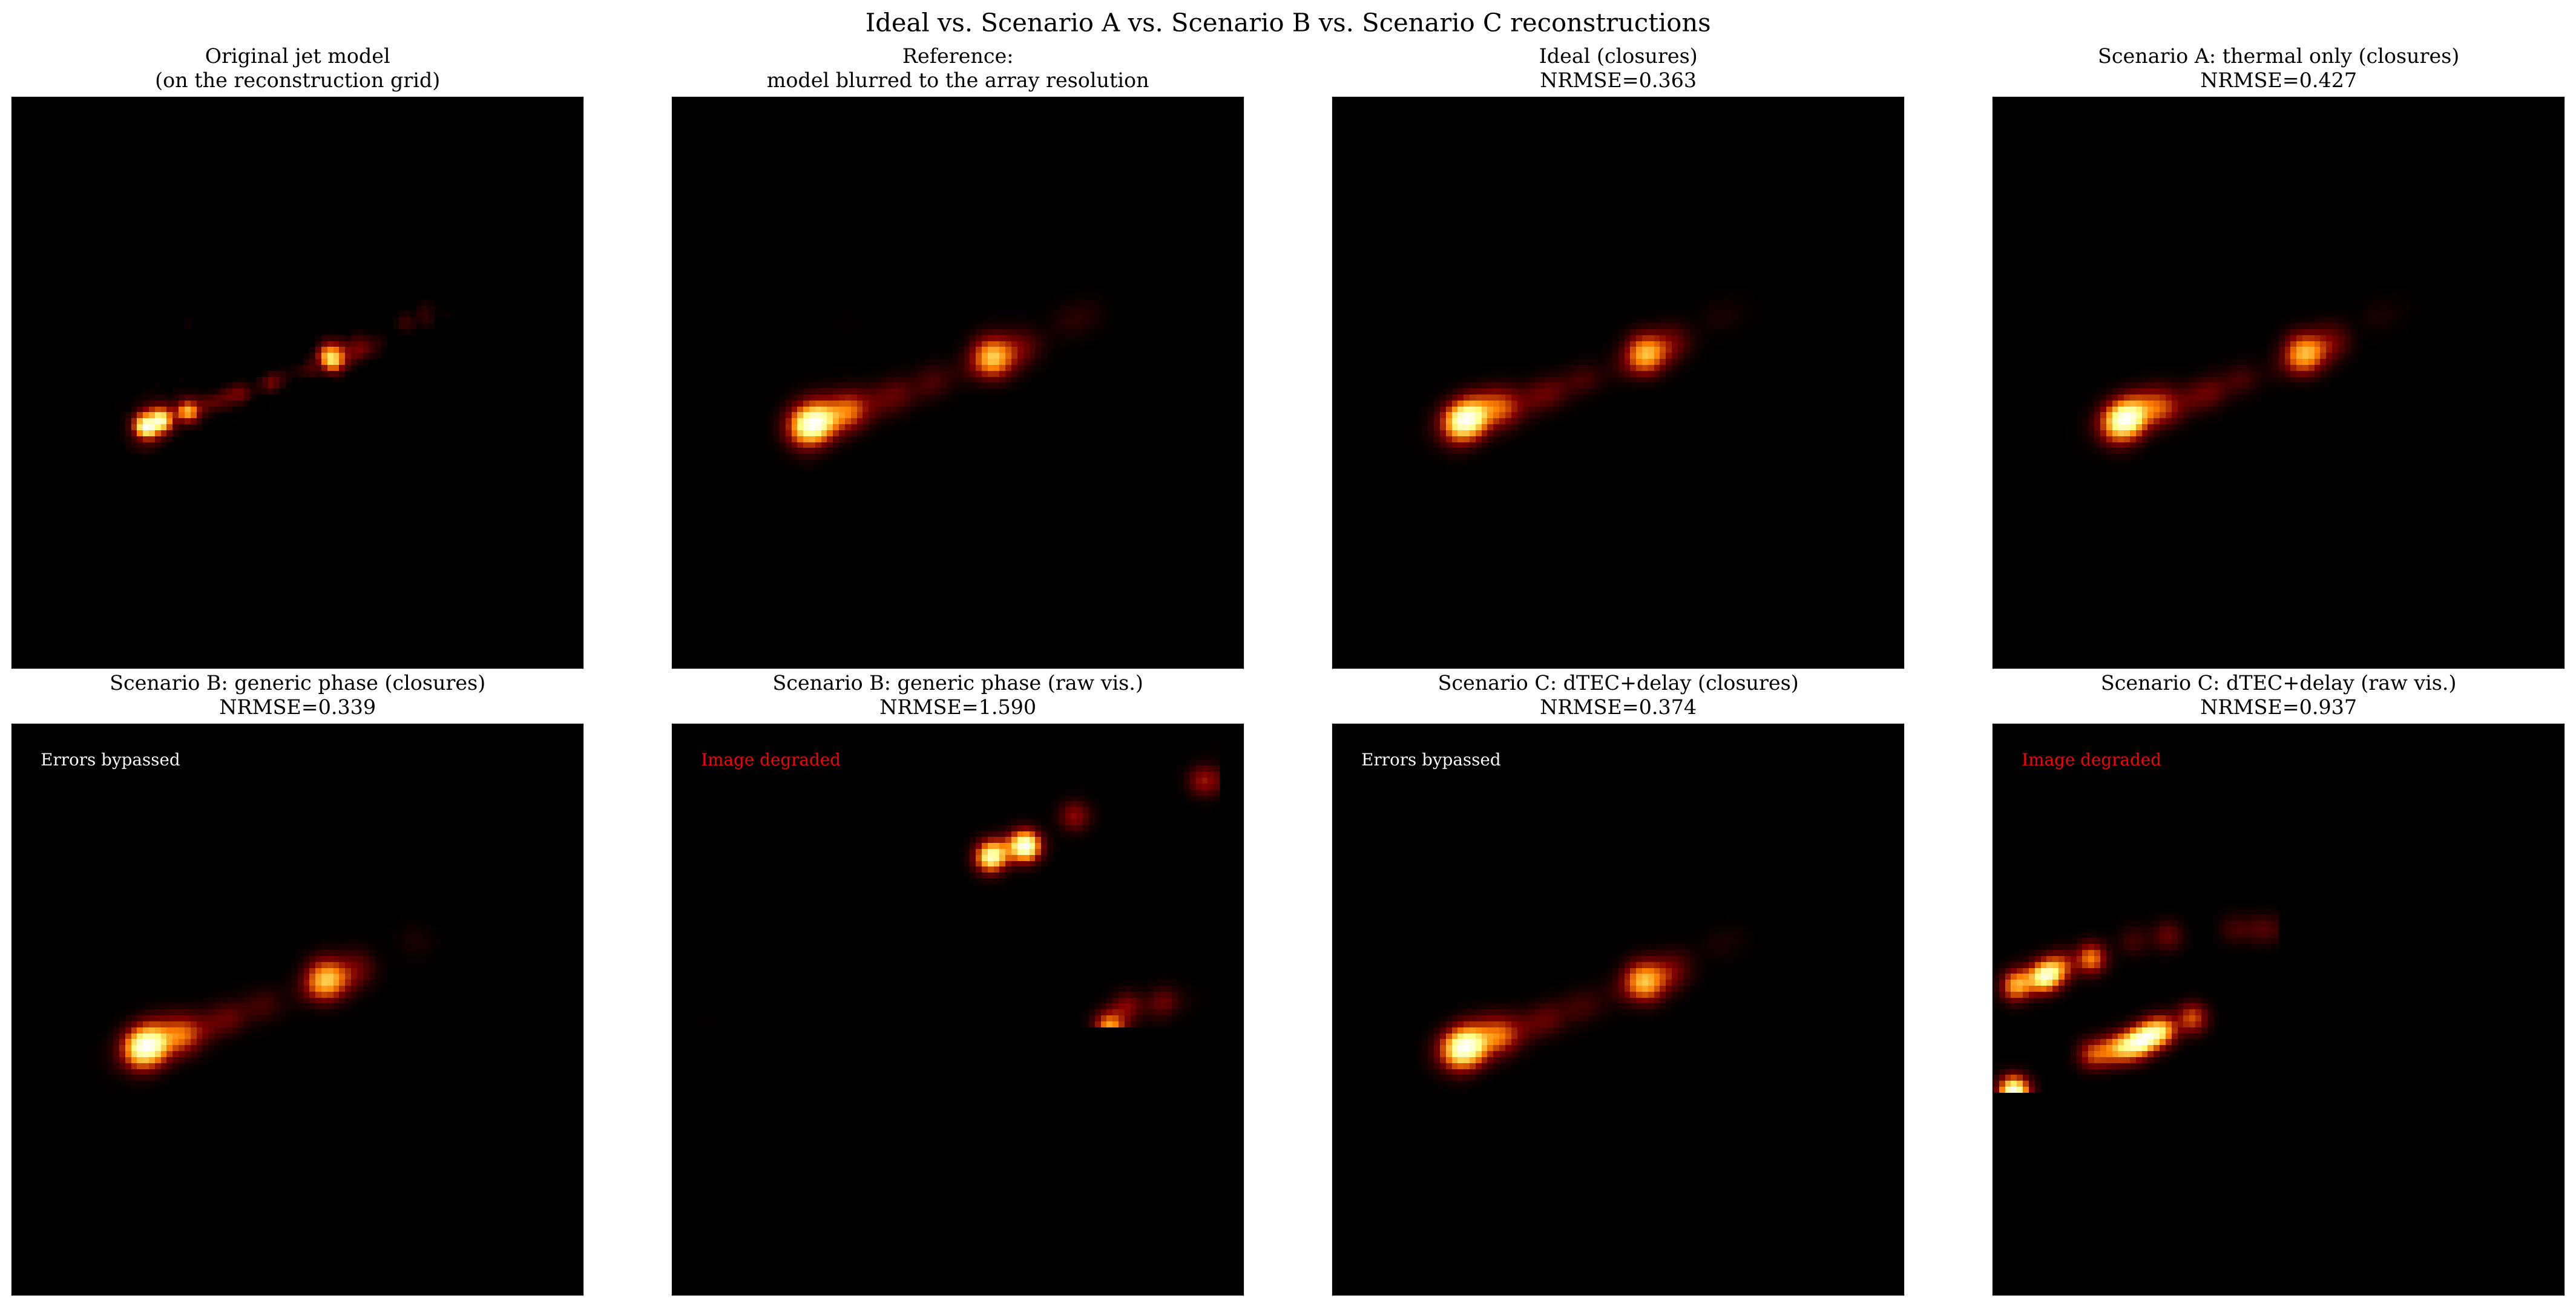

Compare the NRMSE values across all three error scenarios. In both Scenario B and Scenario C, the
closures-based reconstruction (with the self-cal refinement round) should be much closer to the
reference than the raw-visibility one, even though both used the exact same corrupted data within
each scenario. Scenario B and Scenario C share the same thermal-noise and gain-error budget, so any
remaining difference between their closures results isolates the effect of how the phase error is
structured in time (generic per-timestamp noise vs. correlated atmospheric corruptions (ionospheric + tropospheric drifts)).
If closures are not clearly better than raw visibilities in some scenario, the most common causes are:
  1. The prior or the field of view does not match the source extent (try adjusting fov_jet / prior_fwhm)
  2. The imager needs more iterations or an extra round (increase maxit or add a round)
  3. The corruption level is very high: try reducing gain_offset_val in Section 3
     o

In [14]:
aligned = {k: align_to_model(im, im_ref) for k, im in [
    ('ideal', im_rec_ideal), ('thA', im_rec_thA), ('err_closure', im_rec_err_closure), ('err_vis', im_rec_err_vis),
    ('errC_closure', im_rec_errC_closure), ('errC_vis', im_rec_errC_vis)]}
im_rec_ideal_aligned, im_rec_thA_aligned = aligned['ideal'], aligned['thA']
im_rec_err_closure_aligned, im_rec_err_vis_aligned = aligned['err_closure'], aligned['err_vis']
im_rec_errC_closure_aligned, im_rec_errC_vis_aligned = aligned['errC_closure'], aligned['errC_vis']

half = fov_jet / eh.RADPERUAS / 1000 / 2
def show(ax, im, title, note=None, note_color='white'):
    ax.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[half, -half, -half, half])
    ax.set_title(title, fontsize=12)
    if note:
        ax.text(0.05, 0.95, note, color=note_color, transform=ax.transAxes, va='top', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
show(axes[0, 0], im_jet.regrid_image(fov_jet, npix_jet), "Original jet model\n(on the reconstruction grid)")
show(axes[0, 1], im_ref, "Reference:\nmodel blurred to the array resolution")
show(axes[0, 2], im_rec_ideal_aligned, f"Ideal (closures)\nNRMSE={nrmse(im_rec_ideal_aligned, im_ref):.3f}")
show(axes[0, 3], im_rec_thA_aligned, f"Scenario A: thermal only (closures)\nNRMSE={nrmse(im_rec_thA_aligned, im_ref):.3f}")
show(axes[1, 0], im_rec_err_closure_aligned, f"Scenario B: generic phase (closures)\nNRMSE={nrmse(im_rec_err_closure_aligned, im_ref):.3f}", "Errors bypassed")
show(axes[1, 1], im_rec_err_vis_aligned, f"Scenario B: generic phase (raw vis.)\nNRMSE={nrmse(im_rec_err_vis_aligned, im_ref):.3f}", "Image degraded", 'red')
show(axes[1, 2], im_rec_errC_closure_aligned, f"Scenario C: dTEC+delay (closures)\nNRMSE={nrmse(im_rec_errC_closure_aligned, im_ref):.3f}", "Errors bypassed")
show(axes[1, 3], im_rec_errC_vis_aligned, f"Scenario C: dTEC+delay (raw vis.)\nNRMSE={nrmse(im_rec_errC_vis_aligned, im_ref):.3f}", "Image degraded", 'red')
plt.suptitle("Ideal vs. Scenario A vs. Scenario B vs. Scenario C reconstructions", fontsize=15)
plt.tight_layout()
save_fig(fig, '05_reconstructions_ideal_A_B_C')
plt.show()

print("Compare the NRMSE values across all three error scenarios. In both Scenario B and Scenario C, the")
print("closures-based reconstruction (with the self-cal refinement round) should be much closer to the")
print("reference than the raw-visibility one, even though both used the exact same corrupted data within")
print("each scenario. Scenario B and Scenario C share the same thermal-noise and gain-error budget, so any")
print("remaining difference between their closures results isolates the effect of how the phase error is")
print("structured in time (generic per-timestamp noise vs. correlated atmospheric corruptions (ionospheric + tropospheric drifts)).")
print("If closures are not clearly better than raw visibilities in some scenario, the most common causes are:")
print("  1. The prior or the field of view does not match the source extent (try adjusting fov_jet / prior_fwhm)")
print("  2. The imager needs more iterations or an extra round (increase maxit or add a round)")
print("  3. The corruption level is very high: try reducing gain_offset_val in Section 3")
print("     or dtec_step_tecu / delay_step_ns in Section 3.5")
print("  4. Differences of a few hundredths between Ideal, A, B and C are within the run-to-run variation")
print("     of the imaging (random noise realisations + a non-convex optimisation): see Section 5.")
print("\nTotal flux of each reconstruction (true value: %.2f Jy):" % zbl)
for k, im in [('ideal', im_rec_ideal), ('thA', im_rec_thA), ('err_closure', im_rec_err_closure), ('err_vis', im_rec_err_vis),
              ('errC_closure', im_rec_errC_closure), ('errC_vis', im_rec_errC_vis)]:
    print(f"  {labels[k]:48s} {im.total_flux():.3f} Jy")

### 4.4 Dirty beam, clean beam, and the array's resolution

Two classic radio interferometry concepts worth visualizing before trusting any image:

- **Dirty beam** (`obs.dirtybeam()`): the array's response to a point source, determined purely by the uv-coverage (with no deconvolution step). Its sidelobes are the signature of the "holes" in the uv-coverage.
- **Elliptical clean beam** (`obs.fit_beam()`): a 2D Gaussian fit to the main lobe of the dirty beam, giving an "effective" resolution (major FWHM, minor FWHM, position angle), which is what is typically reported as the real angular resolution of the observation.

The three panels below show (left to right): the dirty beam, the fitted elliptical clean beam, and the Scenario B closures reconstruction with the clean beam drawn as an ellipse in the lower-left corner (same angular scale). Note that the reconstructions of this notebook were blurred with a *circular* Gaussian of FWHM `obs.res()` (the nominal resolution, $1/|u|_{max}$), which is smaller than the fitted clean beam along its major axis: the delivery version of the project restores every image with the fitted elliptical beam instead, which is the more conservative choice.

> **Syntax note for 1.2.10:** `obs.fit_beam()` returns the tuple `(fwhm_maj, fwhm_min, theta)` in radians (confirmed against the function's real signature). We plot everything with `matplotlib` (`plt.subplots`) rather than `Image.display()`, to keep all plots as inline notebook outputs; `Image.display()` can open a separate figure window in some environments, which is disruptive in a hands-on session.

Fitted beam parameters:
  - Major axis:      1961.1 uas
  - Minor axis:      874.4 uas
  - Position angle:  90.7 degrees
  - Nominal resolution obs.res() used for the circular blur: 1161.7 uas


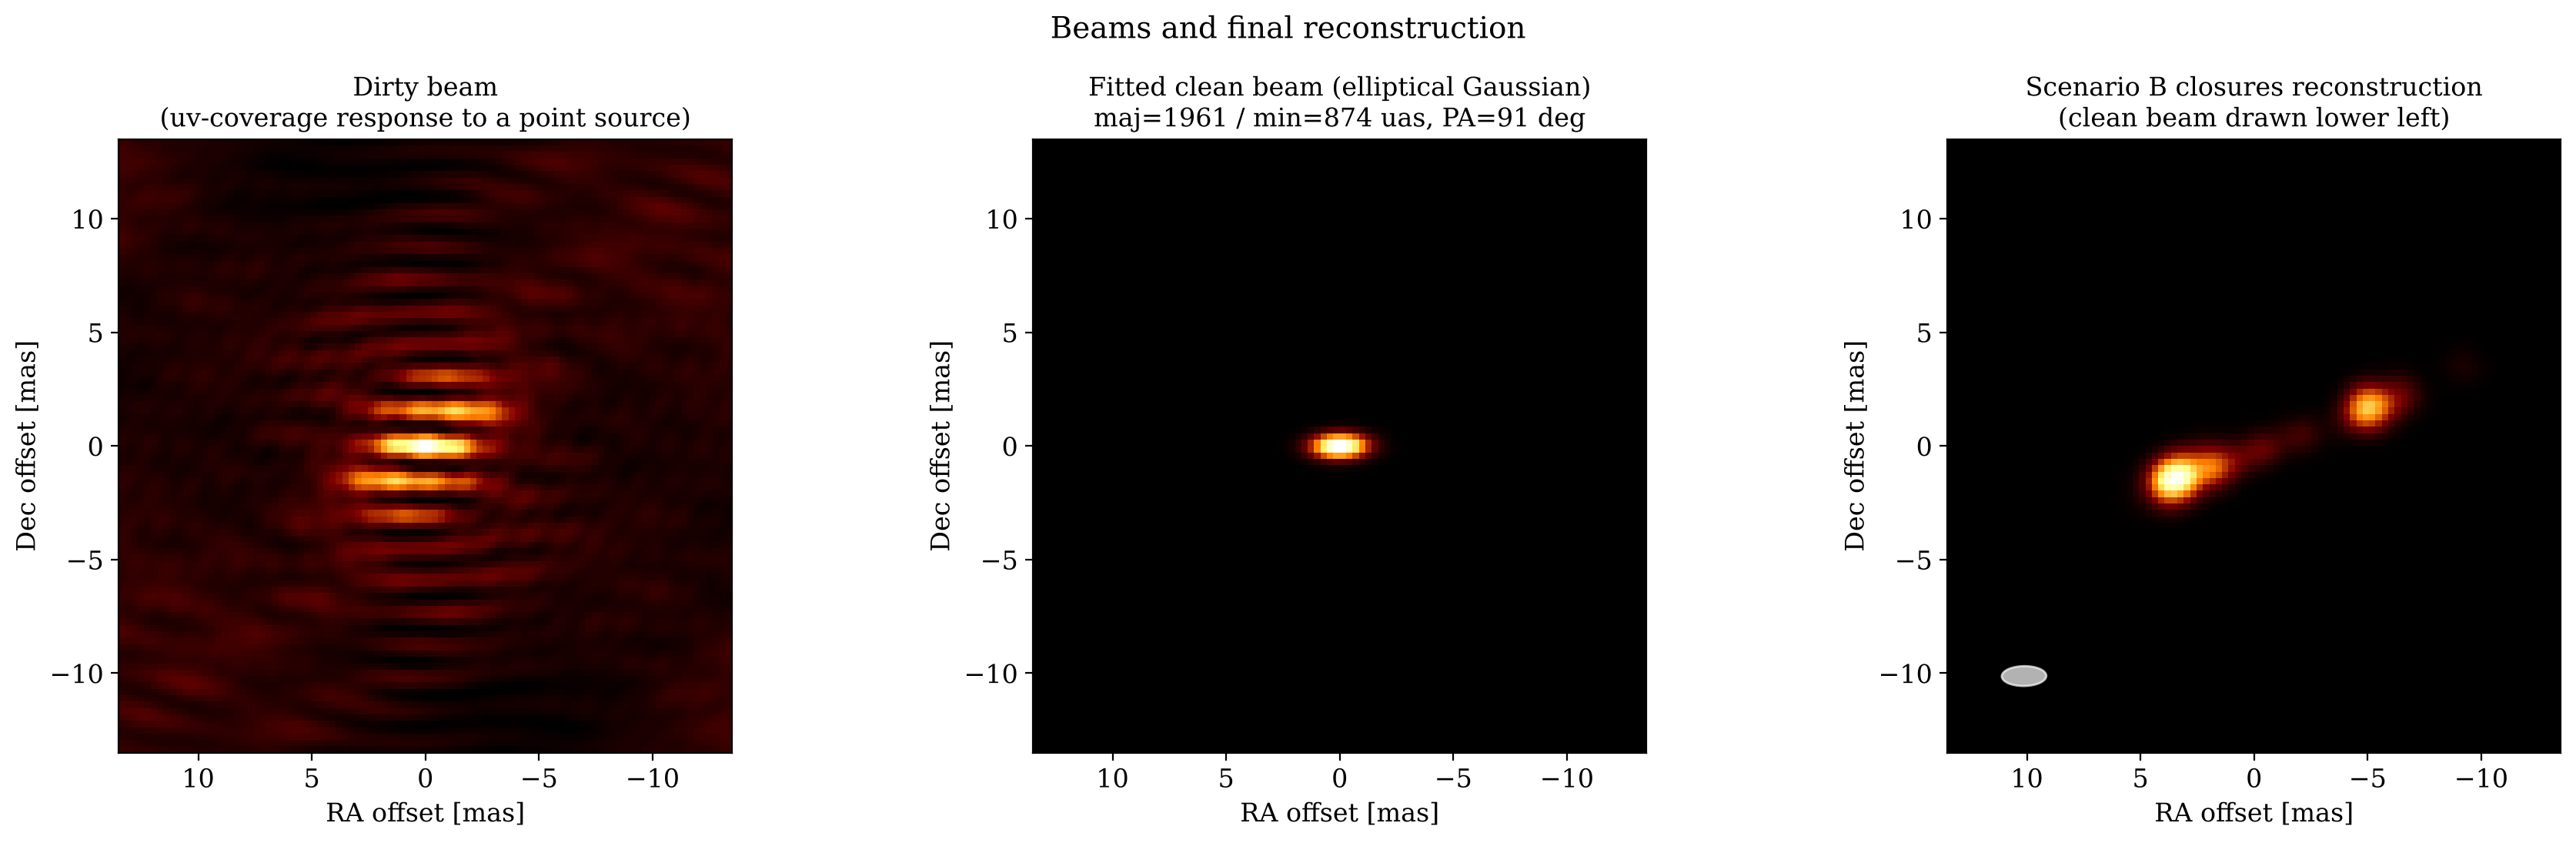

In [15]:
from matplotlib.patches import Ellipse

dirty_beam = obs_jet_err.dirtybeam(npix_jet, fov_jet)
beamparams = obs_jet_err.fit_beam()
fwhm_maj, fwhm_min, theta = beamparams

print("Fitted beam parameters:")
print(f"  - Major axis:      {fwhm_maj / eh.RADPERUAS:.1f} uas")
print(f"  - Minor axis:      {fwhm_min / eh.RADPERUAS:.1f} uas")
print(f"  - Position angle:  {theta * 180.0 / math.pi:.1f} degrees")
print(f"  - Nominal resolution obs.res() used for the circular blur: {res_jet / eh.RADPERUAS:.1f} uas")

clean_beam = emptyprior.add_gauss(1.0, [fwhm_maj, fwhm_min, theta, 0, 0])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, im, title in [(axes[0], dirty_beam, "Dirty beam\n(uv-coverage response to a point source)"),
                      (axes[1], clean_beam, f"Fitted clean beam (elliptical Gaussian)\nmaj={fwhm_maj/eh.RADPERUAS:.0f} / min={fwhm_min/eh.RADPERUAS:.0f} uas, PA={theta*180/math.pi:.0f} deg"),
                      (axes[2], im_rec_err_closure, "Scenario B closures reconstruction\n(clean beam drawn lower left)")]:
    ax.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[half, -half, -half, half])
    ax.set_title(title, fontsize=12); ax.set_xlabel('RA offset [mas]'); ax.set_ylabel('Dec offset [mas]')

# ehtim's position angle is measured east of north; east is to the LEFT in these images
axes[2].add_patch(Ellipse(xy=(0.75*half, -0.75*half), width=fwhm_min/eh.RADPERUAS/1000, height=fwhm_maj/eh.RADPERUAS/1000,
                          angle=-math.degrees(theta), edgecolor='white', facecolor='white', alpha=0.7))
plt.suptitle("Beams and final reconstruction", fontsize=14)
plt.tight_layout()
save_fig(fig, '06_dirty_beam_clean_beam')
plt.show()

### 4.5 Why these regularizers? Comparing `simple`, `tv`, and `tv2`

Every round in `run_rml_imager()` mixes a `data_term` (how well the image matches the observed data) with a `reg_term` (a prior belief about what images should look like). The data term alone is rarely enough to pin down a unique image, and the regularizer is what steers the optimizer away from noisy or unphysical solutions, by penalizing images that don't match some assumption about source structure. `ehtim` ships several regularizers (`eh.imaging.imager_utils.REGULARIZERS` lists all of them: `'simple'`, `'tv'`, `'tv2'`, `'tvlog'`, `'gs'`, `'l1w'`, `'compact'`, `'patch'`, `'rgauss'`, among others); the three most commonly used for VLBI imaging are:

- **`'simple'`**: a maximum-entropy-style regularizer that penalizes deviations from a (usually flat or Gaussian) prior image. It tends to produce smooth, diffuse reconstructions, and is a safe, conservative default, but it can also over-smooth genuinely sharp features.
- **`'tv'`** (total variation): penalizes the sum of absolute gradients between neighboring pixels. It actively encourages flat regions separated by sharp edges, which is a much better match for jets, rings, and other features with crisp boundaries, at the cost of sometimes producing slightly "blocky" or piecewise-constant-looking images if over-weighted.
- **`'tv2'`**: like `tv`, but penalizes the squared gradient instead of the absolute value. This gives a softer, less blocky edge-preservation than `tv`, often a good middle ground.

Let's run the *exact same* corrupted closure data through the *exact same* number of rounds, changing only the regularizer, to see this difference directly.

Reconstructing with reg_term='simple'...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Reconstructing with reg_term='tv'...
 -> Kickstarting 'tv' using the structure from 'simple'...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Reconstructing with reg_term='tv2'...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


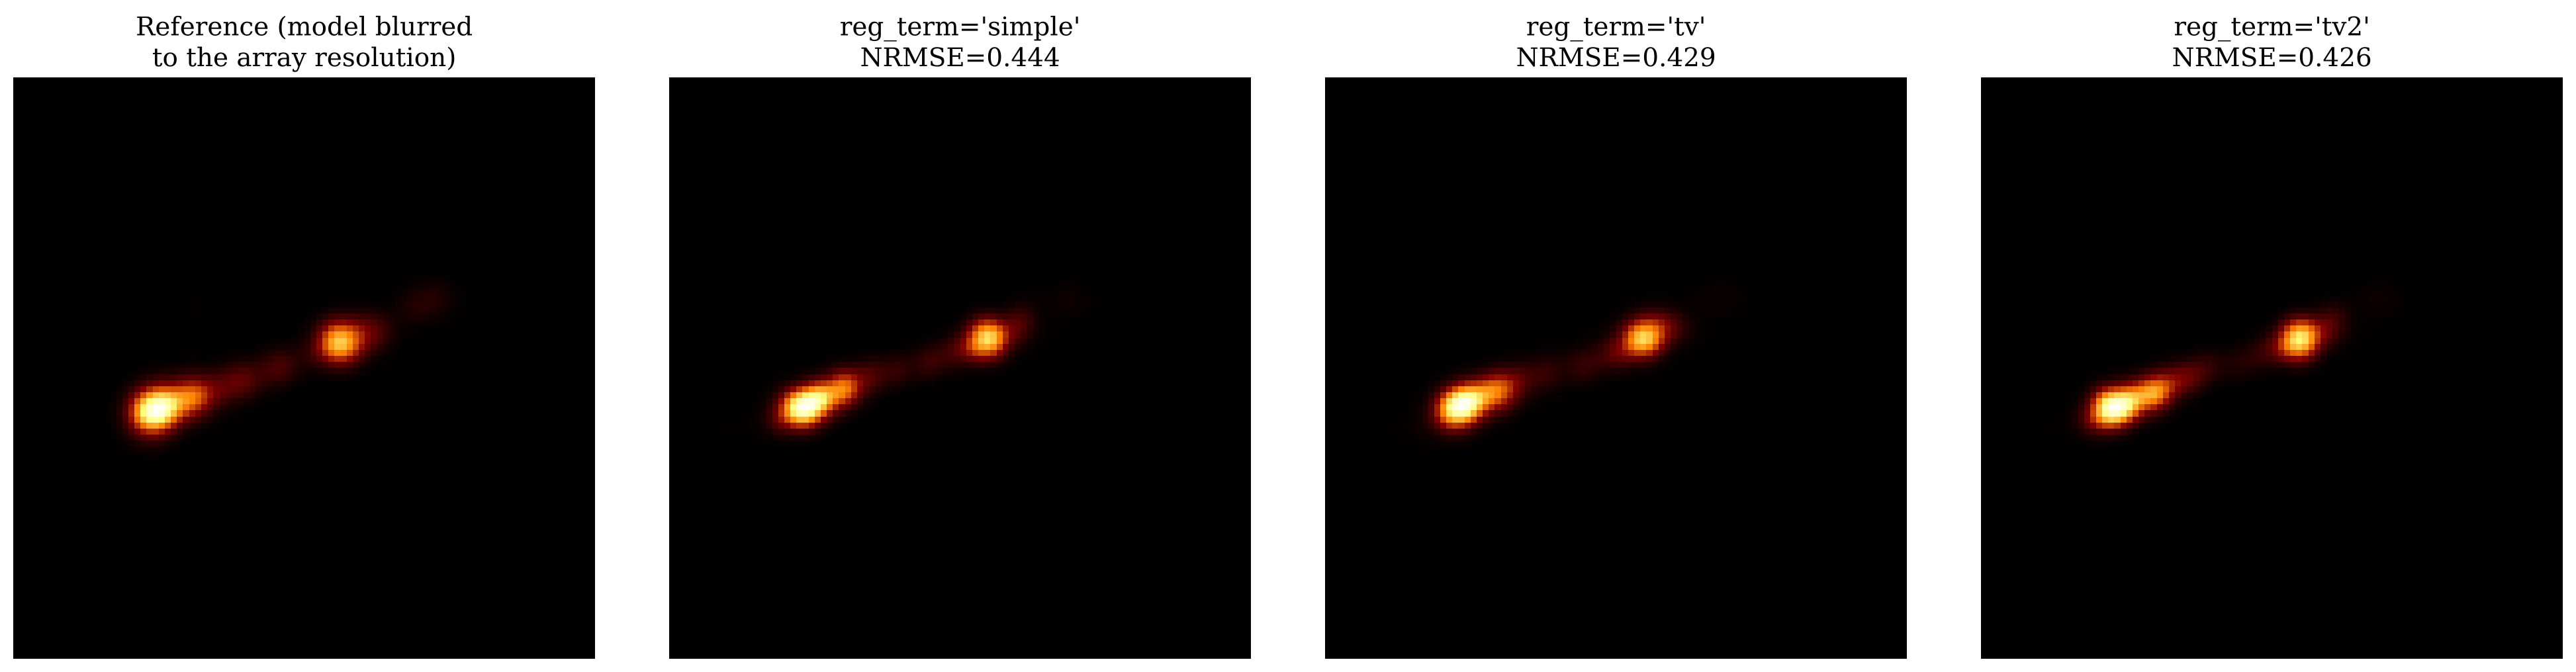

Compare how sharply the jet's edges come through in each panel. 'tv' usually gives the
crispest boundaries; 'simple' the smoothest; 'tv2' often lands somewhere in between.
The 'best' choice isn't universal, it depends on whether your source genuinely has sharp
edges (jets, rings) or is intrinsically smooth (diffuse halos), and is itself a modeling choice.


In [16]:
reg_comparison_rounds = {
    'simple': [
        {'data_term': {'bs': 100}, 'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
        {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100, 'blur_frac': 1.0},
    ],
    'tv': [
        {'data_term': {'bs': 100}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
        {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100, 'blur_frac': 1.0},
    ],
    'tv2': [
        {'data_term': {'bs': 100}, 'reg_term': {'tv2': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
        {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv2': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100, 'blur_frac': 1.0},
    ],
}

reg_results = {}
hist_reg = {name: [] for name in reg_comparison_rounds}   # chi^2 per iteration (Section 4.7)
raw_simple_out = None   # raw (unblurred) 'simple' result, reused to initialise 'tv'

for reg_name, rounds in reg_comparison_rounds.items():
    print(f"Reconstructing with reg_term='{reg_name}'...")
    
    # Cascading technique: 'tv' starts from the 'simple' result, because TV started from a smooth Gaussian
    # prior can get stuck in a poor local minimum (piecewise-flat blobs).
    if reg_name == 'tv' and raw_simple_out is not None:
        init_prior = raw_simple_out
        print(" -> Kickstarting 'tv' using the structure from 'simple'...")
    else:
        init_prior = gaussprior
        
    out = run_rml_imager(obs_jet_err, init_prior, zbl, rounds, ttype='fast', history=hist_reg[reg_name])
    
    # Save the raw result from 'simple' before applying blur
    if reg_name == 'simple':
        raw_simple_out = out
        
    blurred_img = out.blur_circ(res_jet)
    reg_results[reg_name] = align_to_model(blurred_img, im_ref)


fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(im_ref.imvec.reshape(im_ref.ydim, im_ref.xdim), cmap='afmhot')
axes[0].set_title("Reference (model blurred\nto the array resolution)", fontsize=14)
axes[0].axis('off')

for ax, reg_name in zip(axes[1:], ['simple', 'tv', 'tv2']):
    img = reg_results[reg_name]
    ax.imshow(img.imvec.reshape(img.ydim, img.xdim), cmap='afmhot')
    ax.set_title(f"reg_term='{reg_name}'\nNRMSE={nrmse(img, im_ref):.3f}", fontsize=14)
    ax.axis('off')

plt.tight_layout()
save_fig(fig, '07_regularizers_simple_tv_tv2')
plt.show()

print("Compare how sharply the jet's edges come through in each panel. 'tv' usually gives the")
print("crispest boundaries; 'simple' the smoothest; 'tv2' often lands somewhere in between.")
print("The 'best' choice isn't universal, it depends on whether your source genuinely has sharp")
print("edges (jets, rings) or is intrinsically smooth (diffuse halos), and is itself a modeling choice.")

### 4.6 How well does each image fit its data? Reduced $\chi^2$

An image can look right and still be inconsistent with the data, or look wrong and fit them perfectly (the raw-visibility images fit visibilities that are corrupted). The reduced $\chi^2$ of each **unblurred** reconstruction against the data it was made from answers this objectively: values close to 1 mean the image explains the data down to the thermal noise; values much larger than 1 mean a mismatch.

We compute it for three data products: closure phases (`cphase`) and log closure amplitudes (`logcamp`), which do not depend on the station gains (so they can be computed on the raw corrupted data), and visibility amplitudes (`amp`), which do, and are therefore computed on the self-calibrated data for B and C.

In [17]:
import io, contextlib

def chi2(im, obs, dtype):
    with contextlib.redirect_stdout(io.StringIO()):
        return obs.chisq(im, dtype=dtype, ttype='fast')

chi2_rows = []
print(f"{'reconstruction':48s} {'cphase':>8s} {'logcamp':>8s} {'amp':>8s}   (amp on: )")
for key, (o_, rounds_, cal_) in runs.items():
    o_amp = cal_ if cal_ is not None else o_
    row = [labels[key], chi2(rec_raw[key], o_, 'cphase'), chi2(rec_raw[key], o_, 'logcamp'), chi2(rec_raw[key], o_amp, 'amp')]
    chi2_rows.append(row)
    print(f"{row[0]:48s} {row[1]:8.2f} {row[2]:8.2f} {row[3]:8.2f}   ({'self-cal data' if cal_ is not None and cal_ is not o_ else 'raw data'})")
print("\nThe closure chi^2 of the raw-visibility images are typically much larger than those of the closure images:")
print("they fit the corrupted visibilities, not the sky, so they are inconsistent with the gain-invariant closures.")

reconstruction                                     cphase  logcamp      amp   (amp on: )


Ideal (closures + hybrid)                           39.49    35.69   745.60   (raw data)


Scenario A (thermal only, closures + hybrid)        49.60    44.60   731.32   (raw data)


Scenario B (closures + hybrid self-cal)             41.84    31.42   206.70   (self-cal data)


Scenario B (raw visibilities)                    59032.45 48096.01 2508352.65   (raw data)


Scenario C (closures + hybrid self-cal)             32.07    26.40   154.01   (self-cal data)


Scenario C (raw visibilities)                    60953.12 46475.28 2189987.87   (raw data)

The closure chi^2 of the raw-visibility images are typically much larger than those of the closure images:
they fit the corrupted visibilities, not the sky, so they are inconsistent with the gain-invariant closures.


### 4.7 Convergence of the data fit, iteration by iteration

The reduced $\chi^2$ of Section 4.6 is only the *end point* of each reconstruction. It is just as instructive to look at **how** the optimizer gets there. While imaging, every reconstruction recorded the reduced $\chi^2$ of each of its active data terms at every L-BFGS-B iteration (through `LoggedImager`). The figure below shows these histories for **all nine reconstructions of this notebook** (the six of Section 4.2 and the three regularizer tests of Section 4.5), all made with the **EVN + AVN + SKA-Mid** array.

How to read it:

- The x-axis counts the iterations cumulatively over the imaging rounds; **dashed vertical lines** mark the start of a new round (a new data term, a re-blurred prior or, in round 3, the switch to self-calibrated data). The **dotted horizontal line** is $\chi^2 = 1$, a fit down to the thermal noise.
- A **jump** at the start of a round is expected: a newly added data term (e.g. `amp` or `logcamp`) starts far from its optimum, and blurring the image to restart the next round always worsens the fit for a few iterations.
- A curve that **flattens well above 1** means that the image cannot explain those data: for the raw-visibility runs of Scenarios B and C, `vis` stays high because the corrupted phases are not consistent with *any* sky image.
- A curve that **drops below 1** signals over-fitting of the noise (usually harmless at these SNRs, but worth knowing).

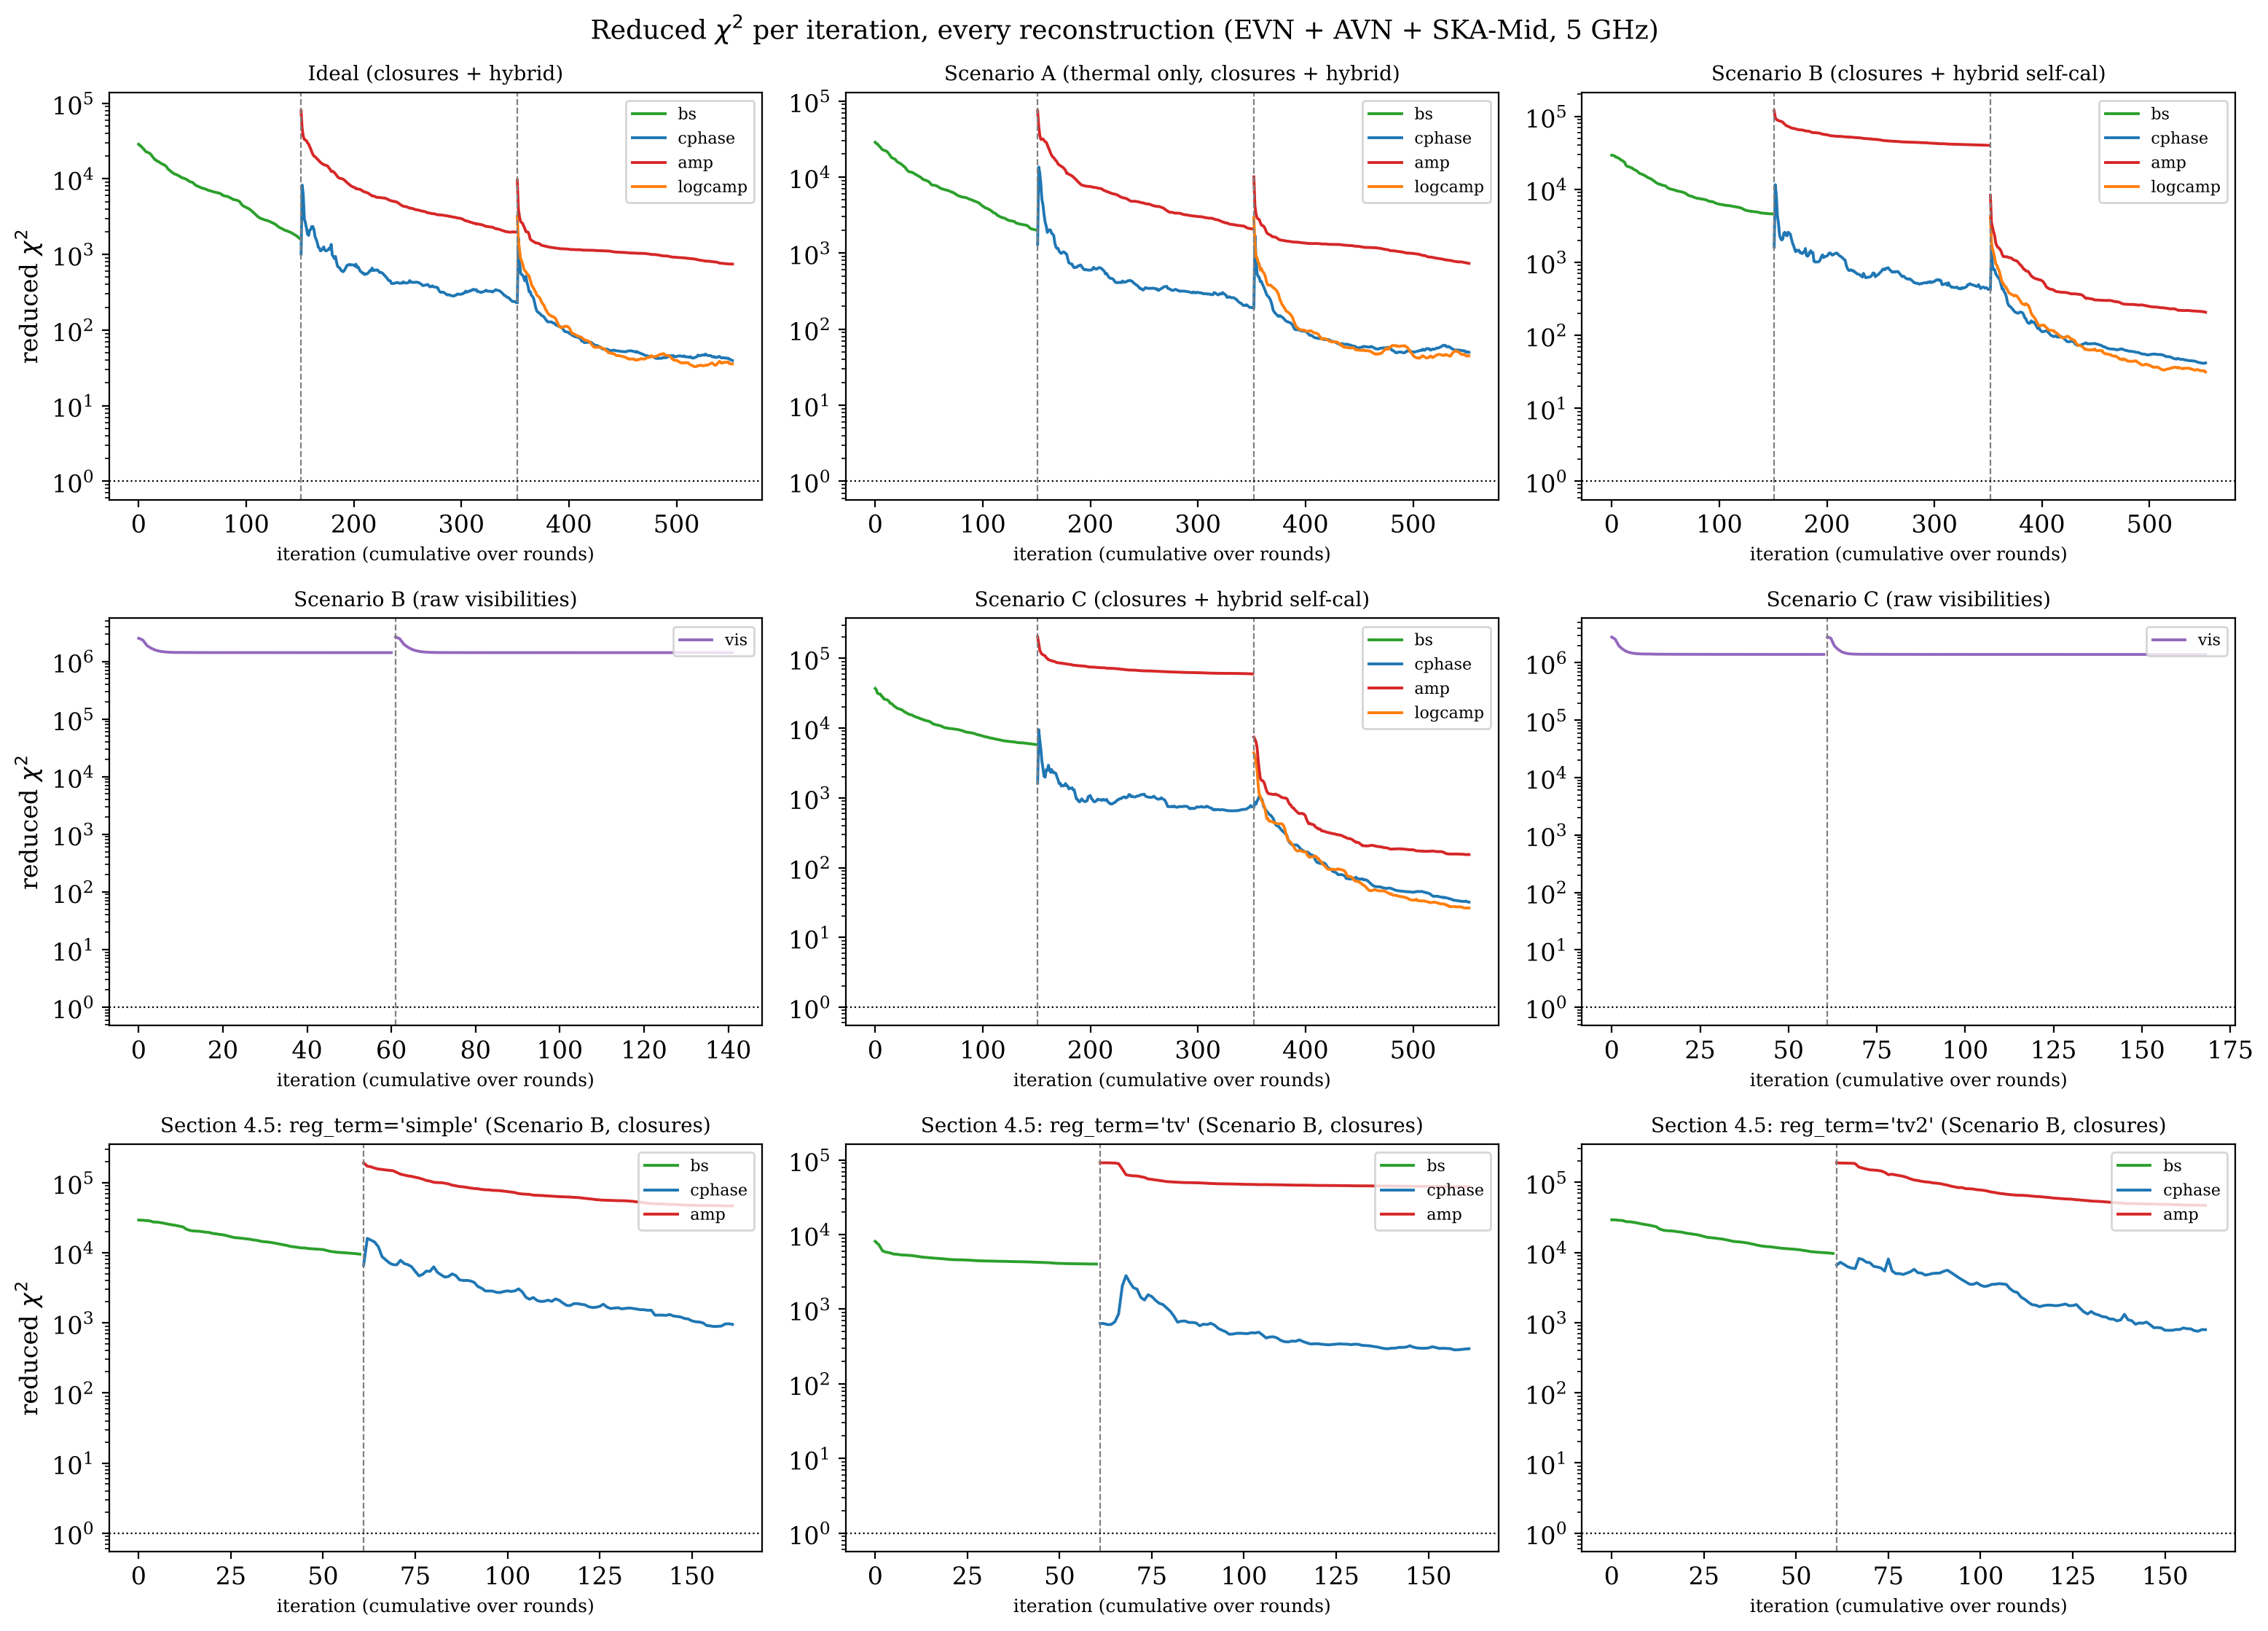

Ideal (closures + hybrid)                                     553 iterations  ->  final: cphase=39.49, logcamp=35.69, amp=745.60
Scenario A (thermal only, closures + hybrid)                  553 iterations  ->  final: cphase=49.60, logcamp=44.60, amp=731.32
Scenario B (closures + hybrid self-cal)                       553 iterations  ->  final: cphase=41.84, logcamp=31.42, amp=206.70
Scenario B (raw visibilities)                                 142 iterations  ->  final: vis=1416712.69
Scenario C (closures + hybrid self-cal)                       553 iterations  ->  final: cphase=32.07, logcamp=26.40, amp=154.01
Scenario C (raw visibilities)                                 169 iterations  ->  final: vis=1397647.99
Section 4.5: reg_term='simple' (Scenario B, closures)         162 iterations  ->  final: cphase=950.52, amp=46650.96
Section 4.5: reg_term='tv' (Scenario B, closures)             162 iterations  ->  final: cphase=295.89, amp=43768.63
Section 4.5: reg_term='tv2' (Scenario B, c

In [18]:
titles_all = {**labels, **{f'reg_{k}': f"Section 4.5: reg_term='{k}' (Scenario B, closures)" for k in hist_reg}}
hists_all = {**hist_class, **{f'reg_{k}': v for k, v in hist_reg.items()}}
plot_chi2_histories(hists_all, titles_all, '07b_chi2_convergence_all_reconstructions',
                    'Reduced $\\chi^2$ per iteration, every reconstruction (EVN + AVN + SKA-Mid, 5 GHz)', ncols=3)

for k, h in hists_all.items():
    last = h[-1]
    terms = ', '.join(f"{t}={last[t]:.2f}" for t in CHI2_COLORS if t in last)
    print(f"{titles_all[k]:60s} {len(h):4d} iterations  ->  final: {terms}")

### 4.8 Self-calibration to the final images: how well do the closures work?

A practical test of everything above: **use the images as self-calibration models and look at the calibrated visibilities.** If a closure-based image is right (up to the resolution of the array), self-calibrating the raw data to it should give visibilities almost as good as self-calibrating to the true jet (the "oracle" calibration of Sections 3.2 and 3.5).

For Scenarios A, B and C, the **raw** data are self-calibrated (amplitude and phase, one gain per station and scan) to two models, both **unblurred** and made with the **EVN + AVN + SKA-Mid**:

1. a **closures-only image**, made here with closure phases and log closure amplitudes only (`cphase` + `logcamp`, three rounds, no calibration at any stage): a direct test of what the closures alone recover;
2. the **final image of the closures + hybrid self-cal pipeline** of Section 4.2 (the last image generated for each scenario).

Closures do not fix the absolute position of the source, and a shifted model would simply shift the calibrated data (a shift is a pure antenna-based phase gradient), so each model is first moved (sub-pixel) to the position of the true jet.

The calibrated visibilities are compared with the **noise-free visibilities of the true jet** (`obs_jet_ideal`, same schedule):

* the **reduced $\chi^2$ against the truth**, $\langle |V_\mathrm{cal}-V_\mathrm{true}|^2/\sigma^2\rangle/2$: ≈ 1 means the calibrated data differ from the true visibilities only by thermal noise;
* the **median amplitude error** [%] and **median phase error** [deg] on baselines with SNR > 5;

for the raw data, the two self-calibrations and the oracle (for A, which has no gain errors, the oracle is the data themselves). Finally each calibrated dataset is **imaged with the raw-visibility recipe** (`jet_vis_rounds`), recording the $\chi^2$ at every iteration. Expect ~10–15 minutes for this cell.

Closures-only imaging, Scenario A...
Initializing imager data products . . .


Closures-only imaging, Scenario B...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Closures-only imaging, Scenario C...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Imaging the visibilities of 'A: self-cal to closures-only image'...
Initializing imager data products . . .


Imaging the visibilities of 'A: self-cal to final pipeline image'...
Initializing imager data products . . .


Imaging the visibilities of 'B: self-cal to closures-only image'...
Initializing imager data products . . .


... (3 outputs left out)


sc.  visibilities                            model shift  chi2 vs truth  amp err [%]  phase err [deg]
A    raw data (no calibration)                                     1.00         0.32             0.18
A    self-cal to closures-only image           4.836 mas       21304.22        13.90             1.92
A    self-cal to final pipeline image          3.294 mas        7537.08         8.14             3.33
A    oracle (A: data already calibrated)                           1.00         0.32             0.18
B    raw data (no calibration)                               3041588.97        11.33            87.89
B    self-cal to closures-only image           4.562 mas       24190.01        14.52             1.65
B    self-cal to final pipeline image          3.417 mas        4135.32         6.03             1.38
B    oracle (true model)                                           8.81         0.48             0.23
C    raw data (no calibration)                               3533085.29        11

  B: closures-only image                     NRMSE = 0.432   total flux = 1.001 Jy
  C: closures-only image                     NRMSE = 0.448   total flux = 1.001 Jy
  A: self-cal to closures-only image         NRMSE = 0.401   total flux = 0.998 Jy


  A: self-cal to final pipeline image        NRMSE = 0.391   total flux = 1.010 Jy
  B: self-cal to closures-only image         NRMSE = 0.407   total flux = 0.998 Jy
  B: self-cal to final pipeline image        NRMSE = 0.404   total flux = 1.004 Jy


  C: self-cal to closures-only image         NRMSE = 0.404   total flux = 0.998 Jy
  C: self-cal to final pipeline image        NRMSE = 0.401   total flux = 1.001 Jy


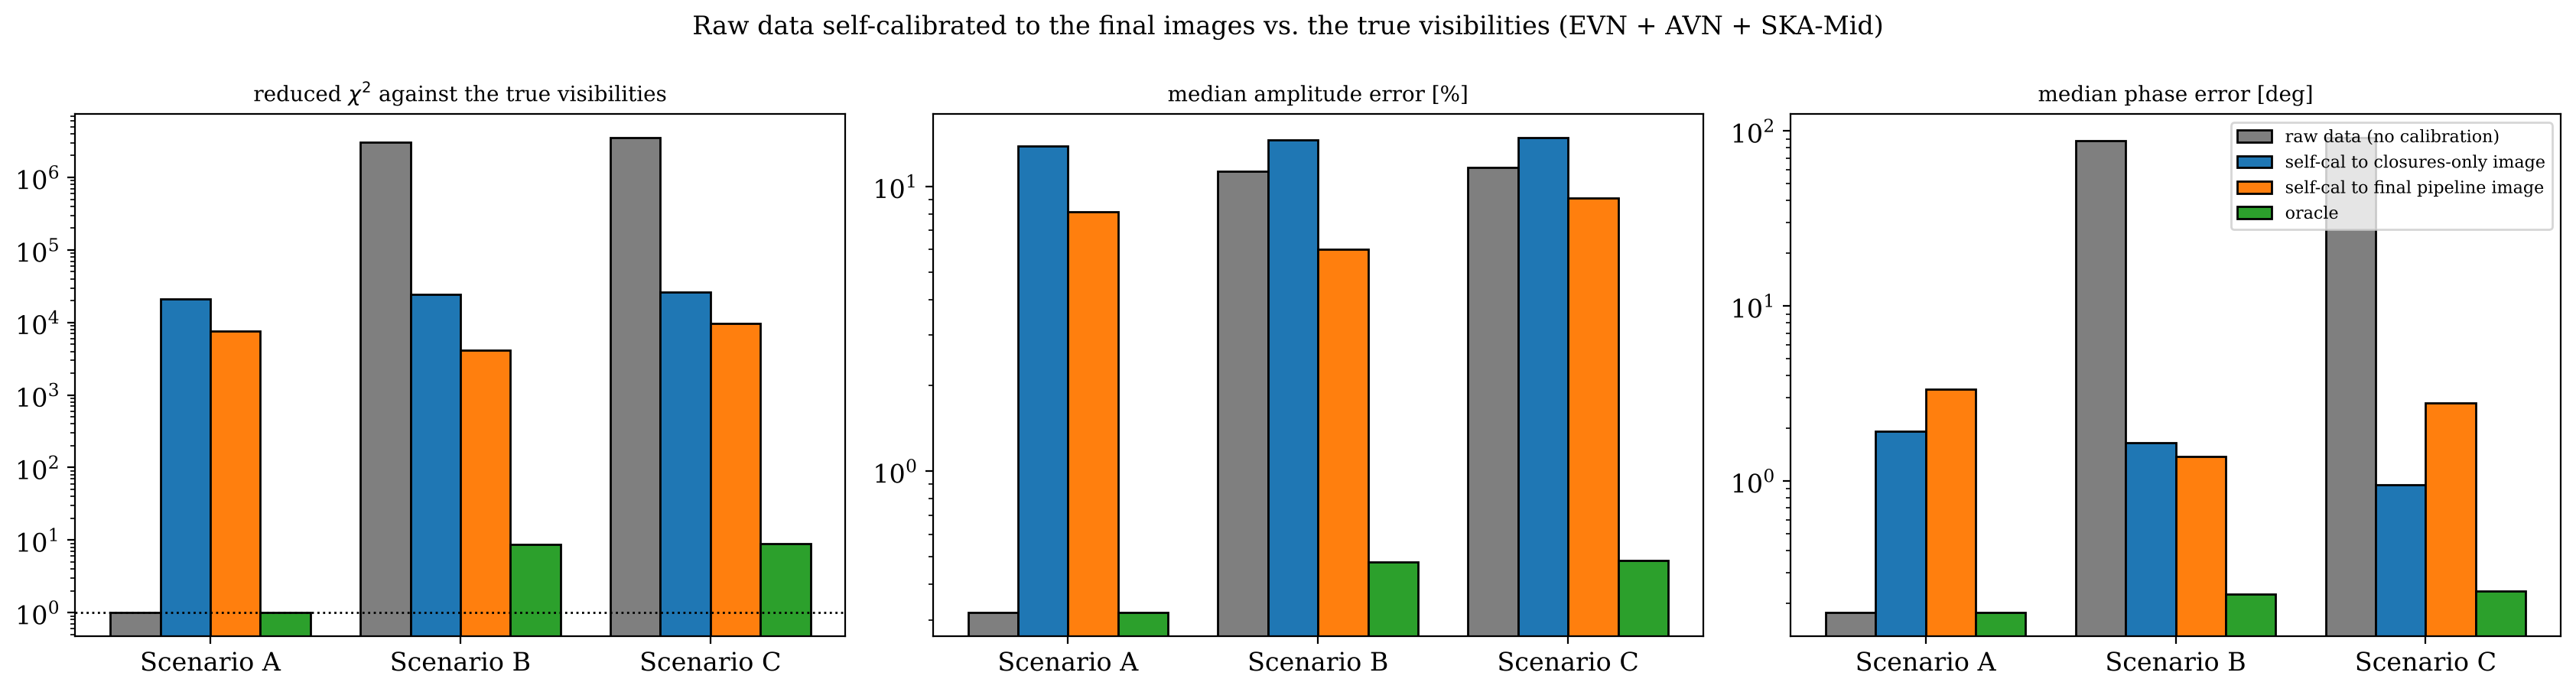

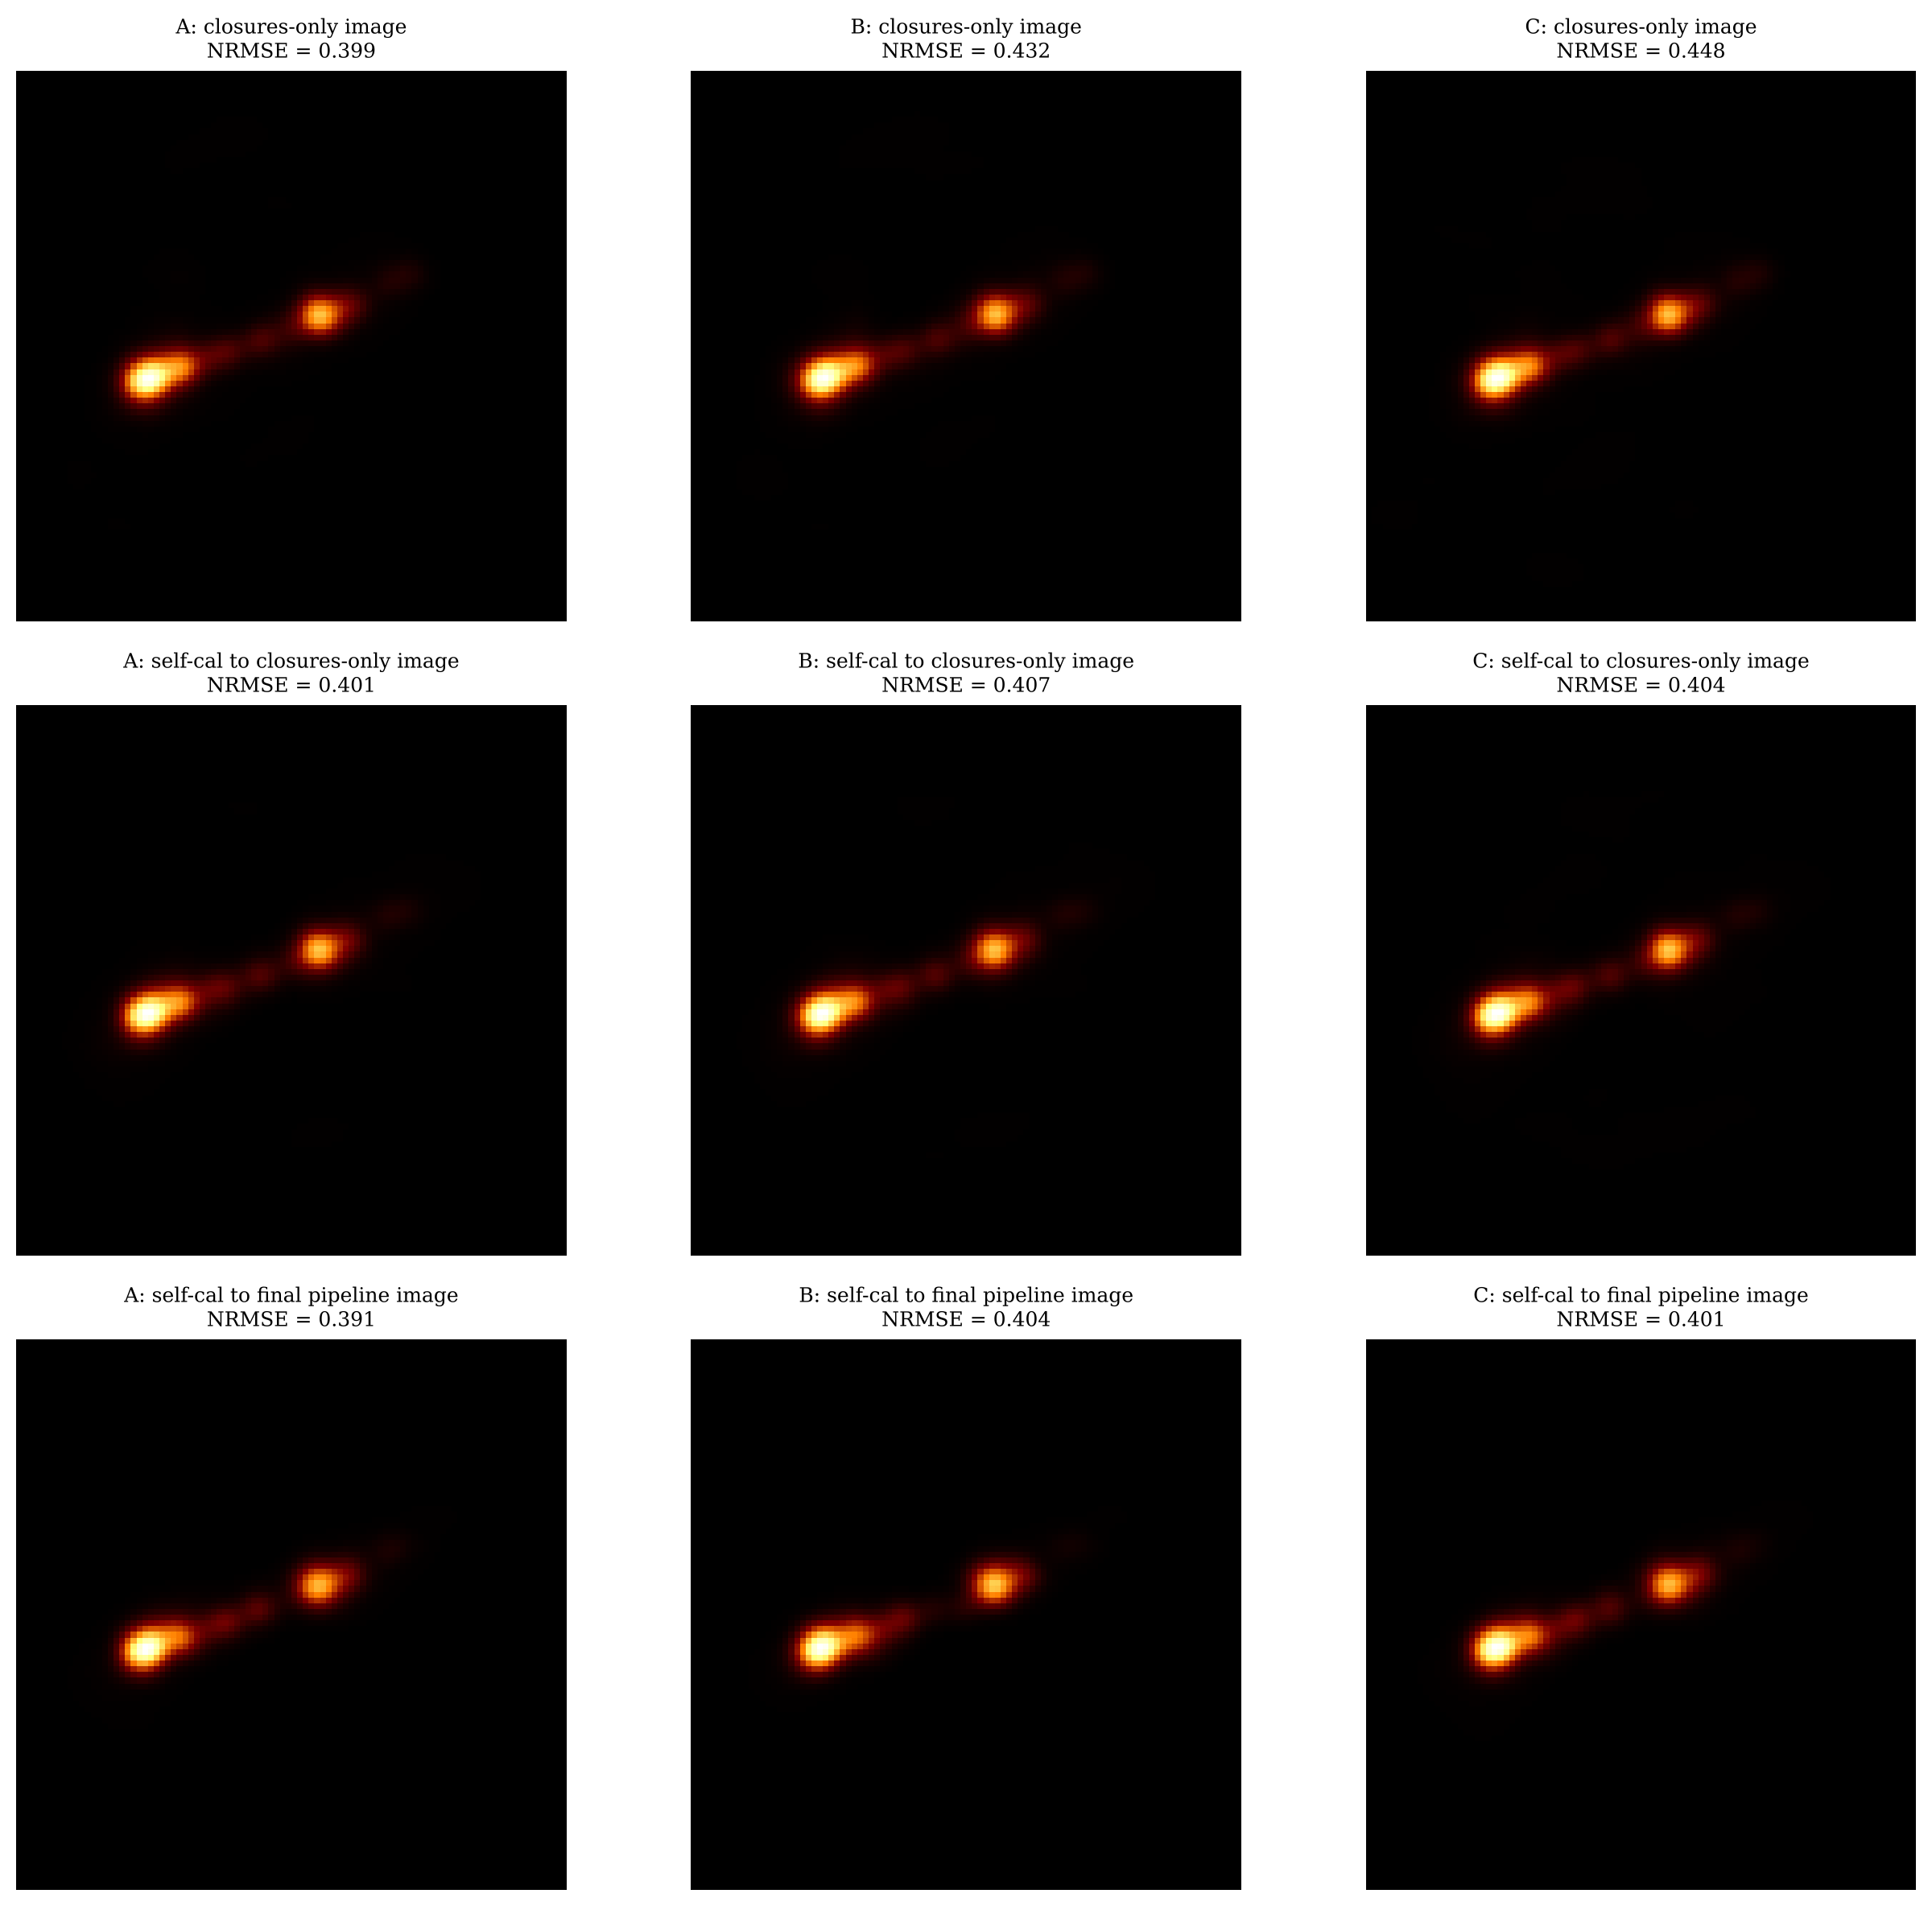

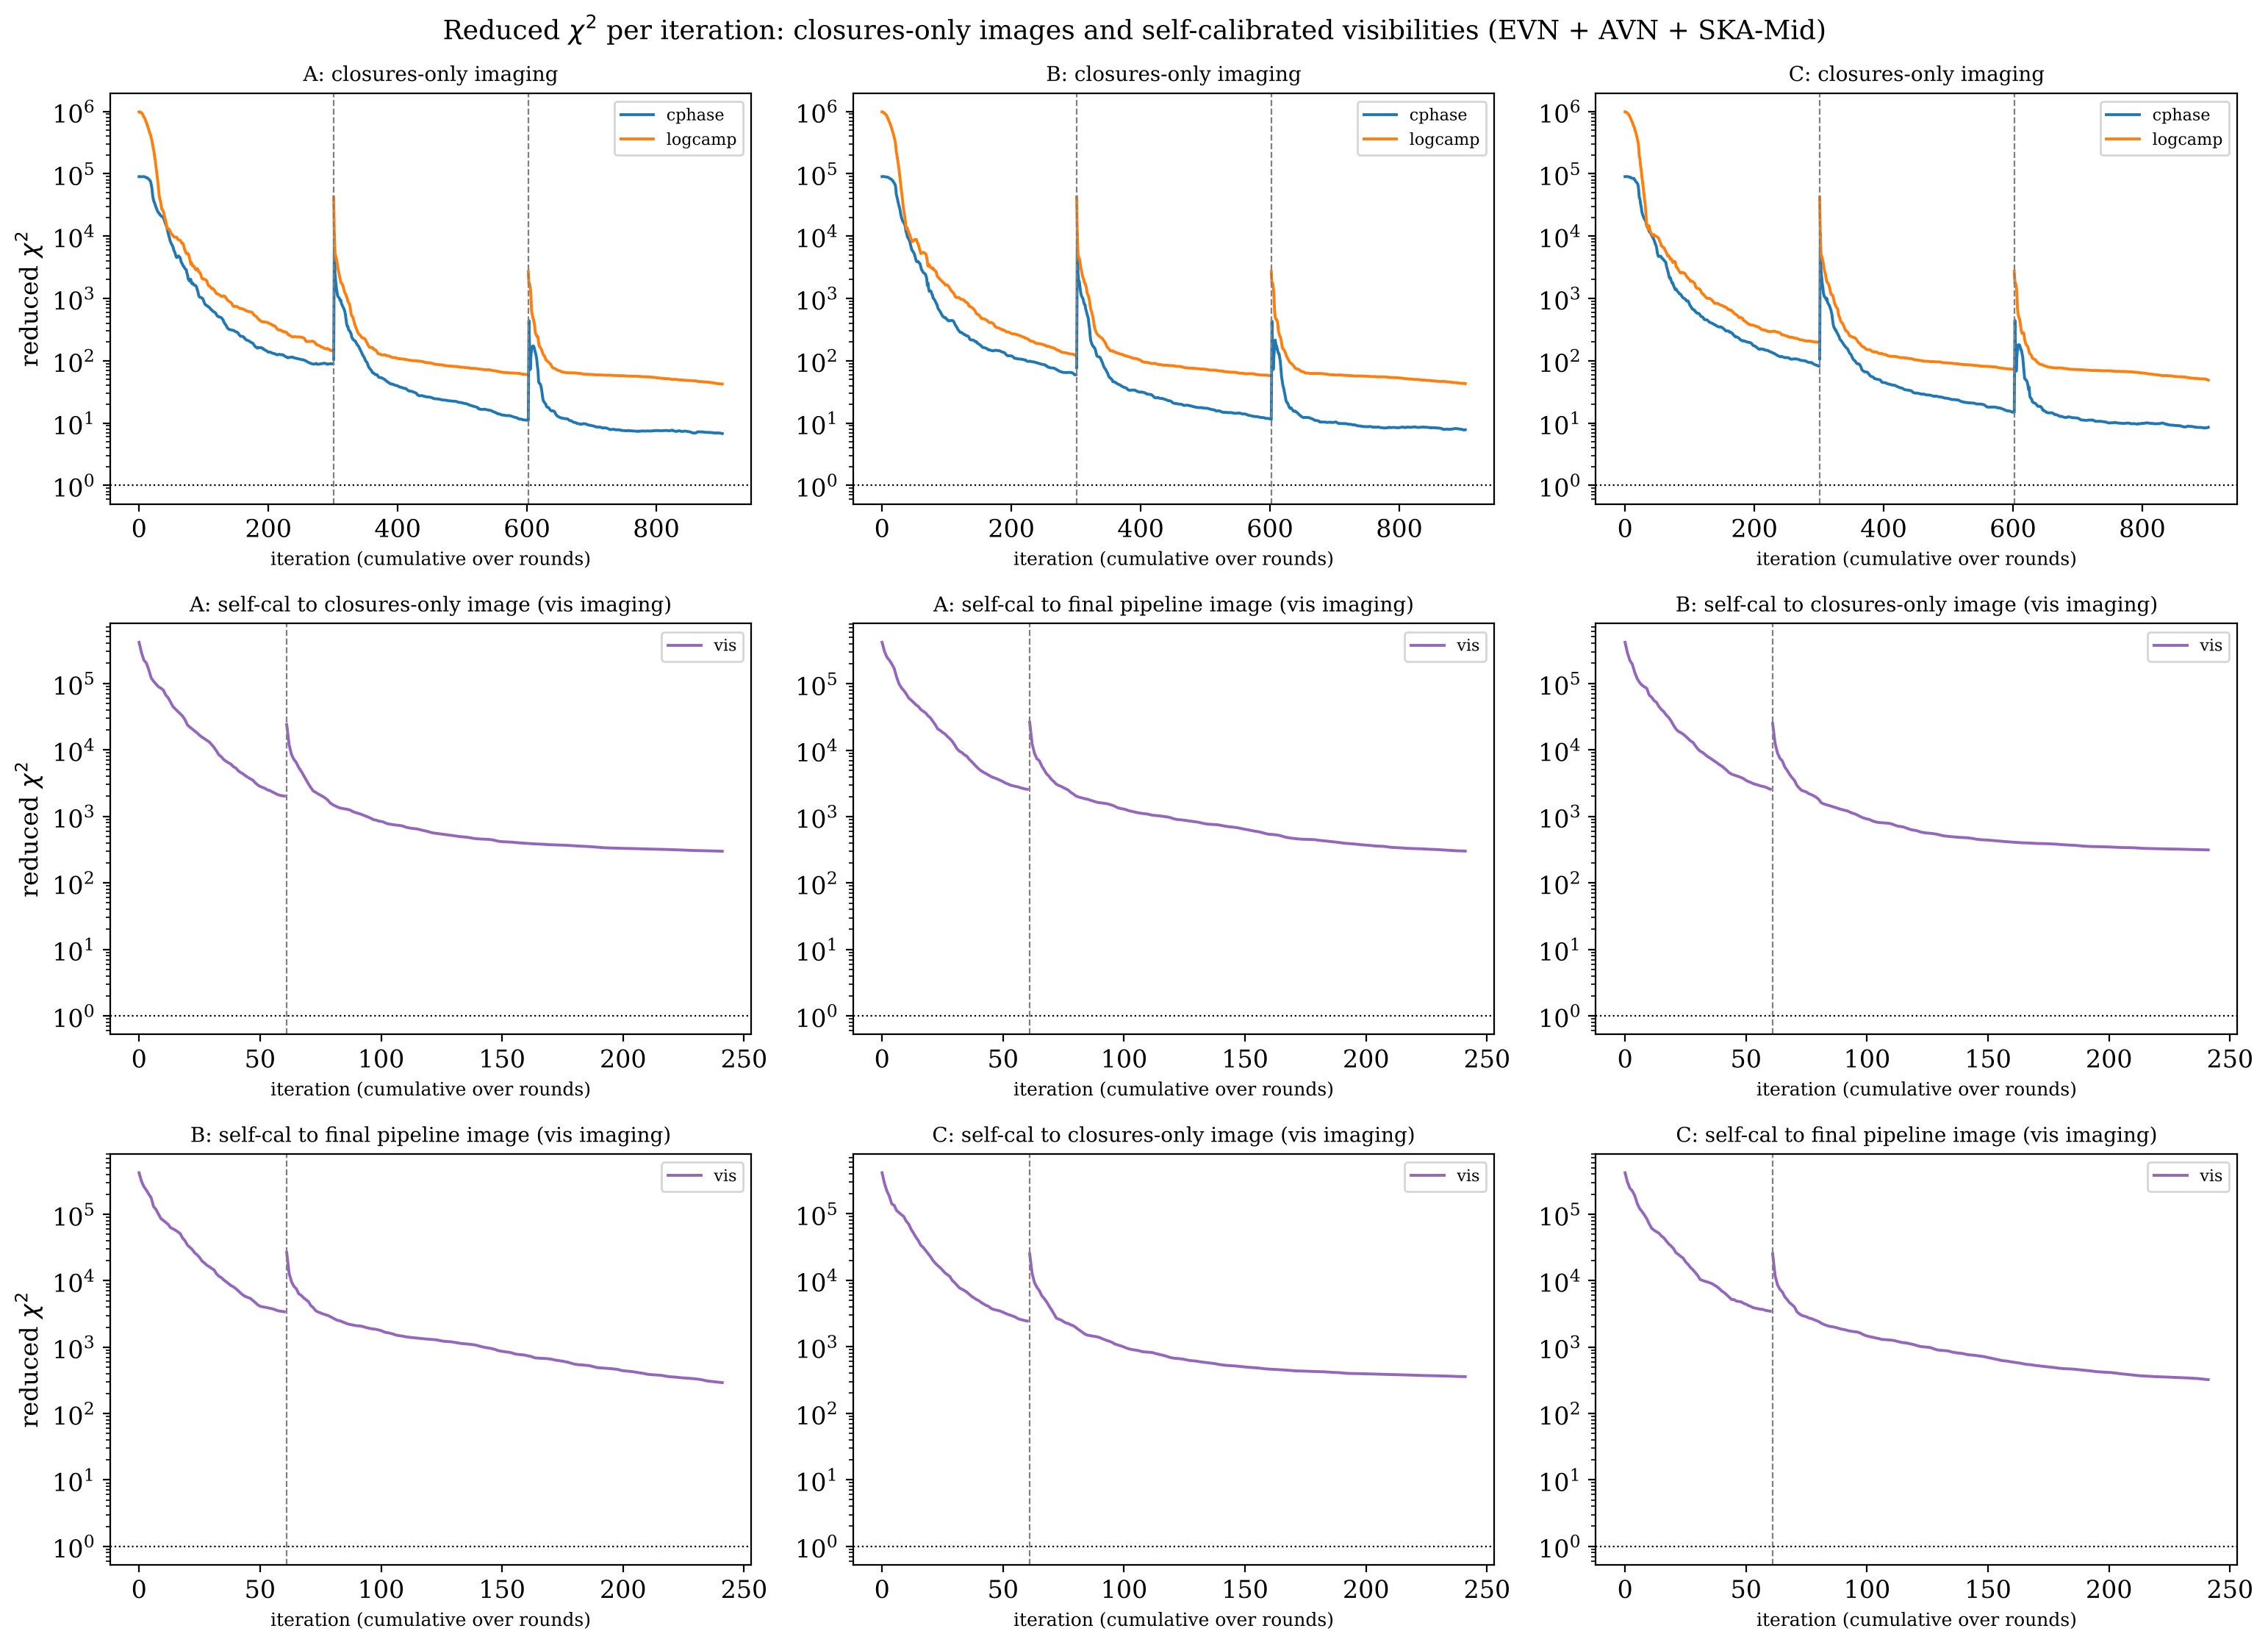

Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


In [19]:
from scipy import ndimage
import io, contextlib, csv
mas_ = eh.RADPERUAS*1e3

def align_subpixel(im_model, im_truth):
    """Shift im_model (sub-pixel, Fourier shift) to the position that maximises its cross-correlation with im_truth."""
    a = im_model.imvec.reshape(im_model.ydim, im_model.xdim); b = im_truth.imvec.reshape(im_truth.ydim, im_truth.xdim)
    cc = np.real(np.fft.ifft2(np.fft.fft2(b)*np.conj(np.fft.fft2(a))))
    ny, nx = cc.shape; iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    parab = lambda m, c, p: 0.5*(m - p)/(m - 2*c + p) if (m - 2*c + p) != 0 else 0.0
    dy = iy + parab(cc[(iy-1) % ny, ix], cc[iy, ix], cc[(iy+1) % ny, ix])
    dx = ix + parab(cc[iy, (ix-1) % nx], cc[iy, ix], cc[iy, (ix+1) % nx])
    dy = dy - ny if dy > ny/2 else dy; dx = dx - nx if dx > nx/2 else dx
    sh = np.clip(np.real(np.fft.ifft2(ndimage.fourier_shift(np.fft.fft2(a), (dy, dx)))), 0, None)
    out = im_model.copy(); out.imvec = (sh*im_model.total_flux()/sh.sum()).ravel()
    return out, np.hypot(dy, dx)*im_model.psize/mas_

def vis_errors(o, ref, snr_min=5.0):
    """Visibilities of `o` vs. the noise-free visibilities of `ref` (same schedule):
    reduced chi^2 of the complex difference, median amplitude error [%] and median phase error [deg]."""
    key = lambda d: list(zip(np.round(d['time']*3600).astype(int), d['t1'], d['t2']))
    r = dict(zip(key(ref.data), ref.data['vis']))
    kk = key(o.data); m = np.array([k in r for k in kk])
    v, s = o.data['vis'][m], o.data['sigma'][m]
    vt = np.array([r[k] for k, mm in zip(kk, m) if mm])
    hi = np.abs(vt)/s > snr_min
    return (float(np.mean(np.abs(v - vt)**2/s**2)/2),
            float(np.median(np.abs(np.abs(v[hi])/np.abs(vt[hi]) - 1))*100),
            float(np.median(np.abs(np.degrees(np.angle(v[hi]*np.conj(vt[hi])))))))

# Closures-only imaging (cphase + logcamp): closures carry no flux information, so the flux constraint is strong.
closures_only_rounds = [
    {'data_term': {'cphase': 100, 'logcamp': 50}, 'reg_term': {'simple': 10, 'flux': 1e7, 'cm': 50}, 'maxit': 300},
    {'data_term': {'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 1, 'flux': 1e7, 'cm': 50}, 'maxit': 300, 'blur_frac': 1.0},
    {'data_term': {'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 1, 'flux': 1e7, 'cm': 50}, 'maxit': 300, 'blur_frac': 0.5},
]
raw_obs    = {'A': obs_jet_thA, 'B': obs_jet_err, 'C': obs_jet_errC}
oracle_obs = {'A': obs_jet_thA, 'B': cal_jet,     'C': cal_jet_errC}
final_key  = {'A': 'thA', 'B': 'err_closure', 'C': 'errC_closure'}
truth_grid = im_jet.regrid_image(fov_jet, npix_jet); truth_grid.imvec *= zbl/truth_grid.total_flux()

hist_cl, rec_cl = {}, {}
for s_, o_ in raw_obs.items():
    o_.add_scans()                                   # needed by self_cal(..., scan_solutions=True)
    print(f"Closures-only imaging, Scenario {s_}...")
    hist_cl[s_] = []
    rec_cl[s_] = run_rml_imager(o_, gaussprior, zbl, closures_only_rounds, ttype='fast', history=hist_cl[s_])

sc_cal, sc_recs, sc_hist, sc_rows = {}, {}, {}, []
for s_ in 'ABC':
    sc_rows.append((s_, 'raw data (no calibration)', np.nan) + vis_errors(raw_obs[s_], obs_jet_ideal))
    for mname, model0 in (('closures-only image', rec_cl[s_]), ('final pipeline image', rec_raw[final_key[s_]])):
        model, shift = align_subpixel(model0, truth_grid)
        with contextlib.redirect_stdout(io.StringIO()):
            cal = sc.self_cal(raw_obs[s_], model, method='both', ttype='fast', scan_solutions=True, processes=1)
        sc_cal[(s_, mname)] = cal
        sc_rows.append((s_, f'self-cal to {mname}', shift) + vis_errors(cal, obs_jet_ideal))
        lab = f'{s_}: self-cal to {mname}'
        print(f"Imaging the visibilities of '{lab}'...")
        sc_hist[lab] = []
        sc_recs[lab] = run_rml_imager(cal, gaussprior, zbl, jet_vis_rounds, ttype='fast', history=sc_hist[lab])
    sc_rows.append((s_, 'oracle (true model)' if s_ != 'A' else 'oracle (A: data already calibrated)', np.nan)
                   + vis_errors(oracle_obs[s_], obs_jet_ideal))

print(f"\n{'sc.':4s} {'visibilities':38s} {'model shift':>12s} {'chi2 vs truth':>14s} {'amp err [%]':>12s} {'phase err [deg]':>16s}")
for s_, name, shift, chi2_t, a_err, p_err in sc_rows:
    sh = '' if np.isnan(shift) else f'{shift:.3f} mas'
    print(f"{s_:4s} {name:38s} {sh:>12s} {chi2_t:14.2f} {a_err:12.2f} {p_err:16.2f}")

print("\nNRMSE against the reference image (lower is better):")
sc_img_rows = []
for lab, im in [*((f'{s_}: closures-only image', rec_cl[s_]) for s_ in 'ABC'), *sc_recs.items()]:
    al = align_to_model(im.blur_circ(res_jet), im_ref)
    sc_img_rows.append((lab, nrmse(al, im_ref), im.total_flux()))
    print(f"  {lab:42s} NRMSE = {sc_img_rows[-1][1]:.3f}   total flux = {im.total_flux():.3f} Jy")

# ---- Figure: visibility errors per scenario and calibration
groups = ['raw data (no calibration)', 'self-cal to closures-only image', 'self-cal to final pipeline image', 'oracle']
gcol = ['tab:gray', 'tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for j, (col, ttl) in enumerate([(3, r'reduced $\chi^2$ against the true visibilities'), (4, 'median amplitude error [%]'),
                                (5, 'median phase error [deg]')]):
    for g, (gname, c) in enumerate(zip(groups, gcol)):
        vals = [next(r[col] for r in sc_rows if r[0] == s_ and r[1].startswith(gname)) for s_ in 'ABC']
        ax[j].bar(np.arange(3) + (g - 1.5)*0.2, vals, 0.2, color=c, edgecolor='k', label=gname)
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(['Scenario A', 'Scenario B', 'Scenario C'])
    ax[j].set_yscale('log'); ax[j].set_title(ttl, fontsize=10)
ax[0].axhline(1, color='k', ls=':', lw=1); ax[2].legend(fontsize=8)
fig.suptitle('Raw data self-calibrated to the final images vs. the true visibilities (EVN + AVN + SKA-Mid)', fontsize=12)
plt.tight_layout(); save_fig(fig, '07c_selfcal_to_final_images_visibility_errors'); plt.show()

# ---- Figure: closures-only images and images of the self-calibrated visibilities
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for c_, s_ in enumerate('ABC'):
    for r_, (lab, im) in enumerate([(f'{s_}: closures-only image', rec_cl[s_]),
                                    (f'{s_}: self-cal to closures-only image', sc_recs[f'{s_}: self-cal to closures-only image']),
                                    (f'{s_}: self-cal to final pipeline image', sc_recs[f'{s_}: self-cal to final pipeline image'])]):
        al = align_to_model(im.blur_circ(res_jet), im_ref)
        axes[r_, c_].imshow(al.imvec.reshape(al.ydim, al.xdim), cmap='afmhot'); axes[r_, c_].axis('off')
        axes[r_, c_].set_title(f"{lab}\nNRMSE = {nrmse(al, im_ref):.3f}", fontsize=9)
plt.tight_layout(); save_fig(fig, '07d_images_closures_only_and_selfcalibrated_visibilities'); plt.show()

# ---- Figure: chi^2 at every iteration (closures-only imaging and imaging of the self-calibrated visibilities)
titles_sc = {**{f'cl_{s_}': f'{s_}: closures-only imaging' for s_ in 'ABC'}, **{k: f'{k} (vis imaging)' for k in sc_hist}}
plot_chi2_histories({**{f'cl_{s_}': hist_cl[s_] for s_ in 'ABC'}, **sc_hist}, titles_sc,
                    '07e_chi2_convergence_closures_only_and_selfcalibrated_visibilities',
                    'Reduced $\\chi^2$ per iteration: closures-only images and self-calibrated visibilities (EVN + AVN + SKA-Mid)', ncols=3)

# ---- Save the calibrated visibilities and the tables (they are also included in the export of Section 7)
for sub_ in ('visibilities', 'tables'):
    os.makedirs(f'{OUT_DIR}/{sub_}', exist_ok=True)
for (s_, mname), cal in sc_cal.items():
    tag = 'closures_image' if mname.startswith('closures') else 'final_pipeline_image'
    cal.save_uvfits(f'{OUT_DIR}/visibilities/jet_scenario{s_}_selfcal_to_{tag}.uvfits')
with open(f'{OUT_DIR}/tables/selfcal_to_final_images_visibility_errors.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['scenario', 'visibilities', 'model_shift_mas', 'chi2_vs_true_vis', 'median_amp_err_pct', 'median_phase_err_deg'])
    w.writerows(sc_rows)

### 4.9 A third pipeline: closures + self-calibrated visibilities (hybrid mapping)

The two pipelines of Section 4.2 are kept as they are: the **closures pipeline** (whose third round uses data self-calibrated to the *true* jet, a best case only possible in a simulation) and the **raw-visibility pipeline**. Section 4.8 added the **closures-only** images. Here we add a third pipeline, built the way it is done with real data: it never uses the true jet, and its last round gives the **self-calibrated complex visibilities** a significant weight. It runs for the Ideal data and for Scenarios A, B and C, with the **EVN + AVN + SKA-Mid**:

| Round | Data | Data terms (weights) | Regularizers | Iterations |
|---|---|---|---|---|
| 1 | raw data | `bs` (100) | `simple` 10, `flux` 1, `cm` 50 | 60 |
| 2 | raw data | `amp` (50) + `cphase` (100) | `tv` 1, `flux` 1, `cm` 50 | 80 |
| — | | **self-calibration** of the raw data to the **round-2 image** (amplitude and phase, one gain per station and scan) | | |
| 3 | self-calibrated data | `vis` (50) + `cphase` (100) + `logcamp` (50) | `tv` 10, `flux` 1, `cm` 50 | 100 |

**Why it is not expected to give the best image.** Self-calibrated visibilities are only as good as the model they were calibrated to. Self-calibration forces the data to agree with the round-2 image, so every error of that image (missing faint knots, a wrong flux distribution) is copied into the data as if it were a gain error. The `vis` term then pulls round 3 back towards the round-2 image, while the closure terms, which self-calibration cannot bias, keep pulling towards the true sky. The pipeline also has a weak flux constraint (`flux` 1: the total flux is set by the amplitudes) and few iterations (60 + 80 + 100). It is the opposite of the 4.2 closures pipeline in every respect, and the comparison shows **why the visibilities should not get much weight until the self-calibration model is good**.

The cell compares, for each scenario, the closures pipeline of 4.2, the closures-only image of 4.8, the raw-visibility pipeline of 4.2 (B and C) and this pipeline, and records the reduced $\chi^2$ of this pipeline at every iteration. Expect ~5 minutes for this cell.



--- Ideal: closures + self-calibrated visibilities ---
  -> Round 1/3: data_term=['bs']
Initializing imager data products . . .


  -> Round 2/3: data_term=['amp', 'cphase']


  -> Round 3/3: data_term=['vis', 'cphase', 'logcamp']


     (data self-calibrated to the image of round 2, amplitude + phase, one gain per station and scan)



--- A: closures + self-calibrated visibilities ---
  -> Round 1/3: data_term=['bs']
Initializing imager data products . . .


  -> Round 2/3: data_term=['amp', 'cphase']


... (11 outputs left out)

Ideal                     0.363                    —               —                          0.319


A                         0.427                0.399               —                          0.338


B                         0.339                0.432           1.590                          0.493


C                         0.374                0.448           0.937                          0.432
(NRMSE against the reference image, lower is better)

        flux [Jy]  chi2 cphase  chi2 logcamp   chi2 vis  NRMSE round 2   (4.9 pipeline)
Ideal       1.048       282.43        314.01    1769.18          0.477
A           1.052       302.49        271.52    1775.70          0.382
B           0.978       235.23        277.53    1315.52          0.444
C           0.854       368.29        460.55    2354.07          0.460
(cphase and logcamp on the raw data; vis on the data self-calibrated to the round-2 image)


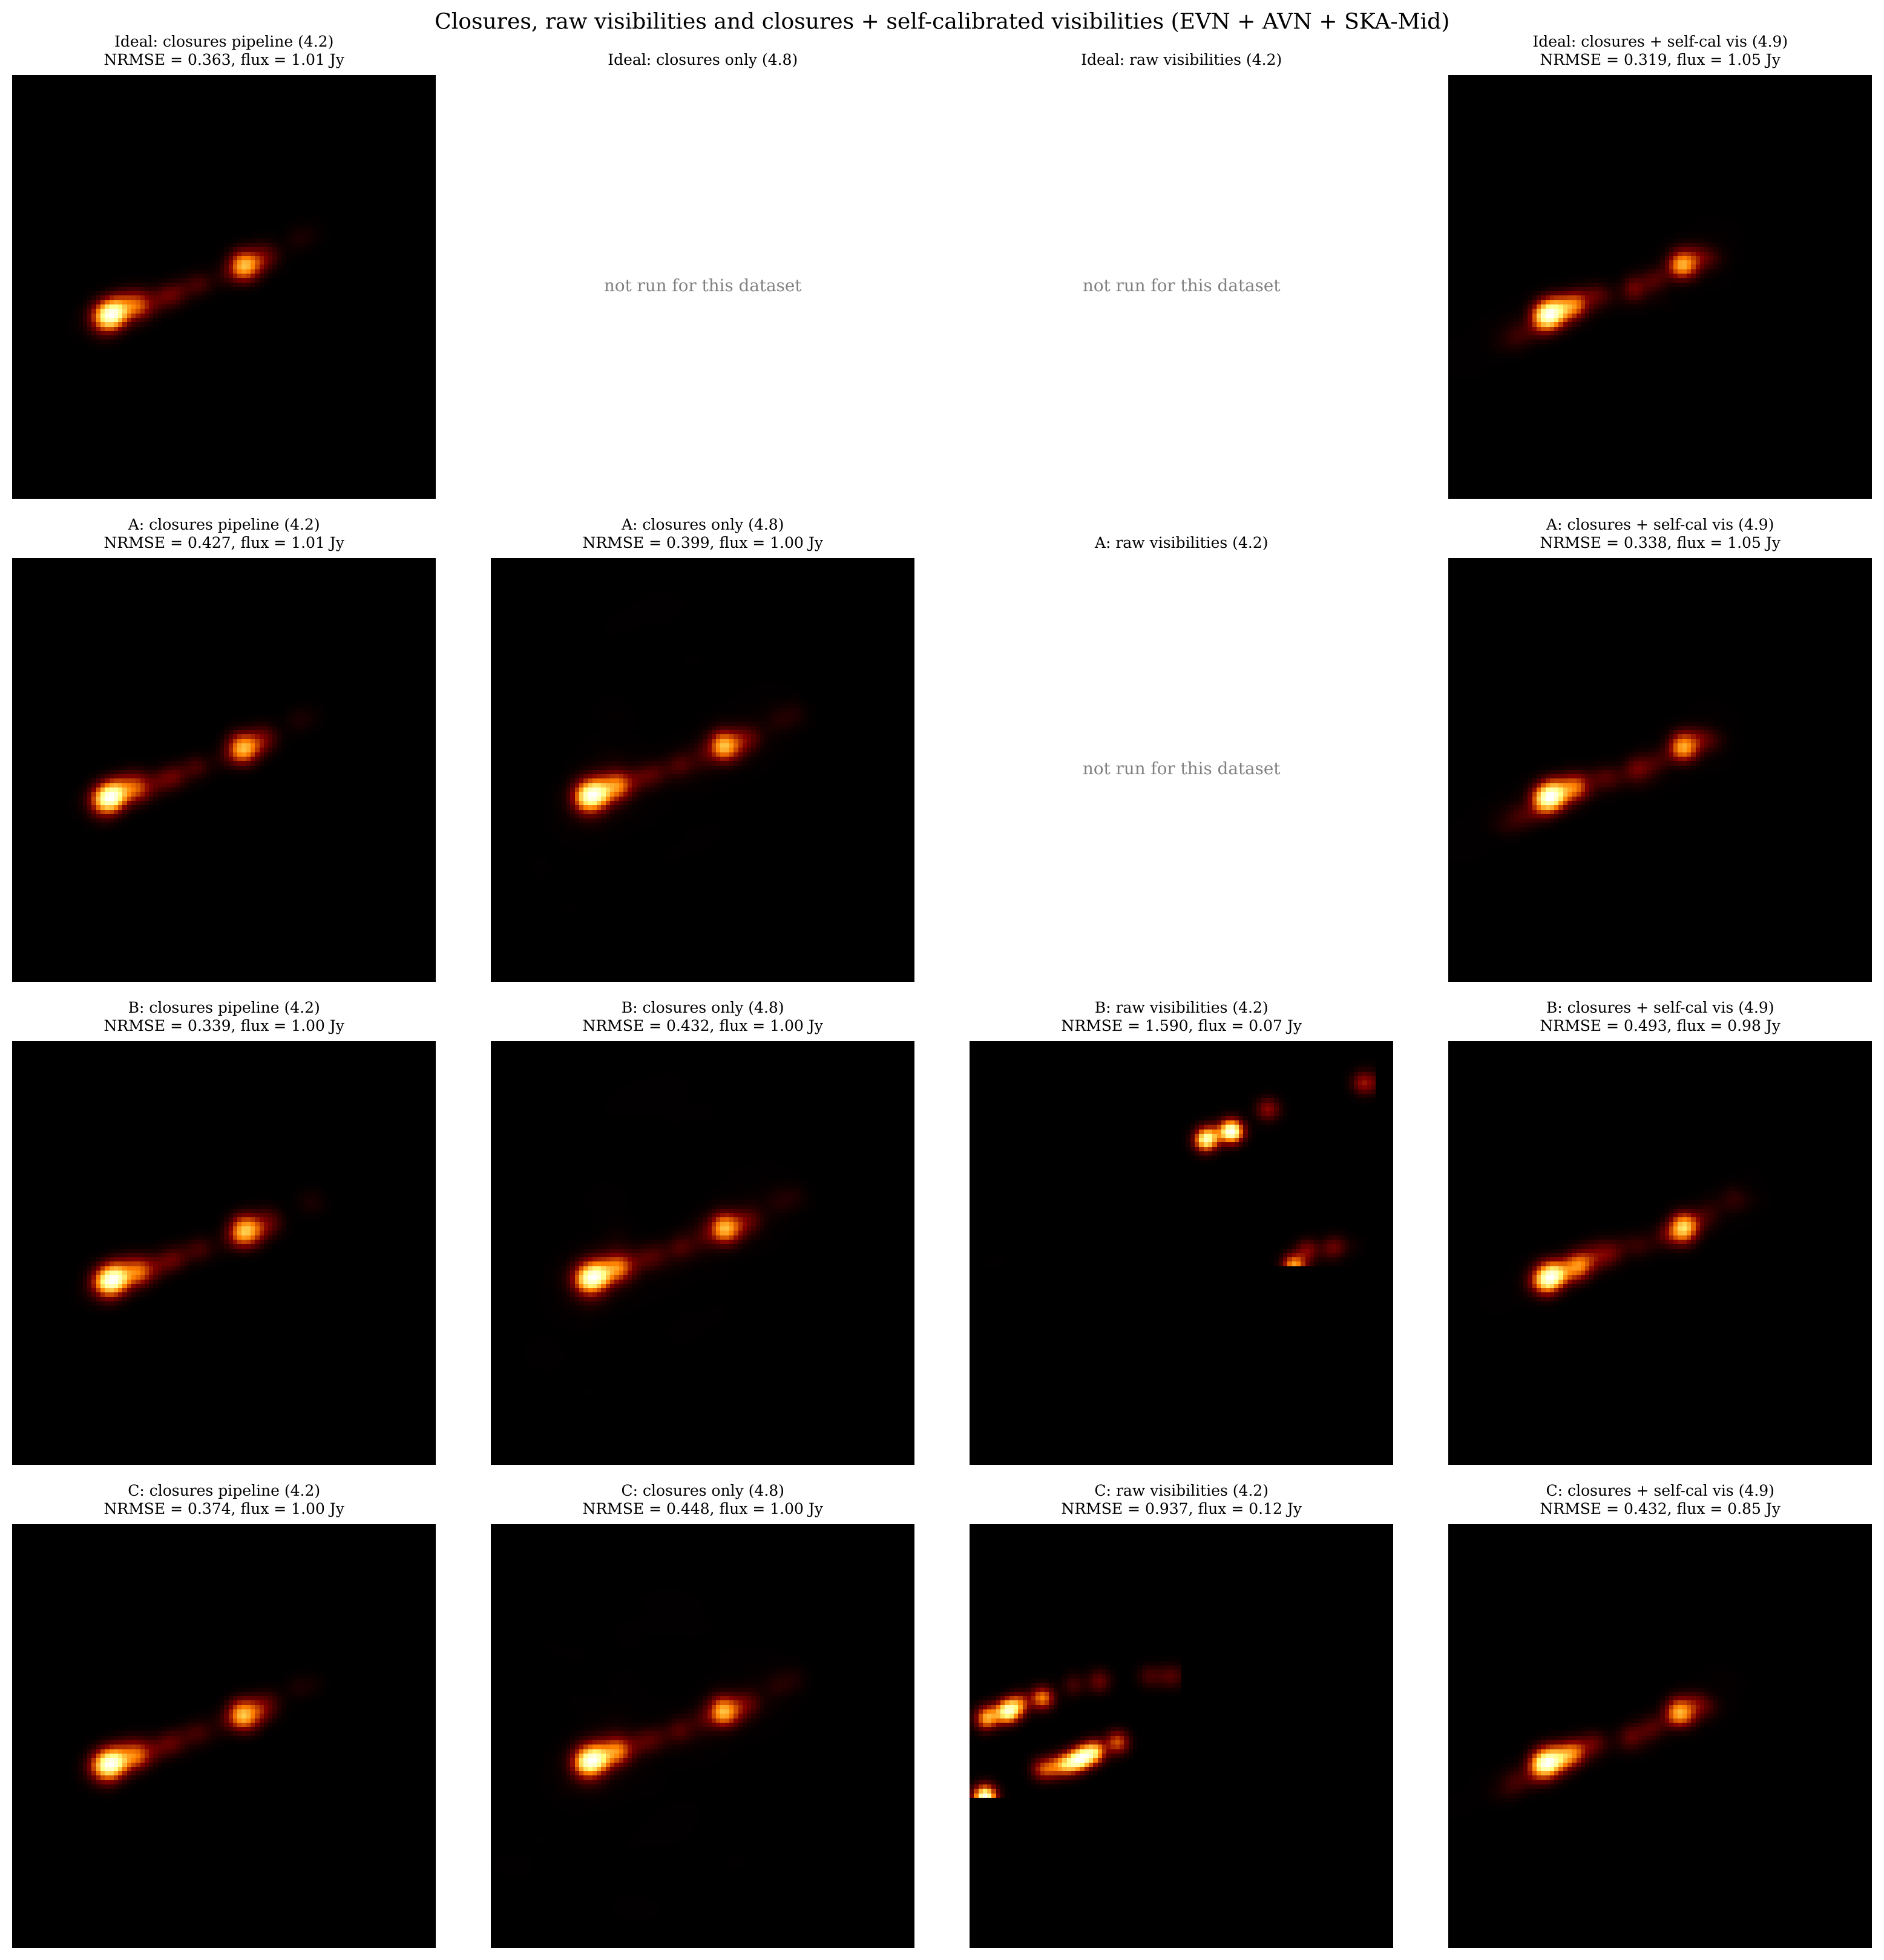

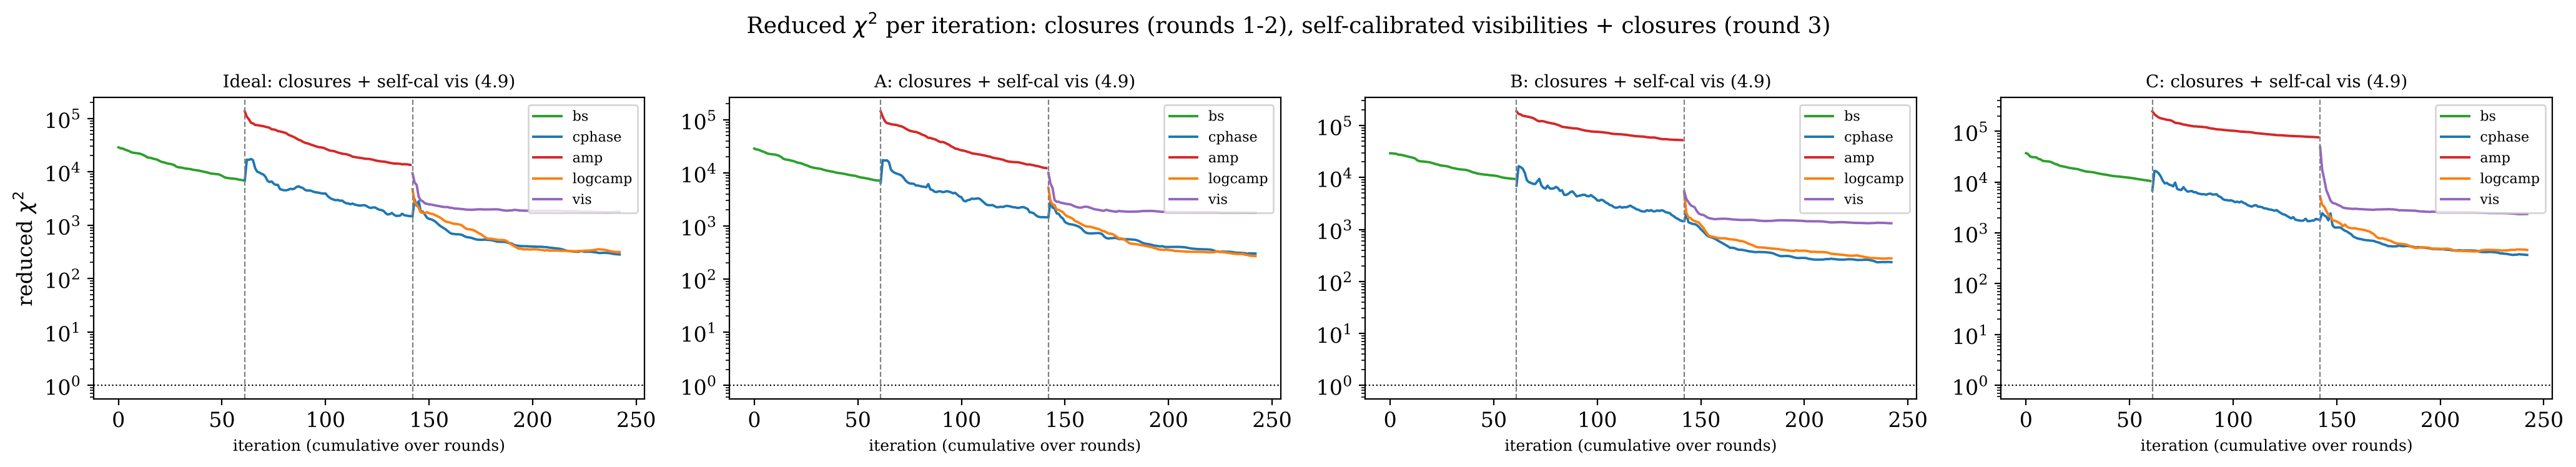

Building NX table


Building NX table


Building NX table


Building NX table


In [20]:
# Third pipeline: the raw data are self-calibrated to the round-2 image before round 3 ('selfcal': True)
selfcal_vis_rounds = [
    {'data_term': {'bs': 100},          'reg_term': {'simple': 10, 'flux': 1, 'cm': 50}, 'maxit': 60},
    {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 1,  'flux': 1, 'cm': 50}, 'maxit': 80,  'blur_frac': 1.0},
    # Round 3: self-calibrate the raw data to the round-2 image and COMBINE the calibrated visibilities
    # (weight 50) with the closure quantities, which self-calibration does not change.
    {'data_term': {'vis': 50, 'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 10, 'flux': 1, 'cm': 50}, 'maxit': 100, 'blur_frac': 0.5, 'selfcal': True},
]
sv_raw = {'Ideal': obs_jet_ideal, 'A': obs_jet_thA, 'B': obs_jet_err, 'C': obs_jet_errC}
sv_42  = {'Ideal': 'ideal', 'A': 'thA', 'B': 'err_closure', 'C': 'errC_closure'}
sv_vis = {'B': 'err_vis', 'C': 'errC_vis'}

rec_sv, hist_sv, snap_sv, cal_sv = {}, {}, {}, {}
for s_, o_ in sv_raw.items():
    print(f"\n--- {s_}: closures + self-calibrated visibilities ---")
    hist_sv[s_], snap_sv[s_], store = [], [], []
    rec_sv[s_] = run_rml_imager(o_, gaussprior, zbl, selfcal_vis_rounds, ttype='fast', verbose=True,
                                history=hist_sv[s_], snapshots=snap_sv[s_], cal_store=store)
    cal_sv[s_] = store[-1]

# Make the new reconstructions part of the global analysis of Section 5
for s_, k42 in sv_42.items():
    key = f'{k42}_sv'
    labels[key] = ('Ideal' if s_ == 'Ideal' else f'Scenario {s_}') + ' (closures + self-cal vis, 4.9)'
    aligned[key] = align_to_model(rec_sv[s_].blur_circ(res_jet), im_ref)

# ---- Comparison table
nr_ = lambda im: nrmse(align_to_model(im.blur_circ(res_jet), im_ref), im_ref)
print(f"\n{'':6s} {'closures pipeline (4.2)':>24s} {'closures only (4.8)':>20s} {'raw vis. (4.2)':>15s} {'closures + self-cal vis (4.9)':>30s}")
sv_rows = []
for s_ in sv_raw:
    v42, vcl = nr_(rec_raw[sv_42[s_]]), (nr_(rec_cl[s_]) if s_ in rec_cl else np.nan)
    vvis = nr_(rec_raw[sv_vis[s_]]) if s_ in sv_vis else np.nan
    vsv, im = nr_(rec_sv[s_]), rec_sv[s_]
    row = (s_, v42, vcl, vvis, vsv, im.total_flux(), chi2(im, sv_raw[s_], 'cphase'), chi2(im, sv_raw[s_], 'logcamp'),
           chi2(im, cal_sv[s_], 'vis'), nr_(snap_sv[s_][1]))
    sv_rows.append(row)
    f_ = lambda x: '—' if np.isnan(x) else f'{x:.3f}'
    print(f"{s_:6s} {f_(v42):>24s} {f_(vcl):>20s} {f_(vvis):>15s} {f_(vsv):>30s}")
print("(NRMSE against the reference image, lower is better)\n")
print(f"{'':6s} {'flux [Jy]':>10s} {'chi2 cphase':>12s} {'chi2 logcamp':>13s} {'chi2 vis':>10s} {'NRMSE round 2':>14s}   (4.9 pipeline)")
for r in sv_rows:
    print(f"{r[0]:6s} {r[5]:10.3f} {r[6]:12.2f} {r[7]:13.2f} {r[8]:10.2f} {r[9]:14.3f}")
print("(cphase and logcamp on the raw data; vis on the data self-calibrated to the round-2 image)")

# ---- Figure: the four approaches side by side
cols = ['closures pipeline (4.2)', 'closures only (4.8)', 'raw visibilities (4.2)', 'closures + self-cal vis (4.9)']
fig, axes = plt.subplots(4, 4, figsize=(16, 16.5))
for r_, s_ in enumerate(sv_raw):
    ims = [rec_raw[sv_42[s_]], rec_cl.get(s_), rec_raw[sv_vis[s_]] if s_ in sv_vis else None, rec_sv[s_]]
    for c_, (ttl, im) in enumerate(zip(cols, ims)):
        ax = axes[r_, c_]; ax.axis('off')
        if im is None:
            ax.text(0.5, 0.5, 'not run for this dataset', ha='center', va='center', fontsize=10, color='gray', transform=ax.transAxes)
            ax.set_title(f"{s_}: {ttl}", fontsize=9); continue
        al = align_to_model(im.blur_circ(res_jet), im_ref)
        ax.imshow(al.imvec.reshape(al.ydim, al.xdim), cmap='afmhot')
        ax.set_title(f"{s_}: {ttl}\nNRMSE = {nrmse(al, im_ref):.3f}, flux = {im.total_flux():.2f} Jy", fontsize=9)
fig.suptitle('Closures, raw visibilities and closures + self-calibrated visibilities (EVN + AVN + SKA-Mid)', fontsize=13)
plt.tight_layout(); save_fig(fig, '07f_pipelines_closures_rawvis_selfcalvis'); plt.show()

# ---- Figure: chi^2 at every iteration of the three rounds
plot_chi2_histories(hist_sv, {s_: f'{s_}: closures + self-cal vis (4.9)' for s_ in sv_raw},
                    '07g_chi2_convergence_selfcalvis_pipeline',
                    'Reduced $\\chi^2$ per iteration: closures (rounds 1-2), self-calibrated visibilities + closures (round 3)',
                    ncols=4)

# ---- Save the self-calibrated data, the images and the table (also included in the export of Section 7)
for sub_ in ('visibilities', 'images', 'tables'):
    os.makedirs(f'{OUT_DIR}/{sub_}', exist_ok=True)
for s_ in sv_raw:
    tag = 'ideal' if s_ == 'Ideal' else f'scenario{s_}'
    cal_sv[s_].save_uvfits(f'{OUT_DIR}/visibilities/jet_{tag}_selfcal_to_round2_image.uvfits')
    rec_sv[s_].save_fits(f'{OUT_DIR}/images/jet_reconstruction_{tag}_closures_selfcalvis.fits')
with open(f'{OUT_DIR}/tables/pipeline_closures_selfcal_vis.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['dataset', 'nrmse_closures_pipeline_4.2', 'nrmse_closures_only_4.8', 'nrmse_raw_vis_4.2',
                'nrmse_closures_selfcalvis_4.9', 'total_flux_4.9_Jy', 'chi2_cphase_raw', 'chi2_logcamp_raw',
                'chi2_vis_selfcal', 'nrmse_round2_image'])
    w.writerows(sv_rows)


#### 4.9.1 How much weight should the self-calibrated visibilities get?

To isolate the effect of the weight given to the visibilities, we repeat **only round 3** of the 4.9 pipeline for Scenarios A, B and C, starting from the **same round-2 image** and using the **same self-calibrated data**, and change only the data terms:

| Round-3 variant | Data terms (weights) | What it trusts |
|---|---|---|
| closures only | `cphase` 100 + `logcamp` 50 | only the gain-invariant closures |
| 4.9 pipeline | `vis` 50 + `cphase` 100 + `logcamp` 50 | closures and calibrated visibilities (already run above) |
| visibility-heavy | `vis` 500 + `cphase` 100 + `logcamp` 50 | mostly the calibrated visibilities |
| visibilities only | `vis` 100 | only the calibrated visibilities |

Everything else (`tv` 10, `flux` 1, `cm` 50, 100 iterations, start blurred by 0.5 × the resolution) is the same.

**What to look for.** The self-calibrated visibilities agree with the round-2 image by construction, so the more weight they get, the more round 3 stays close to that image, errors included: the `vis` χ² can look good while the closure χ² (computed on the raw data, which self-calibration cannot bias) and the NRMSE get worse. Expect ~5 minutes for this cell.


Scenario A: round 3 with closures only {'cphase': 100, 'logcamp': 50}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Scenario A: round 3 with visibility-heavy {'vis': 500, 'cphase': 100, 'logcamp': 50}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Scenario A: round 3 with visibilities only {'vis': 100}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Scenario B: round 3 with closures only {'cphase': 100, 'logcamp': 50}...
Initializing imager data products . . .


Scenario B: round 3 with visibility-heavy {'vis': 500, 'cphase': 100, 'logcamp': 50}...
Initializing imager data products . . .


Scenario B: round 3 with visibilities only {'vis': 100}...
Initializing imager data products . . .


Scenario C: round 3 with closures only {'cphase': 100, 'logcamp': 50}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Scenario C: round 3 with visibility-heavy {'vis': 500, 'cphase': 100, 'logcamp': 50}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Scenario C: round 3 with visibilities only {'vis': 100}...
Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .



Sc.  round-3 variant        NRMSE  flux[Jy]  chi2 cphase  chi2 logcamp   chi2 vis
A    closures only          0.375     1.482       148.46        185.98  275584.31
A    4.9 pipeline           0.338     1.052       302.49        271.52    1775.70
A    visibility-heavy       0.341     1.045       526.01        504.04    1287.74
A    visibilities only      0.344     1.044       721.93        685.60    1251.20
B    closures only          0.522     1.383        70.71        118.67  282360.97
B    4.9 pipeline           0.493     0.978       235.23        277.53    1315.52
B    visibility-heavy       0.514     0.972       475.95        528.58     929.82
B    visibilities only      0.518     0.971       582.88        678.19     927.01
C    closures only          0.339     1.374       153.69        187.02  584513.30
C    4.9 pipeline           0.432     0.854       368.29        460.55    2354.07
C    visibility-heavy       0.444     0.846       804.84        822.17    1653.28
C    visibiliti

NRMSE of the round-2 image (the self-calibration model): A 0.382, B 0.444, C 0.460


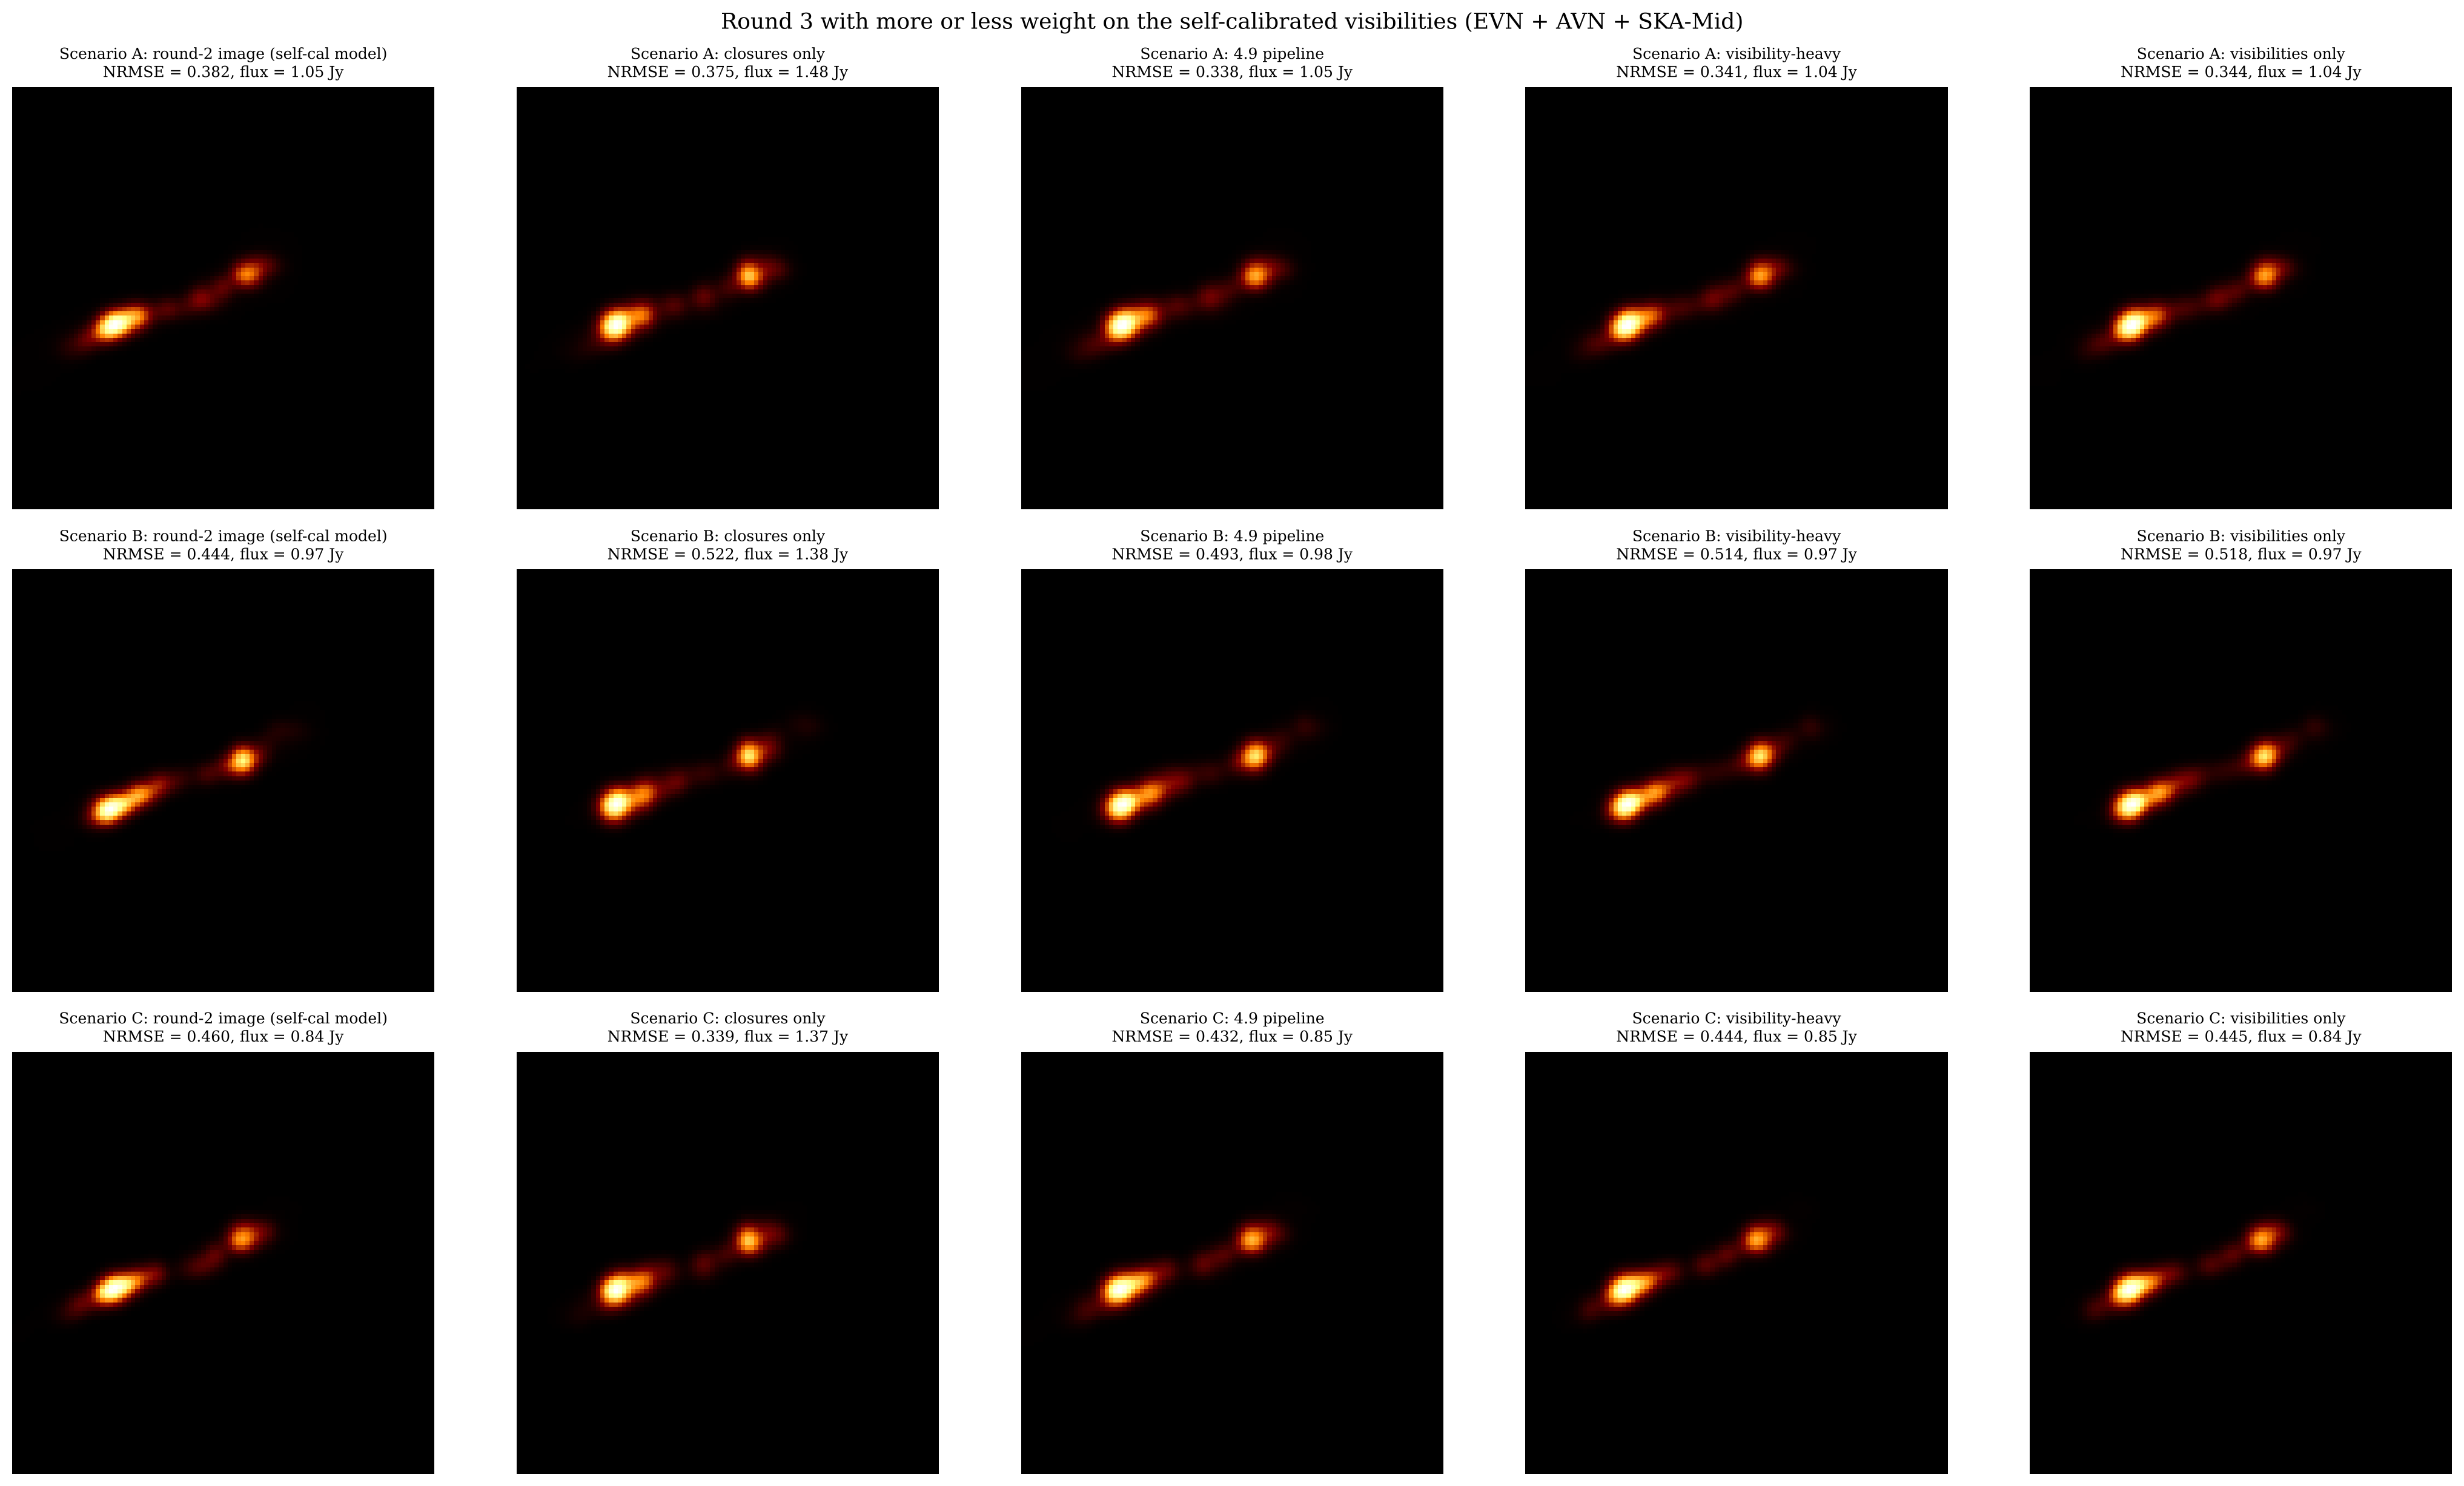

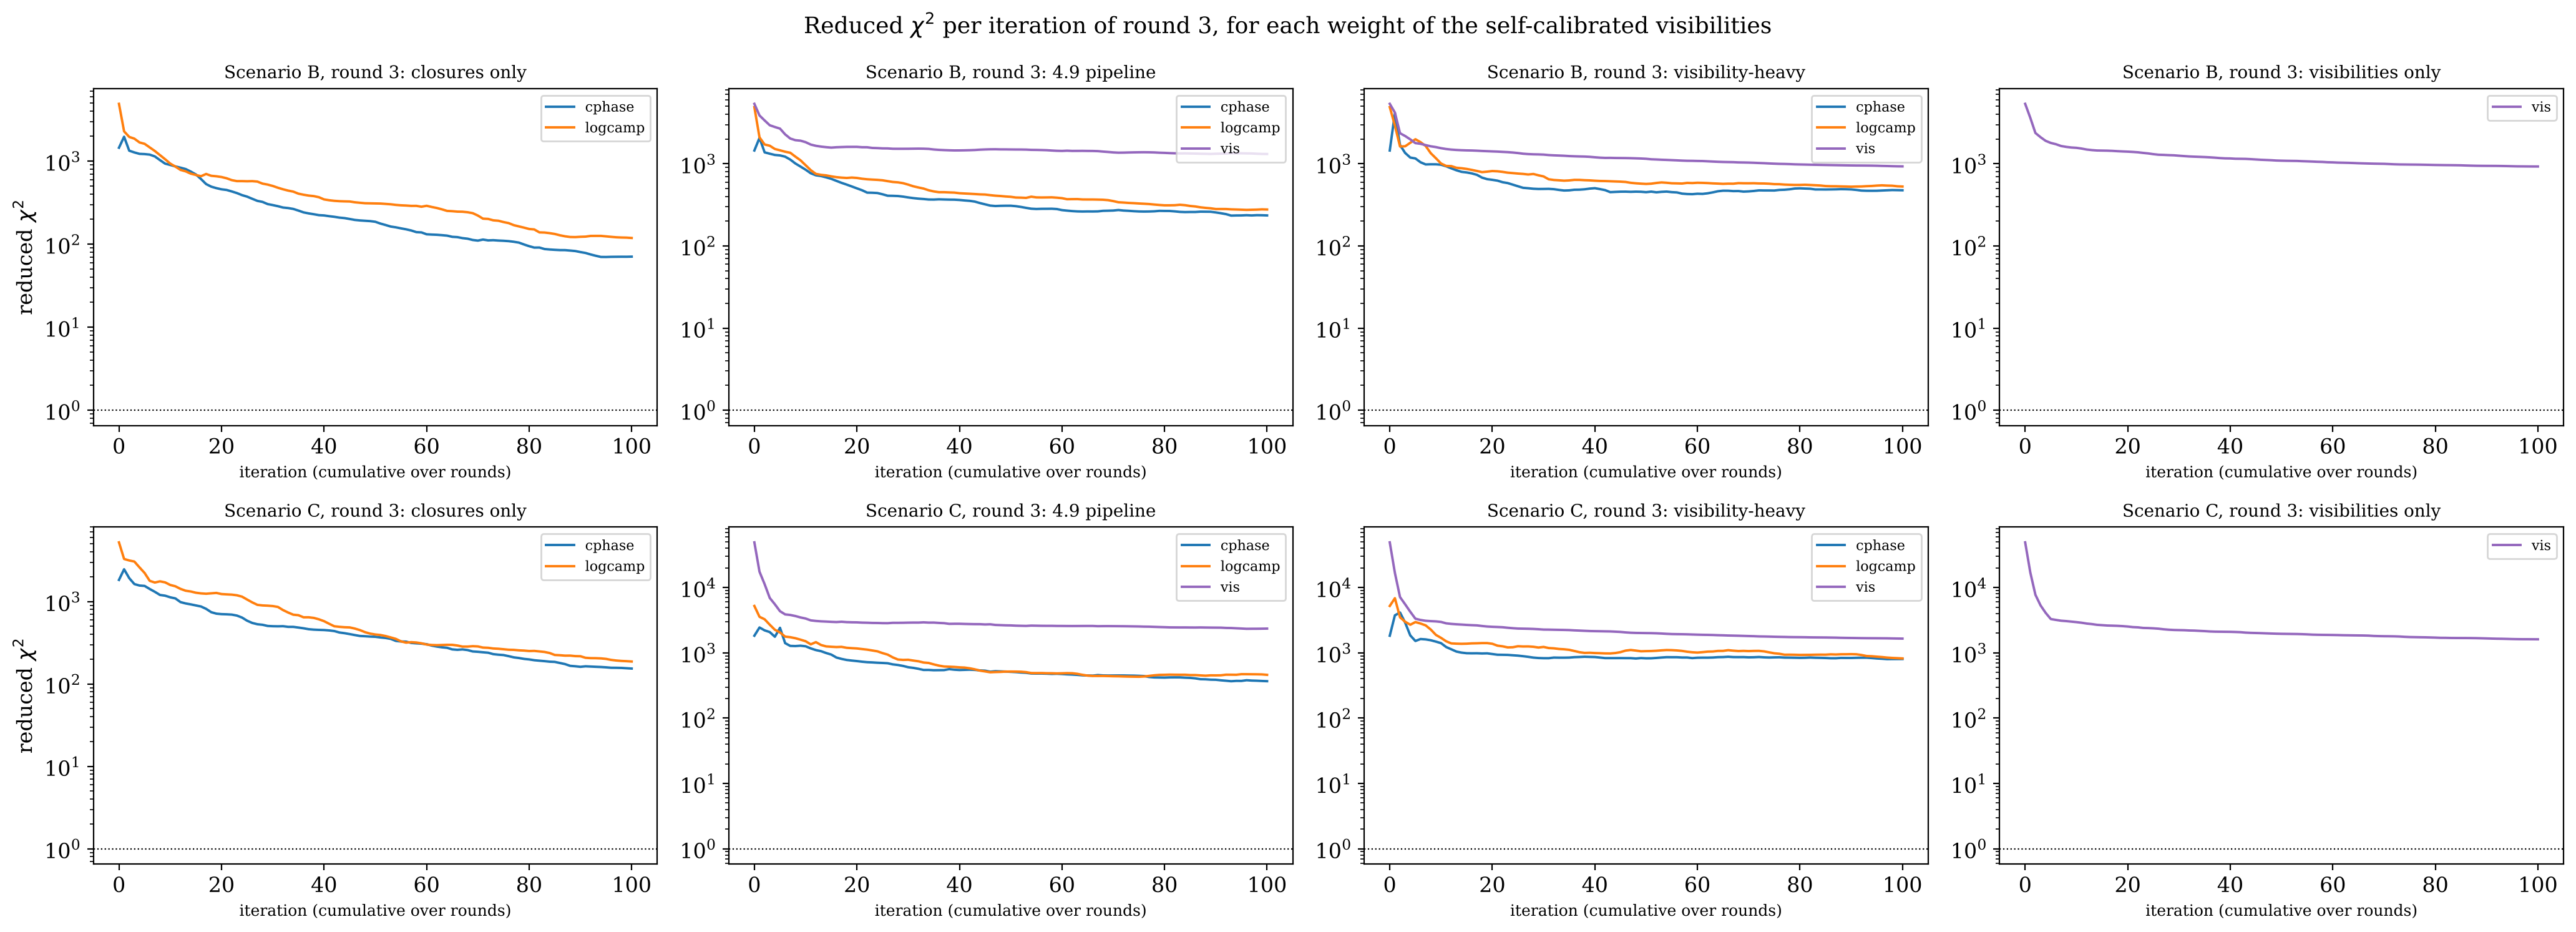

In [21]:
r3 = {k: v for k, v in selfcal_vis_rounds[2].items() if k != 'selfcal'}
weight_variants = {
    'closures only':     {'cphase': 100, 'logcamp': 50},
    '4.9 pipeline':      None,                                   # vis 50 + cphase 100 + logcamp 50, already run
    'visibility-heavy':  {'vis': 500, 'cphase': 100, 'logcamp': 50},
    'visibilities only': {'vis': 100},
}
rec_wt, hist_wt, wt_rows = {}, {}, []
for s_ in 'ABC':
    im2, cal_ = snap_sv[s_][1], cal_sv[s_]              # round-2 image and the data self-calibrated to it
    for vname, dterm in weight_variants.items():
        if dterm is None:
            rec_wt[(s_, vname)] = rec_sv[s_]
            hist_wt[(s_, vname)] = [dict(x, round=0) for x in hist_sv[s_] if x['round'] == 2]
        else:
            print(f"Scenario {s_}: round 3 with {vname} {dterm}...")
            h = []
            rec_wt[(s_, vname)] = run_rml_imager(cal_, im2, zbl, [dict(r3, data_term=dterm)], ttype='fast', history=h)
            hist_wt[(s_, vname)] = h
        im = rec_wt[(s_, vname)]
        wt_rows.append((s_, vname, nr_(im), im.total_flux(),
                        chi2(im, sv_raw[s_], 'cphase'), chi2(im, sv_raw[s_], 'logcamp'), chi2(im, cal_, 'vis')))

print(f"\n{'Sc.':4s} {'round-3 variant':20s} {'NRMSE':>7s} {'flux[Jy]':>9s} {'chi2 cphase':>12s} {'chi2 logcamp':>13s} {'chi2 vis':>10s}")
for s_, vname, nr, fl, cp, lc, vi in wt_rows:
    print(f"{s_:4s} {vname:20s} {nr:7.3f} {fl:9.3f} {cp:12.2f} {lc:13.2f} {vi:10.2f}")
print("(cphase and logcamp on the raw data; vis on the data self-calibrated to the round-2 image)")
print("NRMSE of the round-2 image (the self-calibration model): " + ", ".join(f"{s_} {nr_(snap_sv[s_][1]):.3f}" for s_ in 'ABC'))

# ---- Figure: round-2 image and the four round-3 variants, per scenario
fig, axes = plt.subplots(3, 5, figsize=(21, 12.5))
for r_, s_ in enumerate('ABC'):
    panels = [('round-2 image (self-cal model)', snap_sv[s_][1])] + [(v, rec_wt[(s_, v)]) for v in weight_variants]
    for c_, (ttl, im) in enumerate(panels):
        al = align_to_model(im.blur_circ(res_jet), im_ref)
        axes[r_, c_].imshow(al.imvec.reshape(al.ydim, al.xdim), cmap='afmhot'); axes[r_, c_].axis('off')
        axes[r_, c_].set_title(f"Scenario {s_}: {ttl}\nNRMSE = {nrmse(al, im_ref):.3f}, flux = {im.total_flux():.2f} Jy", fontsize=9)
fig.suptitle('Round 3 with more or less weight on the self-calibrated visibilities (EVN + AVN + SKA-Mid)', fontsize=13)
plt.tight_layout(); save_fig(fig, '07h_round3_visibility_weight_test'); plt.show()

# ---- Figure: chi^2 at every iteration of round 3, per variant (Scenarios B and C)
plot_chi2_histories({f'{s_}|{v}': hist_wt[(s_, v)] for s_ in 'BC' for v in weight_variants},
                    {f'{s_}|{v}': f'Scenario {s_}, round 3: {v}' for s_ in 'BC' for v in weight_variants},
                    '07i_chi2_convergence_visibility_weight_test',
                    'Reduced $\\chi^2$ per iteration of round 3, for each weight of the self-calibrated visibilities',
                    ncols=4)

for (s_, vname), im in rec_wt.items():
    im.save_fits(f"{OUT_DIR}/images/jet_scenario{s_}_round3_{vname.replace(' ', '_').replace('.', '')}.fits")
with open(f'{OUT_DIR}/tables/round3_visibility_weight_test.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['scenario', 'round3_variant', 'nrmse', 'total_flux_Jy', 'chi2_cphase_raw', 'chi2_logcamp_raw', 'chi2_vis_selfcal'])
    w.writerows(wt_rows)


## 5. Analysis of results: global scientific quality (metrics and plots)

In VLBI imaging, visual inspection can be subjective. Is a smooth jet better than a sharp one? To answer this rigorously, we evaluate every reconstruction against the reference image (the true jet blurred to the array resolution, Section 4.2) with complementary metrics:

1. **NRMSE** (Normalized Root Mean Square Error, Section 4.1): pixel-by-pixel intensity differences after normalising both images to unit flux. **Lower is better** (0 = perfect).
2. **NXCORR** (Normalized Cross-Correlation): structural similarity, ignoring the absolute brightness scale. **Higher is better** (1 = perfect).
3. **Total flux** of the reconstruction (true value 1 Jy): closure quantities do not constrain it, so it tells us whether the flux regularizer and the amplitudes did their job.
4. **Core flux and core offset:** the flux within one resolution element of the image peak (the core), relative to the same quantity in the reference, and the distance between the core and the flux centroid of the image compared with the reference. They test whether the core–jet geometry is right, independently of the absolute position, which closure imaging does not fix.
5. **Dynamic range:** image peak over the rms of the image in the region where the reference has no emission (below 1% of its peak).

The table includes the three pipelines: closures (Section 4.2), raw visibilities (Section 4.2) and closures + self-calibrated visibilities (Section 4.9). We then plot these metrics per scenario and on a **Pareto front** (error vs. fidelity), and check the closure phases of each scenario directly in the data.

reconstruction                                    NRMSE  NXCORR  flux[Jy]  core/ref  core off.[mas]  dyn.range
Ideal (closures + hybrid)                         0.363   0.932     1.008      1.02            0.22        628
Scenario A (thermal only, closures + hybrid)      0.427   0.907     1.008      1.03            0.29        538
Scenario B (closures + hybrid self-cal)           0.339   0.942     1.001      1.00            0.17        639
Scenario B (raw visibilities)                     1.590  -0.024     0.025      0.03            3.57         19
Scenario C (closures + hybrid self-cal)           0.374   0.929     1.000      1.02            0.23        541
Scenario C (raw visibilities)                     0.937   0.521     0.097      0.07            5.38         18
Ideal (closures + self-cal vis, 4.9)              0.319   0.947     1.027      0.93            0.52        209
Scenario A (closures + self-cal vis, 4.9)         0.338   0.940     1.031      0.97            0.94        190
S

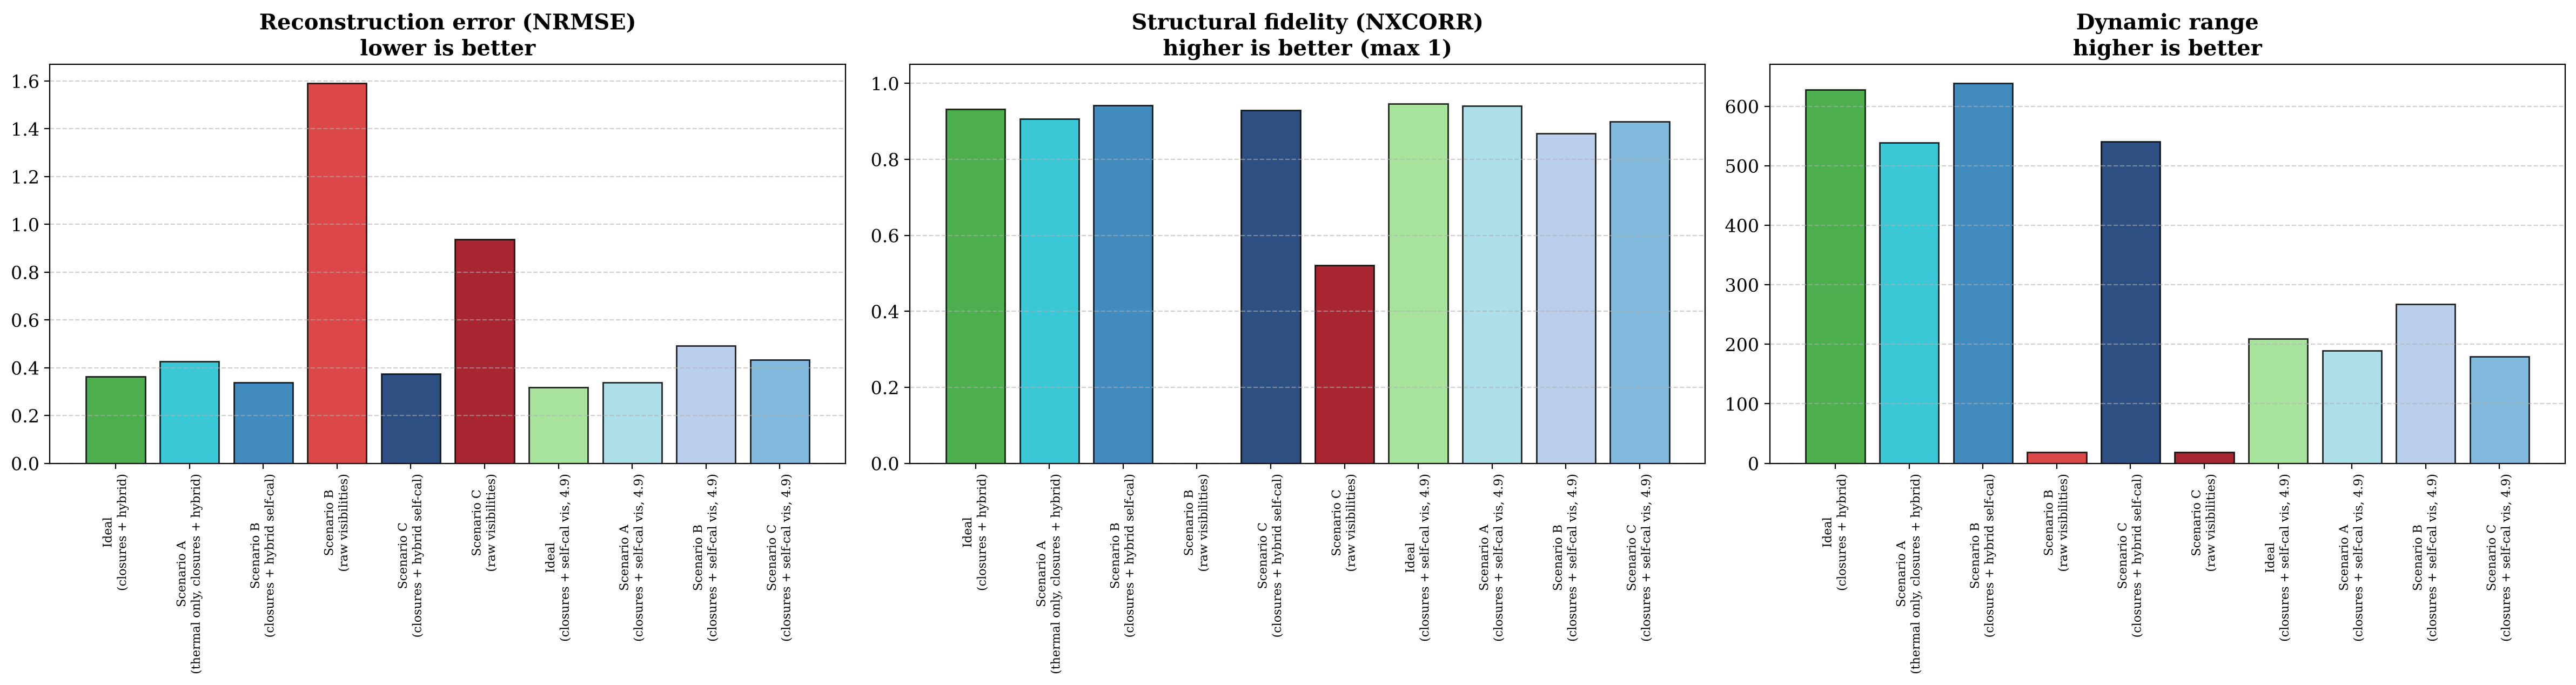

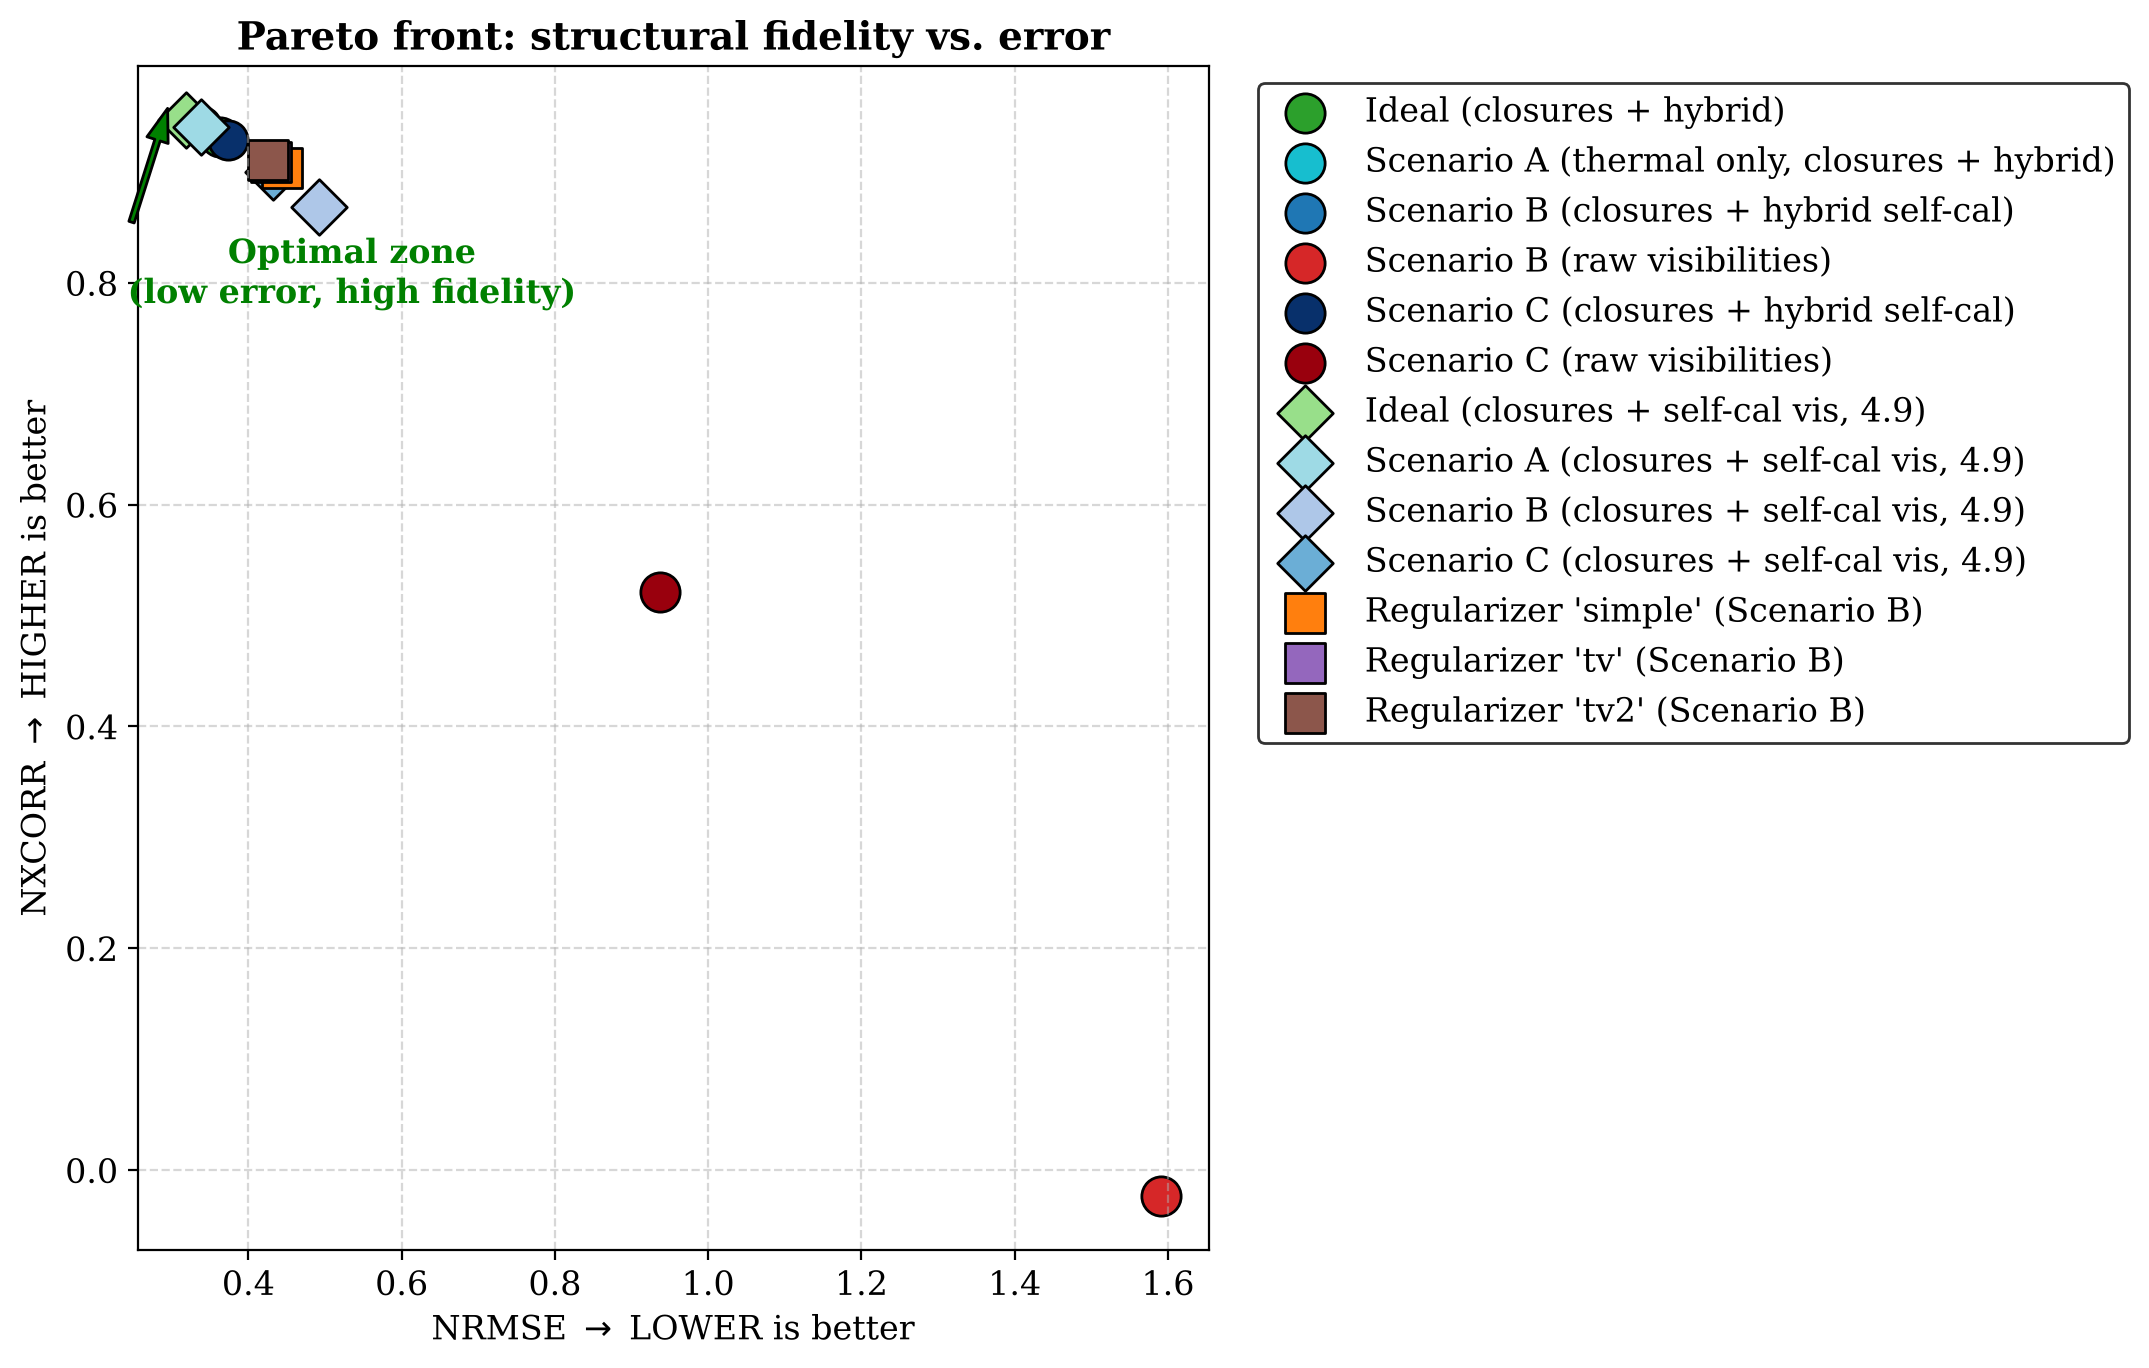

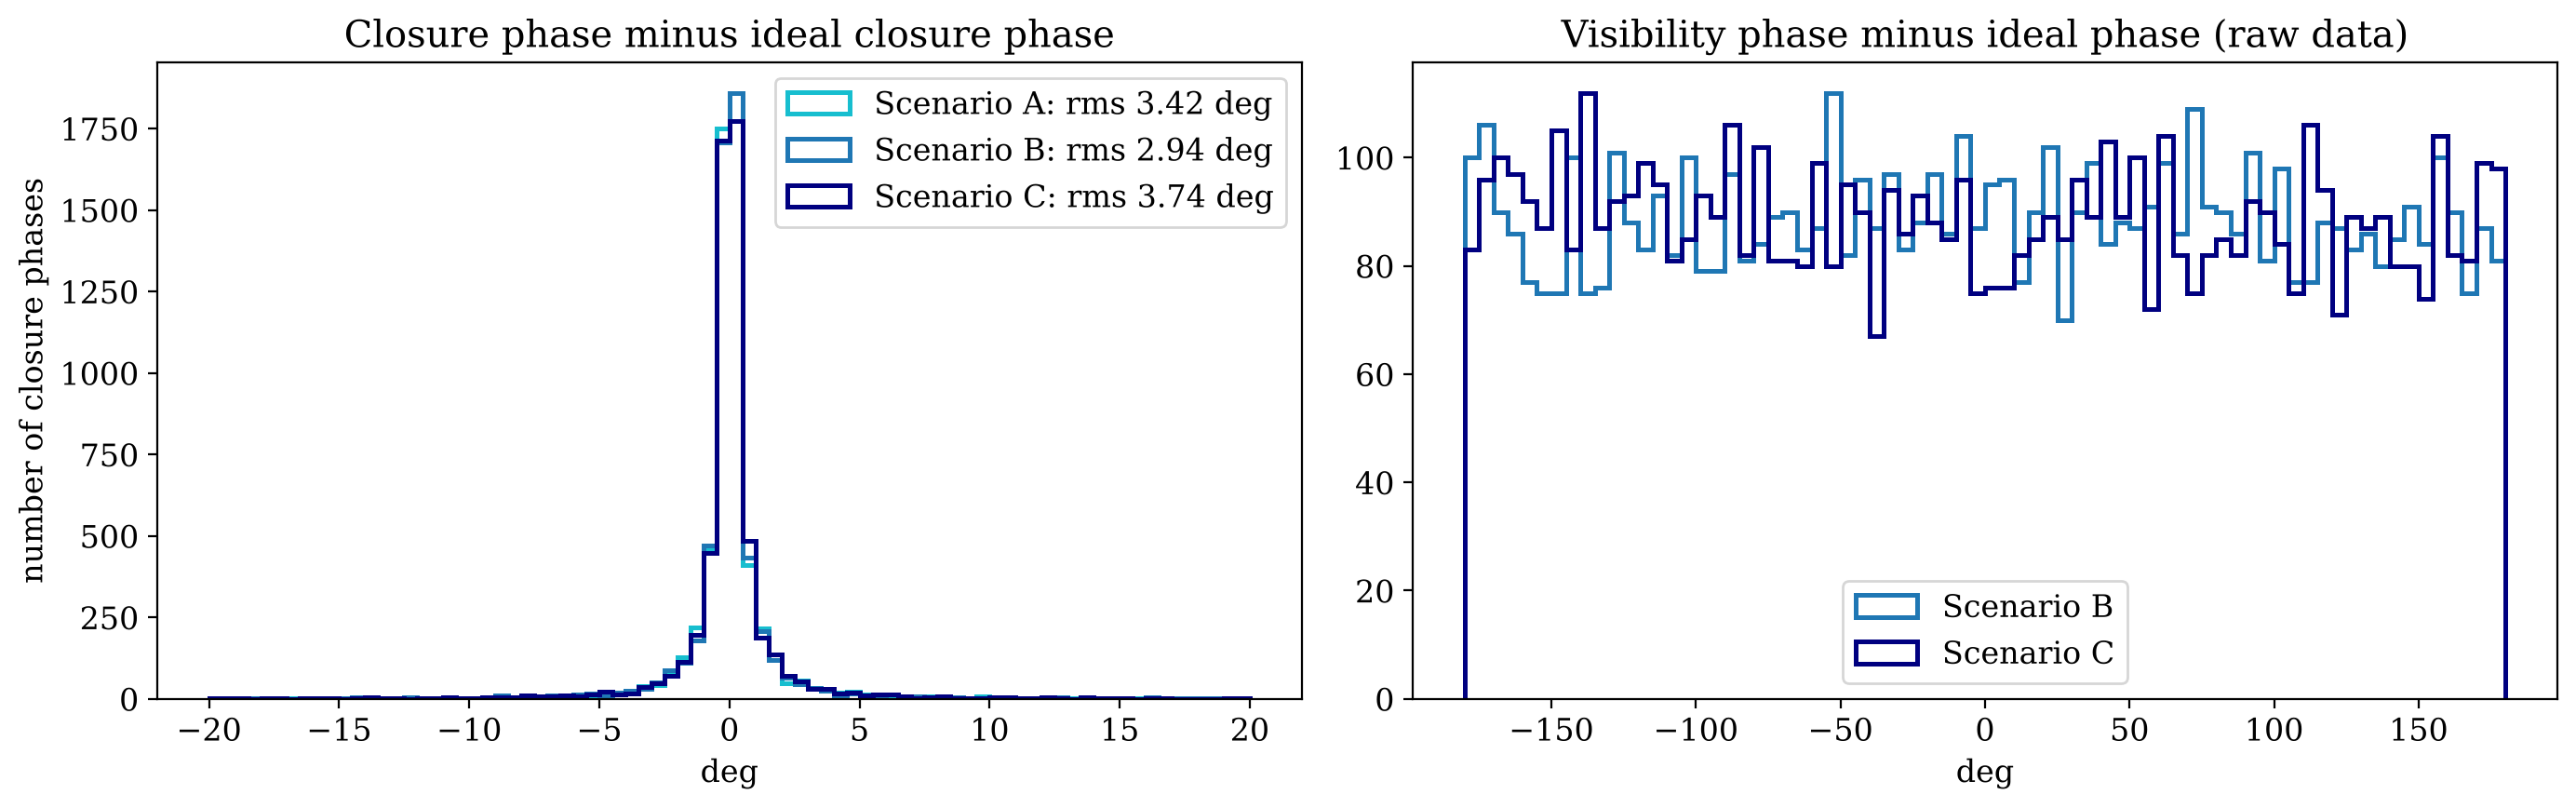

Left: the closure phases of A, B and C scatter around the ideal ones by the same small amount (thermal noise only):
the gain and phase errors of B and C cancel exactly in every triangle. Right: the raw visibility phases of B and C
are scrambled over the whole circle, which is why imaging the raw visibilities fails.


In [22]:
# =============================================================================
# GLOBAL SYNTHESIS: METRICS TABLE, BAR CHARTS, PARETO FRONT, CLOSURE-PHASE CHECK
# =============================================================================
def calc_nxcorr(img, ref):
    """Normalized cross-correlation of the mean-subtracted images. HIGHER is better (1.0 = perfect)."""
    a = img.imvec - img.imvec.mean(); b = ref.imvec - ref.imvec.mean()
    return float(np.sum(a * b) / np.sqrt(np.sum(a**2) * np.sum(b**2)))

ref_arr = im_ref.imvec.reshape(im_ref.ydim, im_ref.xdim)
yy, xx = np.indices(ref_arr.shape)

def core_and_centroid(arr):
    p = np.array(np.unravel_index(np.argmax(arr), arr.shape)); w = np.clip(arr, 0, None)
    return p, np.array([(w * yy).sum() / w.sum(), (w * xx).sum() / w.sum()])

p_ref, c_ref = core_and_centroid(ref_arr)
core_r = res_jet / im_ref.psize                    # one resolution element, in pixels
core_flux_ref = ref_arr[np.hypot(yy - p_ref[0], xx - p_ref[1]) < core_r].sum()

def all_metrics(im_aligned):
    a = im_aligned.imvec.reshape(im_aligned.ydim, im_aligned.xdim)
    p, c = core_and_centroid(a)
    core_flux = a[np.hypot(yy - p[0], xx - p[1]) < core_r].sum() / core_flux_ref
    core_off = np.hypot(*((p - c) - (p_ref - c_ref))) * im_ref.psize / eh.RADPERUAS / 1000
    dyn = a.max() / a[ref_arr < 0.01 * ref_arr.max()].std()
    return dict(nrmse=nrmse(im_aligned, im_ref), nxcorr=calc_nxcorr(im_aligned, im_ref), flux=im_aligned.total_flux(),
                core_flux=core_flux, core_offset_mas=core_off, dyn_range=dyn)

metrics = {labels[k]: all_metrics(v) for k, v in aligned.items()}
metrics.update({f"Regularizer '{k}' (Scenario B)": all_metrics(v) for k, v in reg_results.items()})

print(f"{'reconstruction':48s} {'NRMSE':>6s} {'NXCORR':>7s} {'flux[Jy]':>9s} {'core/ref':>9s} {'core off.[mas]':>15s} {'dyn.range':>10s}")
for k, m in metrics.items():
    print(f"{k:48s} {m['nrmse']:6.3f} {m['nxcorr']:7.3f} {m['flux']:9.3f} {m['core_flux']:9.2f} {m['core_offset_mas']:15.2f} {m['dyn_range']:10.0f}")

# ---- Plot 1: data strategies per scenario
pipe_keys = ['ideal', 'thA', 'err_closure', 'err_vis', 'errC_closure', 'errC_vis',
             'ideal_sv', 'thA_sv', 'err_closure_sv', 'errC_closure_sv']        # *_sv: closures + self-cal vis (4.9)
pipe_names = [labels[k].replace(' (', '\n(') for k in pipe_keys]
colors_pipe = ['#2ca02c', '#17becf', '#1f77b4', '#d62728', '#08306b', '#99000d', '#98df8a', '#9edae5', '#aec7e8', '#6baed6']
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 6.5), facecolor='white')
for ax, key, title in ((ax1, 'nrmse', 'Reconstruction error (NRMSE)\nlower is better'),
                       (ax2, 'nxcorr', 'Structural fidelity (NXCORR)\nhigher is better (max 1)'),
                       (ax3, 'dyn_range', 'Dynamic range\nhigher is better')):
    ax.bar(pipe_names, [metrics[labels[k]][key] for k in pipe_keys], color=colors_pipe, edgecolor='black', alpha=0.85)
    ax.set_title(title, fontweight='bold'); ax.tick_params(axis='x', labelsize=8, rotation=90); ax.grid(axis='y', ls='--', alpha=0.6)
ax2.set_ylim(0, 1.05)
plt.tight_layout(); save_fig(fig, '08_metrics_per_scenario'); plt.show()

# ---- Plot 2: Pareto front (pipelines = circles, regularizers = squares)
fig, ax = plt.subplots(figsize=(11, 7), facecolor='white')
for k, col in zip(pipe_keys, colors_pipe):
    m = metrics[labels[k]]
    ax.scatter(m['nrmse'], m['nxcorr'], color=col, s=200, marker='D' if k.endswith('_sv') else 'o', edgecolor='black', label=labels[k])
for (k, img), col in zip(reg_results.items(), ['#ff7f0e', '#9467bd', '#8c564b']):
    m = metrics[f"Regularizer '{k}' (Scenario B)"]
    ax.scatter(m['nrmse'], m['nxcorr'], color=col, s=200, marker='s', edgecolor='black', label=f"Regularizer '{k}' (Scenario B)")
ax.set_title("Pareto front: structural fidelity vs. error", fontsize=14, fontweight='bold')
ax.set_xlabel("NRMSE $\\rightarrow$ LOWER is better"); ax.set_ylabel("NXCORR $\\rightarrow$ HIGHER is better")
ax.legend(bbox_to_anchor=(1.03, 1), loc='upper left', frameon=True, edgecolor='black'); ax.grid(True, ls='--', alpha=0.5)
ax.annotate('Optimal zone\n(low error, high fidelity)', xy=(0.03, 0.97), xycoords='axes fraction', xytext=(0.2, 0.8),
            textcoords='axes fraction', arrowprops=dict(facecolor='green', shrink=0.05, width=2, headwidth=8),
            fontsize=12, fontweight='bold', color='green', ha='center')
plt.tight_layout(); save_fig(fig, '09_pareto_fidelity_vs_error'); plt.show()

# ---- Plot 3: closure phases of each scenario vs. the ideal ones, triangle by triangle
def cphase_dict(obs):
    with contextlib.redirect_stdout(io.StringIO()):
        cp = obs.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
    return {(round(float(r['time']), 5), r['t1'], r['t2'], r['t3']): float(r['cphase']) for r in cp}
cp_ideal = cphase_dict(obs_jet_ideal)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, o_, col in (('A', obs_jet_thA, 'tab:cyan'), ('B', obs_jet_err, 'tab:blue'), ('C', obs_jet_errC, 'navy')):
    d = cphase_dict(o_); k_ = [k for k in d if k in cp_ideal]
    r = np.array([(d[k] - cp_ideal[k] + 180) % 360 - 180 for k in k_])
    ax[0].hist(r, bins=np.linspace(-20, 20, 81), histtype='step', lw=1.8, color=col, label=f"Scenario {name}: rms {np.sqrt(np.mean(r**2)):.2f} deg")
ax[0].set(title='Closure phase minus ideal closure phase', xlabel='deg', ylabel='number of closure phases'); ax[0].legend()
for name, o_, col in (('B', obs_jet_err, 'tab:blue'), ('C', obs_jet_errC, 'navy')):
    ph = np.angle(o_.data['vis'] / obs_jet_ideal.data['vis'], deg=True)
    ax[1].hist(ph, bins=np.linspace(-180, 180, 73), histtype='step', lw=1.8, color=col, label=f'Scenario {name}')
ax[1].set(title='Visibility phase minus ideal phase (raw data)', xlabel='deg'); ax[1].legend()
plt.tight_layout(); save_fig(fig, '10_closure_phase_vs_visibility_phase_errors'); plt.show()
print("Left: the closure phases of A, B and C scatter around the ideal ones by the same small amount (thermal noise only):")
print("the gain and phase errors of B and C cancel exactly in every triangle. Right: the raw visibility phases of B and C")
print("are scrambled over the whole circle, which is why imaging the raw visibilities fails.")

### 5.1 How to read these results

The numbers quoted below are those of the run saved in this notebook, made with the **EVN + AVN + SKA-Mid** array (20 stations, with the phased SKA-Mid core `S5`). The thermal noise, the gain errors and the phase errors are drawn at random, and RML imaging is a non-convex optimisation, so if you run it again your numbers will differ, typically by a few hundredths in NRMSE (up to ~0.07 between two runs of this notebook). The conclusions do not.

**1. Closure quantities protect the image; raw visibilities do not.** With the same corrupted data, the closures pipeline of Section 4.2 reconstructs Scenarios B and C with NRMSE 0.34 and 0.37 (NXCORR 0.94 and 0.93). It keeps the total flux at 1.00 Jy, the core flux within 2% and the core within 0.25 mas of its true position, with dynamic ranges of ~540–640. The raw-visibility reconstructions of the same datasets have NRMSE 1.6 and 0.9 and keep only 0.03 and 0.10 Jy of the 1 Jy. The uncorrected station phases scramble the visibility phases over the whole circle (right panel of the last figure), so no image can reproduce them.

**2. Ideal, A, B and C give statistically the same image with the closures pipeline.** Their NRMSE (0.34–0.43) differ by about the run-to-run variation: in this run A comes out worst and B best, which has no physical meaning. The closure phases of A, B and C scatter around the ideal ones by the same small amount (left panel of the last figure): that is only thermal noise, because the gain and phase errors cancel in every triangle.

**3. Scenario C behaves like B in this notebook.** The atmospheric corruptions of Section 3.5 (ionospheric dTEC + tropospheric delay) are a single phase per station and time, so they cancel in closure quantities exactly like the generic phase of Scenario B: the closure phases change by less than 10⁻¹² deg. They start to matter when the phase varies *within* the band or the scan, which is the Scenario C of the delivery version.

**4. Why the NRMSE is not close to zero: the χ² histories (Sections 4.6 and 4.7).** The closure χ² of the closures-pipeline images is ~26–50 and the amplitude χ² ~150–750, not 1. The iteration-by-iteration plot of Section 4.7 shows why: in every closure-based run the χ² is **still decreasing at the end of round 3**, so the reconstructions stop before convergence. With a median SNR of ~180, the data demand more detail than ~550 iterations from a smooth prior can deliver. The raw-visibility runs flatten at χ²<sub>vis</sub> ≈ 1.4 × 10⁶ within a few iterations: no image can fit scrambled phases.

**5. The fit statistics separate good and bad images objectively.** The closure-phase χ² of the raw-visibility images is ~59,000–61,000, about 1,400 (B) and 1,900 (C) times that of the closure images of the same scenario. An image can look plausible and still be grossly inconsistent with the gain-invariant data; the χ² catches it.

**6. Regularizers.** With the same Scenario B data and two imaging rounds, `simple`, `tv` and `tv2` give very similar NRMSE in this run (0.43–0.44, `tv2` marginally best) and keep ~95% of the flux. Their χ² histories (bottom row of the Section 4.7 figure) are still falling steeply after 162 iterations, which is the main reason all three are worse than the three-round pipeline. Compare regularizers only at convergence.

**7. How well do the closures work? (Section 4.8).** Self-calibrating the **raw** data to the images:

| | Phase error | Amplitude error | χ² vs. true visibilities |
|---|---|---|---|
| raw data (B, C) | ~90° | 11–12% | ~3.0–3.5 × 10⁶ |
| self-cal to the **closures-only** image | **1.0–1.9°** | 14–15% | ~2.1–2.6 × 10⁴ |
| self-cal to the final **4.2 pipeline** image | 1.4–3.3° | 6–9% | ~4 × 10³ – 1 × 10⁴ |
| oracle (true jet) | 0.2° | 0.5% | ~9 |

* **The closures alone fix the phases very well:** self-calibration to the closures-only image brings the phase errors from 90° to 1–2°, as good as the final image of the 4.2 pipeline. The closure phases encode the position of every component of the jet.
* **They fix the amplitudes less well:** the closures-only images (NRMSE 0.40–0.45) misplace part of the extended flux, and amplitude self-calibration copies that into the data (14–15% amplitude errors).
* **Re-imaging the self-calibrated visibilities** gives NRMSE 0.39–0.41, about the same as the model the data were calibrated to: one self-calibration step cannot add information the model does not have.
* Even the oracle stays at χ² ≈ 9 rather than 1: it was computed with the fast FFT on the model grid, whose small interpolation error is visible at an SNR of ~180.

**8. The third pipeline: closures + self-calibrated visibilities (Section 4.9).** Self-calibrating the raw data to the round-2 image and giving the calibrated visibilities weight 50 in round 3 (with `flux` 1 and 60 + 80 + 100 iterations):

| | closures pipeline (4.2) | closures only (4.8) | raw visibilities (4.2) | closures + self-cal vis (4.9) |
|---|---|---|---|---|
| Ideal | 0.36 | — | — | 0.32 |
| A | 0.43 | 0.40 | — | 0.34 |
| B | 0.34 | 0.43 | 1.59 | **0.49** |
| C | 0.37 | 0.45 | 0.94 | **0.43** |

(NRMSE, lower is better.)

* **With gain errors (B and C) it is clearly worse than the closures pipeline:** NRMSE 0.49 and 0.43 against 0.34 and 0.37, core flux at 87% and 79% of the reference, a total flux of only 0.83 Jy in C, and a dynamic range of ~180–270 instead of ~540–640.
* **Its images do not agree with the closures:** the closure-phase χ² on the raw data is 235–370, 6–11 times that of the closures pipeline (32–50), in every dataset. The visibilities pull the image towards something the gain-invariant data do not support.
* **Why:** the data were self-calibrated to the round-2 image (NRMSE 0.38–0.48), so they agree with that image, errors included. The `vis` term rewards staying close to it.
* For Ideal and A, which have no gain errors to solve, its NRMSE (0.32, 0.34) is lower than that of the 4.2 pipeline in this run, but its closure χ² is still 6–7 times higher and its dynamic range a third. A low NRMSE alone does not make an image consistent with the data.

**9. How much weight should the visibilities get? (Section 4.9.1).** Repeating only round 3, from the same round-2 image and the same self-calibrated data:

| Round-3 variant | closure-phase χ² (A / B / C) | `vis` χ² (A / B / C) | NRMSE (A / B / C) | flux [Jy] |
|---|---|---|---|---|
| closures only | **148 / 71 / 154** | 2.8 × 10⁵ / 2.8 × 10⁵ / 5.8 × 10⁵ | 0.37 / 0.52 / **0.34** | 1.37–1.48 |
| 4.9 pipeline (`vis` 50) | 302 / 235 / 368 | 1776 / 1316 / 2354 | 0.34 / 0.49 / 0.43 | 0.85–1.05 |
| visibility-heavy (`vis` 500) | 526 / 476 / 805 | 1288 / 930 / 1653 | 0.34 / 0.51 / 0.44 | 0.85–1.05 |
| visibilities only | 722 / 583 / 1026 | 1251 / 927 / 1614 | 0.34 / 0.52 / 0.44 | 0.84–1.04 |

* **The more weight the self-calibrated visibilities get, the worse the image fits the closures:** the closure-phase χ² grows by a factor 5–8 from "closures only" to "visibilities only", while raising the `vis` weight from 50 to 500 or more improves the `vis` χ² by less than a factor 1.5. The image is being fitted to the calibration model, not to the sky.
* In C the closures-only round gives the best image (NRMSE 0.34 against 0.43–0.44). In A and B the differences in NRMSE are small (≤ 0.04), and the closures-only round has its own problem: without amplitudes and with a weak flux constraint, its total flux drifts to 1.4–1.5 Jy.
* **Lesson:** use the closures to drive the structure, keep the weight of the self-calibrated visibilities low until the self-calibration model is good, and bring in the amplitudes (or a strong flux constraint) only to fix the total flux. With real data, iterate self-calibration and imaging (phase-only first, amplitudes later), which is what the delivery version of this notebook does inside its pipeline (NRMSE ~0.1).

**10. What this means for a proposal.** For a 1 Jy jet at 5 GHz, EVN + AVN + SKA-Mid data with realistic gain and phase errors can be imaged to the same fidelity as perfectly calibrated data, *provided* the imaging relies on closure quantities and the self-calibration model is good before the visibilities are trusted. The limit is set by the uv-coverage and by the imaging itself, not by the antenna-based calibration errors.


## 6. From this notebook to a real observation proposal

Everything you've just done is, in miniature, exactly the kind of feasibility study that goes into a real VLBI observing proposal (e.g. for the EVN, the AVN, or a joint EVN + AVN + SKA-Mid session). When you propose an observation, a Time Allocation Committee typically wants to see:

- **Expected uv-coverage** for your source's declination and your requested time range, which is exactly the plot from Section 2.3. A proposal with poor, lopsided uv-coverage is much harder to justify, because the panel can immediately see you won't be able to reconstruct the source structure you're claiming to study.
- **Expected sensitivity / achievable image fidelity**, captured by the ideal-vs-corrupted-vs-self-calibrated comparison in Section 3.3 and by the metrics of Section 5, which give you a feel for it given your assumed SEFDs, bandwidth, and integration time.
- **Expected angular resolution**, given directly by `obs.fit_beam()` (Section 4.4): the major/minor FWHM and position angle of the clean beam tell you the finest structure you could realistically hope to resolve with the array and frequency you're requesting.
- **A simulated image** showing what your science target would look like if observed as proposed, this is precisely the reconstructed image from Section 4.3, often the most convincing single figure in a proposal.

In other words: if you swap `im_jet` for a model of *your* actual science target (a different jet, an AGN core, a maser, whatever your proposal is about) and rerun Sections 2–4 with the array, frequency, and observing window you intend to request, you get a complete, quantitative feasibility study for free.


## 7. Export: UVFITS visibilities, FITS images, figures and tables

Whether for a proposal, a paper, or just to keep working outside this notebook, the cell below collects everything in one folder (`results_jet_5GHz_class/`) and one zip file:

* `visibilities/`: the ideal observation and the datasets of Scenarios A, B and C, the B and C data self-calibrated to the true jet (Section 3) and the data self-calibrated to the round-2 images (Section 4.9), each as `.uvfits` (the standard format of AIPS, CASA and Difmap) and `.txt`;
* `images/`: the jet model, the reference image and every reconstruction, as `.fits` (and the main one also as `.txt`, the `ehtim` format you can reload with `eh.image.load_txt()`);
* `figures/`: every figure of the notebook as `.png`;
* `tables/`: the metrics of Section 5, the $\chi^2$ table of Section 4.6, the imaging rounds and a feasibility summary (`proposal_summary.txt`).

In Google Colab the zip file is downloaded automatically.

> **Syntax note for 1.2.10:** `Image.save_fits()`, `Image.save_txt()`, `Obsdata.save_uvfits()`, and `Obsdata.save_txt()` all take only a file path, with no other required arguments (confirmed against their real signatures).

In [23]:
import shutil, csv, datetime

def _try(label, fn):
    try: fn()
    except Exception as e: print(f"  [skipped] {label}: {e}")

# --- Visibility data: UVFITS (for AIPS/CASA/Difmap) and plain text
obs_set = {'reference_ideal': obs_jet_ideal, 'scenarioA_thermal': obs_jet_thA, 'scenarioB_corrupted': obs_jet_err,
           'scenarioB_selfcal': cal_jet, 'scenarioC_corrupted': obs_jet_errC, 'scenarioC_selfcal': cal_jet_errC}
for name, o in obs_set.items():
    _try(name, lambda: o.save_uvfits(f'{OUT_DIR}/visibilities/jet_{name}.uvfits'))
    _try(name, lambda: o.save_txt(f'{OUT_DIR}/visibilities/jet_{name}.txt'))

# --- Images: FITS (for AIPS/CASA/DS9/papers)
_try('model', lambda: im_jet.save_fits(f'{OUT_DIR}/images/jet_model.fits'))
_try('reference', lambda: im_ref.save_fits(f'{OUT_DIR}/images/jet_reference_blurred.fits'))
for k, im in [('ideal', im_rec_ideal), ('scenarioA_closures', im_rec_thA), ('scenarioB_closures', im_rec_err_closure),
              ('scenarioB_rawvis', im_rec_err_vis), ('scenarioC_closures', im_rec_errC_closure), ('scenarioC_rawvis', im_rec_errC_vis)]:
    _try(k, lambda: im.save_fits(f'{OUT_DIR}/images/jet_reconstruction_{k}.fits'))
for k, im in reg_results.items():
    _try(k, lambda: im.save_fits(f'{OUT_DIR}/images/jet_regularizer_{k}_scenarioB.fits'))
im_rec_err_closure.save_txt(f'{OUT_DIR}/images/jet_reconstruction_scenarioB_closures.txt')

# --- Tables
with open(f'{OUT_DIR}/tables/metrics.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'nrmse', 'nxcorr', 'total_flux_Jy', 'core_flux_over_ref', 'core_offset_mas', 'dynamic_range'])
    for k, m in metrics.items():
        w.writerow([k] + [f"{m[x]:.4f}" for x in ('nrmse', 'nxcorr', 'flux', 'core_flux', 'core_offset_mas', 'dyn_range')])
with open(f'{OUT_DIR}/tables/chi2_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'chi2_cphase', 'chi2_logcamp', 'chi2_amp']); w.writerows(chi2_rows)
with open(f'{OUT_DIR}/tables/imaging_rounds.txt', 'w') as f:
    for name, rounds_ in (('jet_closure_rounds', jet_closure_rounds), ('jet_vis_rounds', jet_vis_rounds)):
        f.write(f"{name}:\n" + ''.join(f"  round {i+1}: {r}\n" for i, r in enumerate(rounds_)))
shutil.copy(comb_path, f'{OUT_DIR}/tables/array_EVN_AVN_SKAMid.txt')
shutil.copy(evn_path, f'{OUT_DIR}/tables/array_EVN_alone_noSKA.txt')

# --- A quick summary of the numbers you'd quote in a proposal
with open(f'{OUT_DIR}/tables/proposal_summary.txt', 'w') as f:
    f.write("VLBI feasibility summary\n========================\n")
    f.write(f"Generated:            {datetime.datetime.now():%Y-%m-%d %H:%M}\n")
    f.write(f"Array:                EVN + AVN + SKA-Mid ({len(array_comb.tarr)} stations: 11 EVN, 4 SKA-Mid, 5 AVN)\n")
    f.write(f"Observing frequency:  {nu/1e9:.2f} GHz\n")
    f.write(f"Bandwidth:            {bw/1e6:.0f} MHz\n")
    f.write(f"Observing window:     {tstart}h - {tstop}h UTC\n")
    f.write(f"Visibility points:    {len(obs_jet_err.data)}\n")
    f.write(f"Beam FWHM (maj/min):  {fwhm_maj/eh.RADPERUAS:.1f} / {fwhm_min/eh.RADPERUAS:.1f} uas\n")
    f.write(f"Beam position angle:  {theta*180/math.pi:.1f} deg\n")
    for k, m in metrics.items():
        f.write(f"{k:48s} NRMSE={m['nrmse']:.3f}  NXCORR={m['nxcorr']:.3f}  flux={m['flux']:.2f} Jy\n")

zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print(f"Everything saved in '{OUT_DIR}/' and zipped as '{zip_path}'")
for _sub in ('visibilities', 'images', 'figures', 'tables'):
    print(f"  {_sub:13s}: {len(os.listdir(f'{OUT_DIR}/{_sub}'))} files")
try:                                   # automatic download in Google Colab
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Everything saved in 'results_jet_5GHz_class/' and zipped as '/home/claude/work/v4_class/results_jet_5GHz_class.zip'
  visibilities : 22 files
  images       : 28 files
  figures      : 18 files
  tables       : 9 files


---
## Extra: bring your own source

This final section lets each participant load **their own FITS image** and run the same pipeline (ideal observation → corrupted observation → self-cal → imaging comparison) on it, reusing every function and array already defined above (`array_comb`, `run_rml_imager`, `align_to_model`, `nrmse`, etc.).

### Step 1: Convert your FITS file to an ehtim text model

`eh.image.load_txt()` expects a specific text format, not a raw FITS file. The helper below converts any 2D FITS image into that format.

> If you don't have a FITS file of your own, you can skip this whole section; nothing earlier in the notebook depends on it.

In [24]:
from astropy.io import fits


def extract_fits_intensity(file_path):
    """Reads a FITS file and extracts the 2D pixel intensities, flattened to 1D."""
    with fits.open(file_path) as hdul:
        data = hdul[0].data
        if data is None:
            raise ValueError("No data found in the primary FITS extension.")

        # Radio FITS files often have extra axes (1x1xNxM for polarization/frequency)
        data = np.squeeze(data)
        if data.ndim != 2:
            raise ValueError(f"Expected a 2D image, but found {data.ndim} dimensions.")

        # Replace NaNs with 0.0 to avoid numerical errors during downstream imaging
        data = np.nan_to_num(data, nan=0.0)
        return data.flatten()


def fits_to_ehtim_txt(fits_path, txt_path=None, px_size_as=0.0036,
                       src_name="MySource", ra_str="12 h 30 m 49.42338 s",
                       dec_str="12 deg 23 m 28.0439 s", mjd=58700.416733, rf_ghz=5.0):
    """Converts a FITS file to a text file compatible with eh.image.load_txt().

    ehtim requires a SQUARE image. If the FITS image is not square, this function
    crops it to the largest square that fits (centered), so no padding artefacts
    are introduced. The total flux is then normalized to 1.0 Jy.

    FITS convention stores rows from south to north (row 0 = south), while numpy
    indexes from top to bottom (row 0 = north). Without correction the image appears
    vertically flipped. We apply np.flipud() to restore the correct orientation.
    """
    if txt_path is None:
        import os as _os
        txt_path = _os.path.splitext(fits_path)[0] + ".txt"

    with fits.open(fits_path) as hdul:
        data = hdul[0].data
        if data is None:
            raise ValueError("No data found in the primary FITS extension.")
        data = np.squeeze(data)
        if data.ndim != 2:
            raise ValueError(f"Expected a 2D image, but found {data.ndim} dimensions after squeezing.")
        data = np.nan_to_num(data, nan=0.0)

    # Flip vertically to correct FITS row-order convention (south-to-north -> north-to-south)
    data = np.flipud(data)

    ny, nx = data.shape

    # ehtim requires a square image: crop to the largest centered square
    if ny != nx:
        side = min(ny, nx)
        y0 = (ny - side) // 2
        x0 = (nx - side) // 2
        data = data[y0:y0+side, x0:x0+side]
        print(f"  Note: FITS image was {nx}x{ny} px (not square). "
              f"Cropped to {side}x{side} px (centered).")

    im_size = data.shape[0]   # now guaranteed square

    total_sum = np.sum(data)
    if total_sum == 0:
        raise ValueError("The total flux of the image is zero. Check the FITS file.")

    normalized = (data / total_sum).flatten()

    with open(txt_path, "w") as f:
        f.write(f"# SRC: {src_name}\n")
        f.write(f"# RA: {ra_str}\n")
        f.write(f"# DEC: {dec_str}\n")
        f.write(f"# MJD: {mjd}\n")
        f.write(f"# RF: {rf_ghz:.4f} GHz\n")
        f.write(f"# FOVX: {im_size} pix {im_size * px_size_as:.6f} as\n")
        f.write(f"# FOVY: {im_size} pix {im_size * px_size_as:.6f} as\n")
        f.write("# ------------------------------------\n")
        f.write("# x (as)\ty (as)\tI (Jy/pixel)\n")
        for i, intensity in enumerate(normalized):
            x_as = (i % im_size) * px_size_as
            y_as = (i // im_size) * px_size_as
            f.write(f"{x_as:.10f}\t{y_as:.10f}\t{intensity:.10f}\n")

    return txt_path


print("Converter functions ready: extract_fits_intensity(), fits_to_ehtim_txt()")

Converter functions ready: extract_fits_intensity(), fits_to_ehtim_txt()


### Step 2: Load your own source and run the full pipeline on it

Edit `MY_FITS_PATH` below to point to your own FITS file, then run the cell. It will:

1. Convert your FITS into an ehtim text model and load it as `im_mine`.
2. Simulate an ideal and a corrupted observation on the EVN + AVN + SKA-Mid array, using the same `gain_offset_val`, `gainp_val`, `elevation_min` you set in Section 3 (feel free to tweak them again here).
3. Self-calibrate.
4. Run the closures vs. raw-visibility imaging comparison, exactly like we did for the jet.

If `MY_FITS_PATH` doesn't exist, the cell simply tells you so and stops, without touching any of the jet results above.

> **RADIOBLOCKS scenarios.** The corrupted observation of your source is simulated as **Scenario B** (thermal noise + gain + phase errors). To test **Scenario A** (thermal noise only) on your own source, simulate it with `add_th_noise=True, ampcal=True, phasecal=True` and no `gain_offset`/`gainp`; for **Scenario C**, simulate it like Scenario B but with `phasecal=True` and pass the result through `apply_dtec_delay()` (Section 3.5).

In [25]:
MY_FITS_PATH = "source.fits"   # <-- EDIT THIS to point to your own FITS file

if not os.path.exists(MY_FITS_PATH):
    print(f"'{MY_FITS_PATH}' was not found. Edit MY_FITS_PATH above to point to your own FITS file, then re-run this cell.")
else:
    # 1. Pixel size of YOUR image [arcsec]: it sets the angular scale of the source (e.g. 0.0001 as = 0.1 mas)
    my_txt_path = fits_to_ehtim_txt(MY_FITS_PATH, px_size_as=0.0001)
    im_mine = eh.image.load_txt(my_txt_path)
    print(f"Loaded '{MY_FITS_PATH}' -> '{my_txt_path}'. Total flux: {im_mine.total_flux():.3f} Jy")

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(im_mine.imvec.reshape(im_mine.ydim, im_mine.xdim), cmap='afmhot')
    ax.set_title("Your source")
    ax.axis('off')
    plt.show()

    print("\nSimulating IDEAL observation of your source...")
    my_obs_ideal = im_mine.observe(
        array_comb, tint, tadv, tstart, tstop, bw,
        sgrscat=False, ampcal=True, phasecal=True, ttype='fast', add_th_noise=False
    )
    my_obs_ideal.rf = nu
    try:
        my_obs_ideal.add_all(avg_time=avg_time)
    except Exception as e:
        print(f"  Note: add_all() did not fully complete for the ideal obs ({type(e).__name__}). "
              f"Continuing without pre-computed closure tables (the imager will recompute them internally).")

    # RADIOBLOCKS SCENARIO B: thermal noise + gain errors + phase errors
    print("Simulating CORRUPTED observation of your source (RADIOBLOCKS Scenario B)...")
    my_obs_err = im_mine.observe(
        array_comb, tint, tadv, tstart, tstop, bw,
        sgrscat=False, ttype='fast', elevmin=elevation_min,
        add_th_noise=True, ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val, phasecal=False
    )
    my_obs_err.rf = nu
    try:
        my_obs_err.add_all(avg_time=avg_time)
    except Exception as e:
        print(f"  Note: add_all() did not fully complete for the corrupted obs ({type(e).__name__}). "
              f"Continuing without pre-computed closure tables.")
    my_obs_err.add_scans()

    print("Self-calibrating...")
    try:
        my_cal = sc.self_cal(my_obs_err, im_mine, ttype='fast', scan_solutions=True, processes=1)
        my_obs_for_round3 = my_cal
        print("Self-calibration succeeded.")
    except Exception as e:
        print(f"  Warning: self-calibration did not converge ({type(e).__name__}: {e}).")
        print("  Continuing without self-cal: Round 3 will use the uncalibrated visibilities.")
        print("  This can happen with sources that have very different structure from the default jet prior.")
        my_obs_for_round3 = my_obs_err

    print("Reconstructing (closures + self-cal refinement vs. raw visibilities)...")
    my_zbl = float(np.max(np.abs(my_obs_err.data['vis'])))   # rough total flux: the largest visibility amplitude

    # 2. Reconstruction grid: number of pixels and field of view (30 x the nominal resolution)
    my_npix = 128
    uv_mine = np.sqrt(my_obs_err.data['u']**2 + my_obs_err.data['v']**2)
    my_fov = 30.0 / uv_mine.max()   

    my_emptyprior = eh.image.make_empty(my_npix, my_fov, my_obs_ideal.ra, my_obs_ideal.dec, rf=nu)
    
    # 3. Gaussian prior, 1/15 of the field of view
    my_prior = my_emptyprior.add_gauss(my_zbl, [my_fov / 15, my_fov / 15, 0, 0, 0])

    # 4. Total-variation regularizer to preserve sharp edges (as in reg_comparison_rounds, Section 4.5)
    tv_rounds = [
        {'data_term': {'bs': 100}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
        {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100, 'blur_frac': 1.0},
        {'data_term': {'vis': 30, 'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100, 'blur_frac': 0.5, 'switch_obs': 'cal'}
    ]

    my_rec_closure = run_rml_imager(
        my_obs_err, my_prior, my_zbl, tv_rounds, ttype='fast',
        obs_alt={'cal': my_obs_for_round3}
    )
    my_rec_vis = run_rml_imager(my_obs_err, my_prior, my_zbl, jet_vis_rounds, ttype='fast')

    my_res = my_obs_err.res()
    my_rec_closure = my_rec_closure.blur_circ(my_res)
    my_rec_vis = my_rec_vis.blur_circ(my_res)

    im_mine_regrid = im_mine.regrid_image(my_fov, my_npix)
    
    # Align the reconstructions of your source to the regridded model
    my_rec_closure_aligned = align_to_model(my_rec_closure, im_mine_regrid)
    my_rec_vis_aligned     = align_to_model(my_rec_vis, im_mine_regrid)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(
        axes,
        [im_mine_regrid, my_rec_closure_aligned, my_rec_vis_aligned],
        ["Your original source (regridded)",
         f"Corrupted (closures)\nNRMSE={nrmse(my_rec_closure_aligned, im_mine_regrid):.3f}",
         f"Corrupted (raw vis.)\nNRMSE={nrmse(my_rec_vis_aligned, im_mine_regrid):.3f}"]
    ):
        ax.imshow(img.imvec.reshape(img.ydim, img.xdim), cmap='afmhot')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    print("Done! Compare your NRMSE values to the jet's from Section 4, does your source's")
    print("morphology make it more or less sensitive to antenna-based errors than the jet was?")


'source.fits' was not found. Edit MY_FITS_PATH above to point to your own FITS file, then re-run this cell.


---
## Summary

In this single-session notebook we have:

- Built the EVN (no SKA) and EVN + AVN + SKA-Mid antenna arrays and inspected how they sample the uv-plane (Section 1-2).
- Simulated an ideal, error-free observation of a relativistic jet, and visualized the uv-coverage gain from adding the AVN and SKA-Mid (Section 2).
- Injected realistic thermal noise, gain errors, and phase drifts (RADIOBLOCKS **Scenario A**: thermal noise only; **Scenario B**: thermal noise + gain + generic phase errors; **Scenario C**: thermal noise + gain + physically structured atmospheric corruptions (ionospheric dTEC + tropospheric delay drifts) ported from a CASA corruption script), and used self-calibration to partially recover the data (Section 3).
- Connected the amplitude-vs-uv-distance plot to the physical idea of resolved-out flux, and saw directly how much total flux short vs. long baselines actually recover (Section 3.4).
- Reconstructed the jet using both closure-quantity imaging and raw-visibility imaging on the same corrupted dataset, and quantified the difference in fidelity (Sections 4 and 5).
- Compared how different regularizers (`simple`, `tv`, `tv2`) shape the same reconstruction (Section 4.5).
- Compared the thermal-noise-only dataset (Scenario A) with the thermal + gain + phase datasets (Scenarios B and C), separating the effect of thermal noise from that of systematic calibration errors, and the effect of *generic* vs. *physically structured* phase errors from each other (Sections 3 and 4).
- Checked how well each image fits its data with the reduced $\chi^2$ (Section 4.6) and followed it iteration by iteration for every reconstruction (Section 4.7); self-calibrated the raw data to the closures-only and final images to test how well the closures work (Section 4.8); added a third pipeline that combines closures with visibilities self-calibrated to the round-2 image, and tested how much weight those visibilities should get (Section 4.9); and analysed all the results quantitatively with NRMSE, NXCORR, flux, core and dynamic-range metrics, a Pareto front and a direct check of the closure phases (Section 5).
- Connected this pipeline to what a real observing proposal needs (Section 6), and exported the UVFITS visibilities of every scenario, the FITS images, all the figures and the tables in a single zip file (Section 7).
- Provided a ready-to-use template so you can repeat this entire pipeline on your own FITS image (Extra section).

**A few directions this notebook doesn't cover, but that `ehtim` supports if you want to go further:**
- **Polarization.** Everything here stays in Stokes I. `ehtim`'s `Image` and `Obsdata` classes support full polarimetric imaging via `polrep='stokes'` (I, Q, U, V) or `polrep='circ'` (RR, LL, RL, LR), relevant if your science case involves magnetic field structure or Faraday rotation.
- **Closure traces and diagnostic closure plots.** Section 3.4 mentions `obs.plot_cphase()`/`obs.plot_camp()` for individual triangles/quadrangles, worth exploring directly on your own source if you want to build intuition for closure robustness beyond the final reconstructed image.
- **Time-variable sources (`Movie`).** If your science target varies on observable timescales (flares, orbiting hot spots, etc.), `ehtim` also has a `Movie` class and dynamical-imaging regularizers for reconstructing a time sequence of images rather than a single static one, a natural next step beyond everything in this notebook.

**Ideas to keep exploring:**
- Change `gain_offset_val`/`gainp_val`/`elevation_min` in Section 3 and re-run Section 4: at what point do closures stop being able to compensate for the error?
- Change `dtec_step_tecu`/`delay_step_ns`/`knot_s` in Section 3.5 and re-run Section 4: how much structured phase noise can the closures pipeline absorb? (With the antenna-based atmospheric corruptions of this notebook, ionospheric and tropospheric, closures are immune to any amount; the delivery version adds the in-band and in-scan decorrelation, which is not.)
- Go beyond Scenario C as implemented here with a genuinely *direction-dependent* ionosphere/troposphere model: a per-antenna TEC/delay **gradient** turned into a baseline-dependent $(u,v)$ shift, rather than a constant phase per station.
- Add a third African station to `avn_str` in Section 1 and see how the uv-coverage in Section 2 changes.
- Try combining several closure terms at once in a single round (e.g. `data_term={'amp':50, 'cphase':100, 'logcamp':30}`) instead of splitting them across rounds.
- If you have NFFT properly installed, repeat a simulation with `ttype='nfft'` and compare the runtime against `'fast'`.

**References**
* Chael, A. A., et al. 2018, *Interferometric imaging directly with closure phases and closure amplitudes*, ApJ 857, 23 (`ehtim`, https://github.com/achael/eht-imaging).
* EVN status table (SEFDs of the EVN stations): https://evlbi.org/sites/default/files/shared/EVNstatus.txt
* Li, Y., Xu, Y., Li, J., et al. 2024, *VLBI with SKA: Possible Arrays and Astrometric Science*, RAA, arXiv:2404.14663 (positions and SEFDs of the EVN, AVN and SKA-Mid antennas).
